In [183]:
import pandas as pd
import numpy as np
import os
import networkx as nx
from os import path
import random
from itertools import combinations
import subprocess
from scipy.stats import linregress,fisher_exact,mannwhitneyu
import sys
sys.path.append("/Genomics/argo/users/yz8667/src")
import ipynbname
from collections import defaultdict
import all_function_py3
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager
import subprocess
prop = font_manager.FontProperties(fname = "/Genomics/argo/users/yz8667/src/arial.ttf", size = 15)
pd.set_option('display.max_columns', None)

In [80]:
folder_path = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/"
print(folder_path)

/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/


# General preparation (run this before running any code)

In [81]:
# Binomial thinning function
def binomial_thinning(df, dn_case_cols, dn_control_cols, in_case_cols, p_dn_case, p_dn_control, p_in_case, rng):
    df_rep = df.copy()

    # downsample proband de novo counts
    for col in dn_case_cols:
        x = df_rep[col].astype(int).to_numpy()
        df_rep[col] = rng.binomial(n=x, p=p_dn_case)

    # downsample sibling de novo counts
    for col in dn_control_cols:
        x = df_rep[col].astype(int).to_numpy()
        df_rep[col] = rng.binomial(n=x, p=p_dn_control)

    # downsample inherited case counts
    for col in in_case_cols:
        x = df_rep[col].astype(int).to_numpy()
        df_rep[col] = rng.binomial(n=x, p=p_in_case)

    return df_rep

In [82]:
def downsampling_replicates(
    ucsf_sample_file,
    case_furaw,
    control_furaw,
    df_furaw_varcount,
    tada_input_path,
    tada_output_path,
    n_rep=1000,
    seed=2026,
    dn_case_count_cols=None,
    dn_control_count_cols=None,
    in_case_count_cols=None,
    in_floor="TRUE",
    rscript_path="/Genomics/argo/users/yz8667/.conda/envs/r-genomics/bin/Rscript"
):
    if dn_case_count_cols is None:
        dn_case_count_cols = ["dn.ptv", "dn.misb", "dn.misa"]

    if dn_control_count_cols is None:
        dn_control_count_cols = ["dn.ptv.sib", "dn.misb.sib", "dn.misa.sib"]

    if in_case_count_cols is None:
        in_case_count_cols = [
            "in.t.ptv", "in.t.misb", "in.t.misa",
            "in.u.ptv", "in.u.misb", "in.u.misa"
        ]

    os.makedirs(tada_input_path, exist_ok=True)
    os.makedirs(tada_output_path, exist_ok=True)

    # -----------------------------
    if in_floor == "TRUE":
        floor_flag="--in_floor"
    else:
        floor_flag=""

    # -----------------------------
    # Fu's sample sizes
    # -----------------------------
    print("case_furaw", case_furaw)
    print("control_furaw", control_furaw)

    # -----------------------------
    # Target sample sizes from UCSF
    # -----------------------------
    df_sample = pd.read_csv(ucsf_sample_file, sep="\t").set_index("variable")
    dn_case_ucsf = float(df_sample.loc["n_dn_case_noncoding", "value"])
    dn_control_ucsf = float(df_sample.loc["n_dn_control_noncoding", "value"])
    in_case_ucsf = float(df_sample.loc["n_in_case_noncoding", "value"])
    print("dn_case_ucsf:", dn_case_ucsf)
    print("dn_control_ucsf:", dn_control_ucsf)
    print("in_case_ucsf:", in_case_ucsf)

    # -----------------------------
    # Sampling probabilities
    # -----------------------------
    p_dn_case = dn_case_ucsf / case_furaw
    p_dn_control = dn_control_ucsf / control_furaw
    p_in_case = in_case_ucsf / case_furaw

    probs = {
        "p_dn_case": p_dn_case,
        "p_dn_control": p_dn_control,
        "p_in_case": p_in_case,
    }

    for name, p in probs.items():
        print(f"{name}: {p}")
        if p < 0 or p > 1:
            raise ValueError(f"{name}={p} is outside [0, 1]. Check sample sizes.")

    rng = np.random.default_rng(seed)

    for rep in range(n_rep):
        tada_input_file = (
            f"{tada_input_path}/Downsampled_rep{rep:04d}_TADA_input.txt"
        )

        tada_output_file = (
            f"{tada_output_path}/Downsampled_rep{rep:04d}_infloor{in_floor}_TADA_output.txt"
        )

        # # 1. Downsample counts
        # df_rep = binomial_thinning(
        #     df_furaw_varcount,
        #     dn_case_count_cols,
        #     dn_control_count_cols,
        #     in_case_count_cols,
        #     p_dn_case,
        #     p_dn_control,
        #     p_in_case,
        #     rng
        # )

        # # 2. Write downsampled TADA input
        # df_rep.to_csv(
        #     tada_input_file,
        #     sep="\t",
        #     header=True,
        #     index=False
        # )

        # 3. Run TADA
        command = [
            rscript_path,
            f"{folder_path}src/TADA/Yingying_TADA_ScaleByLOEUF.R",
            "--coding_file", tada_input_file,
            "--info_file", f"{folder_path}data/TADA/input/InhAll_DNVAll/info.txt",
            "--prior_file", f"{folder_path}data/TADA/input/InhAll_DNVAll/prior.txt",
            "--sample_file", ucsf_sample_file,
            "--output_file", tada_output_file,
            floor_flag
        ]

        subprocess.run(command, check=True)

        if rep % 10 == 0:
            print(f"Finished replicate {rep}/{n_rep}")

    print("All downsampling replicates finished.")

In [83]:
def bayesian_fdr(BF, pi0):
    """
    Compute Bayesian FDR from Bayes Factors.

    Parameters
    ----------
    BF : array-like
        Bayes factors (1D array)
    pi0 : float
        Prior probability of the null hypothesis

    Returns
    -------
    FDR : np.ndarray
        Bayesian FDR values, in the original order
    """
    BF = np.asarray(BF)

    # order BF in decreasing order
    order = np.argsort(-BF)
    BF_sorted = BF[order]

    # prior probability of alternative
    pi = 1.0 - pi0

    # posterior probability of alternative (PPA)
    q = pi * BF_sorted / (1 - pi + pi * BF_sorted)

    # posterior probability of null
    q0 = 1.0 - q

    # Bayesian FDR at each cutoff
    fdr_sorted = np.cumsum(q0) / np.arange(1, len(BF_sorted) + 1)

    # reorder back to original order
    FDR = np.empty_like(fdr_sorted)
    FDR[order] = fdr_sorted

    return FDR

def q2p(x):
    """
    Rank-based normalization of scores to a pseudo-p scale.

    Parameters
    ----------
    x : pandas.Series
        Named numeric vector (e.g., gene -> score)

    Returns
    -------
    p : pandas.Series
        Rank-scaled pseudo-p values, aligned to original index
    """
    if not isinstance(x, pd.Series):
        raise TypeError("q2p expects a pandas Series with index")

    # sort values
    ec = x.sort_values()

    n = len(ec)
    ranks = np.arange(1, n + 1)

    # rank-scaled normalization
    ec_scaled = ec.values * ranks / n / ec.values.max()

    # return in original order
    return pd.Series(ec_scaled, index=ec.index).loc[x.index]

In [84]:
def bf_scatter_plot(df, x_col, y_col, figsize=(6,6), xlim=None, title=None):
    x = df[x_col]
    y = df[y_col]

    # linear regression
    slope, intercept, r, p_value, std_err = linregress(x, y)
    print(f"Slope: {slope:.3f}, Intercept: {intercept:.3f}, R: {r:.3f}, p-value: {p_value:.2e}")

    # fitted line
    x_fit = np.linspace(x.min(), x.max(), 200)
    y_fit = slope * x_fit + intercept

    # plot
    plt.figure(figsize=figsize)
    plt.scatter(x, y, s=10, alpha=0.1)
    plt.plot(x_fit, y_fit, linewidth=1, label=f"Fit: k={slope:.3f}, p={p_value:.2e}", color="red")

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.axvline(0, linestyle="--", linewidth=1)

    plt.legend()

    if xlim is not None:
        plt.xlim(xlim)
    if title is not None:
        plt.title(title)

    plt.tight_layout()
    plt.show()

In [85]:
def get_disrupted_ppi(row, mut_res_list):
    if type(row["P1_IRES"]) == str and set(row["P1_IRES"].split(",")).intersection(mut_res_list) != set():
        return True
    if type(row["P2_IRES"]) == str and set(row["P2_IRES"].split(",")).intersection(mut_res_list) != set():
        return True
    return False

In [86]:
def get_pathwaygenes(df_pathway, gene_col):
	gene_list = []
	for pathway in df_pathway[gene_col]:
		gene_list.extend(pathway.split(","))
	return set(gene_list)

In [87]:
def degree_matched_sample(G, target_nodes, tolerance=0, seed=None):

    # create local random generator
    rng = random.Random(seed)

    # degree -> nodes
    degree2nodes = defaultdict(list)

    for node, deg in G.degree():
        degree2nodes[deg].append(node)

    sampled = []
    used = set(target_nodes)  # avoid sampling originals

    for node in target_nodes:

        deg = G.degree(node)

        # allowed degree range
        candidate_degrees = range(
            deg - tolerance,
            deg + tolerance + 1
        )

        candidates = []

        for d in candidate_degrees:
            candidates.extend(degree2nodes.get(d, []))

        # remove already used nodes
        candidates = [
            x for x in candidates
            if x not in used
        ]

        if len(candidates) == 0:
            sampled.append(None)
            continue

        chosen = rng.choice(candidates)

        sampled.append(chosen)
        used.add(chosen)

    return sampled

In [88]:
def sample_one_connected_component_trial(G, num_nodes):
	start_node = random.choice(list(G.nodes()))
	sampled_nodes = set()
	current_node = start_node
	sampled_nodes.add(current_node)

	while len(sampled_nodes) < num_nodes:
		neighbors = set(G.neighbors(current_node)) - sampled_nodes
		if len(neighbors) == 0:
			break
		current_node = random.choice(list(neighbors))
		sampled_nodes.add(current_node)

	return sampled_nodes

def sample_one_connected_component(G, num_nodes, num_trial = 100):
	for i in range(num_trial):
		sampled_nodes = sample_one_connected_component_trial(G, num_nodes)
		if len(sampled_nodes) == num_nodes:
			return sampled_nodes
	return None


def sample_multiple_connected_components(G, num_nodes_list):
	'''
	num_nodes_list: [49, 44, 25, ...]
	'''
	sampled_components = []
	remaining_nodes = set(G.nodes())

	for num_nodes in num_nodes_list:
		temp_G = G.subgraph(remaining_nodes)
		sampled_nodes = sample_one_connected_component(temp_G, num_nodes)
		if sampled_nodes is not None:
			sampled_components.append(sampled_nodes)
			remaining_nodes = remaining_nodes - sampled_nodes
		else:
			print("Failed to find a connected component with " + str(num_nodes) + " nodes.")

	return sampled_components


def sample_multiple_components(nodes_pool, num_nodes_list):
	sampled_components = []
	remaining_nodes = set(nodes_pool)
	for num_nodes in num_nodes_list:
		sampled_nodes = set(random.sample(list(remaining_nodes), num_nodes))
		sampled_components.append(sampled_nodes)
		remaining_nodes = remaining_nodes - sampled_nodes
	return sampled_components

In [89]:
def get_jaccard(subnetwork_df, pathway_df, group_name, df_idmap, output=None):
	total_rows = []
	final_rows = []

	for subnetwork in subnetwork_df["Subnetwork_genes"]:
		subnetwork_uniprots = subnetwork.split(",")
		subnetwork_genes = ID_conversion(set(subnetwork_uniprots), df_idmap, "UniProt", "ID")

		jaccard_dict = {}
		for _, row in pathway_df.iterrows():
			pathway_genes = row["Genes"].split(",")

			intersect = set(subnetwork_genes).intersection(pathway_genes)
			uni = set(subnetwork_genes).union(pathway_genes)
			jaccard = len(intersect) / len(uni)

			jaccard_dict[row["Biological_process"]] = jaccard

			total_row = {
				"Subnetwork_genes": ','.join(subnetwork_genes),
				"GO_Pathway": row["Biological_process"],
				"Jaccard": jaccard,
				"Group": group_name,
				"Overlapped_elements": ','.join(intersect),
				"Numerator": len(intersect),
				"Denominator": len(uni)
			}
			total_rows.append(total_row)
			
		jaccard_max = max(jaccard_dict.values())
		pathway_max = next((k for k, v in jaccard_dict.items() if v == jaccard_max), None)

		final_row = {
			"Subnetwork_genes": ','.join(subnetwork_genes),
			"GO_Pathway": pathway_max,
			"Jaccard": jaccard_max,
			"Group": group_name
		}
		final_rows.append(final_row)

	df_total = pd.DataFrame(total_rows)
	df_final = pd.DataFrame(final_rows)

	merged_dfFinal = pd.merge(df_final, df_total, on=["Subnetwork_genes", "GO_Pathway", "Jaccard", "Group"], how='left')

	if output is not None:
		merged_dfFinal.to_csv(output + group_name + "_maxJaccard.txt", sep="\t", header=True, index=False)
		df_total.to_csv(output + group_name + "_totalJaccard.txt", sep="\t", header=True, index=False)

	return merged_dfFinal

In [90]:
def create_random(cancer_subnetworks, Proteins_involved_in_significant_3D_clusters, G, random_output_path, permutation_round):
	if path.exists(random_output_path) == False:
		os.mkdir(random_output_path)
	num_nodes_list = cancer_subnetworks["Subnetwork_size"].tolist()
	for i in range(permutation_round):
		print("round " + str(i + 1))
		df = {"Subnetwork_genes": [], "Subnetwork_size": []}
		for x in sample_multiple_connected_components(G, num_nodes_list):
			df["Subnetwork_genes"].append(",".join(sorted(x)))
			df["Subnetwork_size"].append(len(x))
		pd.DataFrame(df).to_csv(random_output_path + "Gpermu_" + str(i + 1) + ".txt", sep = "\t", header = True, index = None)
		# funtional_clustering_evaluation(output_path + "Gpermu_" + str(i + 1) + "_evaluation.txt", GO_file, graph_file, output_path + "Gpermu_" + str(i + 1) + ".txt")

		df = {"Subnetwork_genes": [], "Subnetwork_size": []}
		for x in sample_multiple_components(Proteins_involved_in_significant_3D_clusters, num_nodes_list):
			df["Subnetwork_genes"].append(",".join(sorted(x)))
			df["Subnetwork_size"].append(len(x))
		pd.DataFrame(df).to_csv(random_output_path + "Permu_" + str(i + 1) + ".txt", sep = "\t", header = True, index = None)

	return

In [91]:
def graph_jaccardh(mannwhitney_df, df_sorted, comparison, xticks, boxcolor, prop, labels, fontsize, output, xlim, title):
	subnetwork_boxplot, ax = all_function_py3.box_plot(df_sorted, "Group", "Jaccard", boxcolor, contrast_col = None, pair_col = None, title = None, xlim = xlim, ylim = None, 
		figsize = (5.8,4), barWidth = 0.75, fontsize = fontsize, tick_rotation = 0, tick_align = "right", orientation = "horizontal", legend = True, \
		labelpad = 8, contrast_widthfrac = 0, notch = False, tick_bins = 4, plot_dots = False, dotcolor_col = None, dotcolor = None, \
		outlier = True, ax = None, subplot = False)
	ax.set_title(title, fontproperties = prop, size = fontsize + 2)
	ax.set_xlabel("Consistency with established biological processes", fontproperties = prop, size = fontsize)
	for bar1, bar2 in comparison:
		ax.plot([comparison[bar1, bar2]+0.4 , comparison[bar1, bar2]+0.4], [xticks[bar1], xticks[bar2]], color = "black")
		# Length of the horizontal lines
		line_length = 0.02  # Adjust this value as needed

		# Add horizontal lines at both ends
		ax.hlines(y=xticks[bar1], xmin=comparison[bar1, bar2]+0.4-line_length, xmax=comparison[bar1, bar2]+0.4, color="black")
		ax.hlines(y=xticks[bar2], xmin=comparison[bar1, bar2]+0.4-line_length, xmax=comparison[bar1, bar2]+0.4, color="black")
	#	ax.plot([xticks[bar1], xticks[bar1]], [comparison[bar1, bar2] + 0.1, comparison[bar1, bar2] + 0.1] , color = "black")
	#	ax.plot([comparison[bar1, bar2], comparison[bar1, bar2]], [xticks[bar2] -0.03, xticks[bar2]], color = "black")
		p_value = mannwhitney_df[((mannwhitney_df["Set1"] == bar1) | (mannwhitney_df["Set1"] == bar2)) & ((mannwhitney_df["Set2"] == bar1) | (mannwhitney_df["Set2"] == bar2))]["Pvalue"].iloc[0]

		# Calculate the midpoint of the line for the text
		mid_x = (comparison[bar1, bar2]+0.4) + 0.02
		mid_y = (xticks[bar1] + xticks[bar2]) / 2 
		ax.text(mid_x, mid_y, f'{p_value:.2e}', ha = "center", va = "center", rotation =-90,  fontproperties = prop, size = fontsize)
	ax.set_yticklabels(labels, fontproperties = prop)
	
	subnetwork_boxplot.savefig(output, bbox_inches='tight')

In [92]:
def mannwhitney_test(total_jaccard, alternative = "greater"):
	subnetwork_j = total_jaccard[total_jaccard["Group"] == "NetFlow3D_module"]
	permu_j = total_jaccard[total_jaccard["Group"] == "Random_group_of_TADA_genes"]
	gpermu_j = total_jaccard[total_jaccard["Group"] == "Randomly_selected_connected_component"]
	print(subnetwork_j.shape[0], permu_j.shape[0], gpermu_j.shape[0])
	list_combinations = list(combinations([subnetwork_j, permu_j, gpermu_j], 2))
	df = pd.DataFrame({x: [] for x in ["Set1", "Set2", "Stat", "Pvalue"]})
	for i, combo in enumerate(list_combinations): 
		set1 = combo[0]["Jaccard"].tolist()
		set2 = combo[1]["Jaccard"].tolist()
		stat, p = mannwhitneyu(set1, set2, alternative=alternative)
		df = pd.concat([pd.DataFrame({"Set1": (combo[0].reset_index())["Group"][0], "Set2": (combo[1].reset_index())["Group"][0] , "Stat": stat, "Pvalue" : p}, index = [i]), df])
	# df.to_csv(args.output_path + "mannwhitneyTest_results.txt", sep = "\t", header = True, index = None)
	return df


In [93]:
def parse_netflow3d_output(dr, file_tag, size_cutoff):
    G = nx.read_graphml(f"{dr}{file_tag}/initial_state.graphml.gz")
    df = pd.read_csv(f"{dr}{file_tag}_subnetworks.txt", sep="\t")
    df_netflow3d = df[df["Subnetwork_size"] > size_cutoff]
    netflow3d_prots = []
    for x in df_netflow3d["Subnetwork_genes"]:
        prots = x.split(",")
        netflow3d_prots.extend(prots)
    netflow3d_prots = set(netflow3d_prots)
    print(f"Number of proteins in NetFlow3D subnetworks: {len(netflow3d_prots)}")
    print(f"Number of subnetworks: {len(df_netflow3d)}")
    return G, df_netflow3d, netflow3d_prots

In [94]:
def parse_tada_output(dr, file_tag, df_idmap_slim, sample_size, fdr_col="FDR_TADA_ASD_AddEM"):
    df = pd.read_csv(f"{dr}{file_tag}.txt", sep="\t")
    df = pd.merge(df_idmap_slim, df, left_on="ID", right_on="gene")
    df = df.sort_values(by=fdr_col)
    tada_prots = set(df["UniProt"].unique().tolist()[:sample_size])
    print("Number of subnetwork proteins:", sample_size)
    print("Number of TADA canonical proteins:", len(tada_prots))
    print("First 5 TADA canonical proteins:", list(tada_prots)[0:5])
    return tada_prots

In [95]:
def jaccard_analysis(tada_output_path, netflow3d_output_path, analysis_path, figure_path, tada_tag, file_tag, df_idmap_slim, df_idmap, title, size_cutoff=5, permutation_round = 20, alternative = "greater", fdr_col = "FDR_TADA_ASD_AddEM"):
	# parse NetFlow3D output
	G, df_netflow3d, netflow3d_prots = parse_netflow3d_output(netflow3d_output_path, file_tag, size_cutoff)

	# parse TADA output
	tada_prots = parse_tada_output(tada_output_path, tada_tag, df_idmap_slim, len(netflow3d_prots), fdr_col=fdr_col)
	
	# create analysis directory
	subprocess.run(
		["mkdir", "-p", f"{analysis_path}{file_tag}"],
		check=True
	)

	# calculate Jaccard index for NetFlow3D subnetworks
	subnetwork_jaccard = get_jaccard(df_netflow3d, GO, "NetFlow3D_Subnetwork", df_idmap)

	# generate random subnetworks
	create_random(df_netflow3d, tada_prots, G, f"{analysis_path}{file_tag}/random_graphs/", permutation_round)
	random_jaccard = []
	for i in range(permutation_round):
		for permu_type in ["Gpermu", "Permu"]:
			filepath = os.path.join(f"{analysis_path}{file_tag}/random_graphs", permu_type + "_" + str(i + 1) + ".txt")
			df = pd.read_csv(filepath, sep = "\t")
			df_out = get_jaccard(df, GO, permu_type, df_idmap)
			df_out["Permutation_round"] = i + 1
			random_jaccard.append(df_out)
	total_jaccard = pd.concat([subnetwork_jaccard] + random_jaccard, ignore_index = True)
	total_jaccard.to_csv(f"{analysis_path}{file_tag}/NetFlow3D_vs_random_jaccard.txt", sep = "\t", header = True, index = False)

	# load results
	total_jaccard = pd.read_csv(f"{analysis_path}{file_tag}/NetFlow3D_vs_random_jaccard.txt", sep = "\t")
	conversion = {"NetFlow3D_Subnetwork": "NetFlow3D_module", "Gpermu": "Randomly_selected_connected_component", "Permu": "Random_group_of_TADA_genes"}
	total_jaccard["Group"] = total_jaccard["Group"].apply(lambda x: conversion[x])

	# create figure directory
	subprocess.run(
		["mkdir", "-p", f"{figure_path}NetFlow3D/{file_tag}"],
		check=True
	)

	# plot results
	df_sorted = total_jaccard.sort_values(by =['Group', "Permutation_round"])
	boxcolor = {"NetFlow3D_module": "#73c2fb", "Randomly_selected_connected_component" : "#73c2fb", "Random_group_of_TADA_genes": "#73c2fb"}
	xticks = {"NetFlow3D_module": 0,  "Random_group_of_TADA_genes": 1, "Randomly_selected_connected_component": 2}
	comparison = {("NetFlow3D_module", "Randomly_selected_connected_component"): 0.1, ("NetFlow3D_module", "Random_group_of_TADA_genes"): 0.03}
	labels = ['NetFlow3D-identified\nsignificantly-\ninterconnected\nmodules', 'Random groups\nof proteins\ninvolved in\nsignificant 3D clusters', 'Randomly-selected\nconnected components']
	mannwhitney_df = mannwhitney_test(total_jaccard, alternative = alternative)
	_ = graph_jaccardh(mannwhitney_df, df_sorted, comparison, xticks, boxcolor, prop, labels, 15, f"{figure_path}NetFlow3D/{file_tag}/GO_consistency.pdf", xlim = (0, 0.2), title = title)
	display(mannwhitney_df)
	return mannwhitney_df

In [96]:
def netflow3d_analysis(tag2file, df_idmap, df_haplo, asd_genes, all_genes, title, ylim=(-0.1, 1.5)):
    def mannwhitney_test_haplo(df):
        df_output = {"group_x": [], "group_y": [], "pval": []}
        for x,y in combinations(df["group"].unique().tolist(), 2):
            x_score = df[df["group"] == x]["Haploinsufficiency_Score"].tolist()
            y_score = df[df["group"] == y]["Haploinsufficiency_Score"].tolist()
            u, p = mannwhitneyu(x_score, y_score, alternative="two-sided")
            df_output["group_x"].append(x)
            df_output["group_y"].append(y)
            df_output["pval"].append(p)
        df_output = pd.DataFrame(df_output)
        display(df_output)

    df_output = {"group": [f"SFARI_genes (n={len(asd_genes)})"] * len(asd_genes), "gene": sorted(asd_genes)}
    df_unique = {"group": [f"SFARI_genes (n={len(asd_genes)})"] * len(asd_genes), "gene": sorted(asd_genes)}
    x_list = []
    ytick_list = []
    last_genes = set()
    for tag,file in tag2file.items():
        if os.path.exists(file) == False:
            continue
        print(file)
        df = pd.read_csv(file, sep = "\t")
        if tag.find("network") == -1:
            genes = sorted(set(df[df["fdr"] <= 0.05]["Hugo_Symbol"]))
        else:
            df = df[df["Subnetwork_size"] > 5]
            prots = []
            for y in df["Subnetwork_genes"]:
                prots.extend(y.split(","))
            prots = set(prots)
            genes = sorted(set(df_idmap[df_idmap["UniProt"].isin(prots)]["ID"]))
            print(f"Number of subnetworks: {len(df)}")
        unique_genes = set(genes) - last_genes
        print(f"{tag}: total genes = {len(genes)}, last genes = {len(last_genes)}, unique genes = {len(unique_genes)}")
        df_output["group"].extend([tag + f" (n={len(genes)})"] * len(genes))
        df_output["gene"].extend(genes)
        if tag == "coding":
            df_unique["group"].extend([tag + f" (n={len(unique_genes)})"] * len(unique_genes))
        else:
            df_unique["group"].extend([tag + f"_additional (n={len(unique_genes)})"] * len(unique_genes))
        df_unique["gene"].extend(unique_genes)
        x_list.append(len(genes))
        ytick_list.append(tag + f" (n={len(genes)})")
        last_genes = set(genes)
    df_output["group"].extend([f"all_genes (n={len(all_genes)})"] * len(all_genes))
    df_output["gene"].extend(sorted(all_genes))
    df_unique["group"].extend([f"all_genes (n={len(all_genes)})"] * len(all_genes))
    df_unique["gene"].extend(sorted(all_genes))

    all_function_py3.horizontal_bar_graph(ytick_list, x_list, x_original_2 = None, output = None, xerr_original = None, pval_list = None, figsize = (3,3), color = None, label = None, fontsize = 12, title = title, \
        cutoff = None, xlim = None, ylim = None, invert = False, tick_bins = None, labelpad = 10, ax = None, show = True, capsize = 5, barWidth = 0.618, logbase = None)

    df_output = pd.DataFrame(df_output)
    print("before haploinsufficiency annotation:", df_output.shape[0])
    df_output = pd.merge(df_output, df_haplo[["gene", "Haploinsufficiency_Score"]], on = "gene")
    print("after haploinsufficiency annotation:", df_output.shape[0])
    color_dict = {}
    for x in df_output["group"].unique():
        if x.find("SFARI_genes") != -1:
            color_dict[x] = "red"
        elif x.find("all_genes") != -1:
            color_dict[x] = "gray"
        else:
            color_dict[x] = "orange"
    all_function_py3.violin_plot(df_output, "group", "Haploinsufficiency_Score", color_dict = color_dict, x_col_order = None, contrast_col = None, output = None, title = title, subplot = False, \
        ylim = ylim, xlim = None, trunc = False, linewidth = 1.5, fontsize = 16, figsize = None, tick_rotation = 30, tick_align = "right", \
        tick_bins = 4, orientation = "vertical", scale = "area", with_edge = False, width = 1, legend = True, labelpad = 10, ax = None)
    mannwhitney_test_haplo(df_output)

    df_unique = pd.DataFrame(df_unique)
    print("before haploinsufficiency annotation (unique):", df_unique.shape[0])
    df_unique = pd.merge(df_unique, df_haplo[["gene", "Haploinsufficiency_Score"]], on = "gene")
    print("after haploinsufficiency annotation (unique):", df_unique.shape[0])
    color_dict = {}
    for x in df_unique["group"].unique():
        if x.find("SFARI_genes") != -1:
            color_dict[x] = "red"
        elif x.find("all_genes") != -1:
            color_dict[x] = "gray"
        else:
            color_dict[x] = "orange"
    all_function_py3.violin_plot(df_unique, "group", "Haploinsufficiency_Score", color_dict = color_dict, x_col_order = None, contrast_col = None, output = None, title = title, subplot = False, \
        ylim = ylim, xlim = None, trunc = False, linewidth = 1.5, fontsize = 16, figsize = None, tick_rotation = 30, tick_align = "right", \
        tick_bins = 4, orientation = "vertical", scale = "area", with_edge = False, width = 1, legend = True, labelpad = 10, ax = None)
    mannwhitney_test_haplo(df_unique)
    
    return df_output, df_unique

In [97]:
tada_output_path = f"{folder_path}/data/TADA/output/InhAll_DNVAll/"
netflow3d_output_path = f"{folder_path}/data/NetFlow3D/output/"
analysis_path = f"{folder_path}/data/analysis/"
figure_path = f"{folder_path}/figures/fig4/"

In [98]:
df_sfari = pd.read_csv(f"{folder_path}/ref/SFARI_GeneList/SFARI-Gene_genes_03-22-2026release_03-23-2026export.csv")
df_sfari = df_sfari[df_sfari["gene-score"].isin({1.0, 2.0})]
sfari_genes = set(df_sfari["gene-symbol"])
print(len(sfari_genes), list(sfari_genes)[:5])

952 ['UIMC1', 'RNU2-2', 'NCOA1', 'ABCA10', 'RAB43']


In [99]:
df_haplo = pd.read_csv(f"{folder_path}/ref/pgen.1001154.s001.txt", sep = "\t", header = None)
display(df_haplo.head())
print(df_haplo.shape[0])
display(df_haplo.dropna(subset = [4]))
df_haplo["gene"] = df_haplo[3].apply(lambda x: x.split("|")[0])
df_haplo = df_haplo.rename(columns={4: "Haploinsufficiency_Score"})
df_haplo

,0,1,2,3,4,5,6,7,8
0,chr1,869458,884494,NOC2L|0.379|41.5%,0.379,.,869459,884494,"125,130,0"
1,chr1,924207,925333,HES4|0.319|50.8%,0.319,.,924208,925333,"100,155,0"
2,chr1,938741,939782,ISG15|0.191|80.5%,0.191,.,938742,939782,"25,230,0"
3,chr1,1128751,1131952,TNFRSF18|0.088|98.0%,0.088,.,1128752,1131952,"0,255,0"
4,chr1,1136582,1139411,TNFRSF4|0.165|86.9%,0.165,.,1136583,1139411,"25,230,0"


12218


,0,1,2,3,4,5,6,7,8
0,chr1,869458,884494,NOC2L|0.379|41.5%,0.379,.,869459,884494,"125,130,0"
1,chr1,924207,925333,HES4|0.319|50.8%,0.319,.,924208,925333,"100,155,0"
2,chr1,938741,939782,ISG15|0.191|80.5%,0.191,.,938742,939782,"25,230,0"
3,chr1,1128751,1131952,TNFRSF18|0.088|98.0%,0.088,.,1128752,1131952,"0,255,0"
4,chr1,1136582,1139411,TNFRSF4|0.165|86.9%,0.165,.,1136583,1139411,"25,230,0"
...,...,...,...,...,...,...,...,...,...
12213,chrX,153766510,153767027,H2AFB1|0.192|80.1%,0.192,.,153766511,153767027,"25,230,0"
12214,chrX,153908257,153938384,FUNDC2|0.077|98.7%,0.077,.,153908258,153938384,"0,255,0"
12215,chrX,154140720,154147046,RAB39B|0.562|21.8%,0.562,.,154140721,154147046,"175,80,0"
12216,chrX,154158719,154217180,CLIC2|0.340|47.2%,0.340,.,154158720,154217180,"125,130,0"


,0,1,2,3,Haploinsufficiency_Score,5,6,7,8,gene
0,chr1,869458,884494,NOC2L|0.379|41.5%,0.379,.,869459,884494,"125,130,0",NOC2L
1,chr1,924207,925333,HES4|0.319|50.8%,0.319,.,924208,925333,"100,155,0",HES4
2,chr1,938741,939782,ISG15|0.191|80.5%,0.191,.,938742,939782,"25,230,0",ISG15
3,chr1,1128751,1131952,TNFRSF18|0.088|98.0%,0.088,.,1128752,1131952,"0,255,0",TNFRSF18
4,chr1,1136582,1139411,TNFRSF4|0.165|86.9%,0.165,.,1136583,1139411,"25,230,0",TNFRSF4
...,...,...,...,...,...,...,...,...,...,...
12213,chrX,153766510,153767027,H2AFB1|0.192|80.1%,0.192,.,153766511,153767027,"25,230,0",H2AFB1
12214,chrX,153908257,153938384,FUNDC2|0.077|98.7%,0.077,.,153908258,153938384,"0,255,0",FUNDC2
12215,chrX,154140720,154147046,RAB39B|0.562|21.8%,0.562,.,154140721,154147046,"175,80,0",RAB39B
12216,chrX,154158719,154217180,CLIC2|0.340|47.2%,0.340,.,154158720,154217180,"125,130,0",CLIC2


In [100]:
# load canonical UniProts
fasta_dict = {}
with open(f"{folder_path}/src/NetFlow3D/metadata/UP000005640_9606.fasta") as f:
    header = None
    seq_chunks = []

    for line in f:
        line = line.strip()
        if line.startswith(">"):
            if header is not None:
                fasta_dict[header] = "".join(seq_chunks)

            # parse header: >tr|A0A075B6V1|A0A075B6V1_HUMAN ...
            parts = line[1:].split("|")
            header = parts[1]
            seq_chunks = []
        else:
            seq_chunks.append(line)

    # last sequence
    if header is not None:
        fasta_dict[header] = "".join(seq_chunks)
len(fasta_dict)

20596

In [101]:
# load id mapping file
df_idmap = pd.read_csv(f"{folder_path}/src/NetFlow3D/metadata/HUMAN_9606_idmapping.dat.gz", sep="\t", header=None, names=["UniProt", "ID_type", "ID"])
df_idmap["UniProt"] = df_idmap["UniProt"].apply(lambda x: x.split("-")[0])
df_idmap["ID"] = df_idmap["ID"].apply(lambda x: x.split(".")[0])
df_enstmap = df_idmap[df_idmap["ID_type"] == "Ensembl_TRS"].copy()
df_enspmap = df_idmap[df_idmap["ID_type"] == "Ensembl_PRO"].copy()
df_ensgmap = df_idmap[df_idmap["ID_type"] == "Ensembl"].copy()
df_idmap = df_idmap[df_idmap["ID_type"] == "Gene_Name"]
df_idmap_slim = df_idmap[df_idmap["UniProt"].isin(fasta_dict.keys())]
display(df_idmap)
display(df_idmap_slim)

,UniProt,ID_type,ID
1,P31946,Gene_Name,YWHAB
118,P62258,Gene_Name,YWHAE
246,Q04917,Gene_Name,YWHAH
336,P61981,Gene_Name,YWHAG
462,P31947,Gene_Name,SFN
...,...,...,...
6198707,A0A678ZI47,Gene_Name,HLA-DRB1
6198717,A0A678ZTH6,Gene_Name,HLA-DQB1
6198728,A0A1C8DU67,Gene_Name,HLA-DRB1
6198740,A0A1D8MAN8,Gene_Name,HLA-A


,UniProt,ID_type,ID
1,P31946,Gene_Name,YWHAB
118,P62258,Gene_Name,YWHAE
246,Q04917,Gene_Name,YWHAH
336,P61981,Gene_Name,YWHAG
462,P31947,Gene_Name,SFN
...,...,...,...
5924608,A0A0J9YVS3,Gene_Name,IGHJ4
6024285,A0A0J9YW14,Gene_Name,IGHJ3
6026795,A0A0G2JNF4,Gene_Name,KIR2DP1
6062812,A0A140TA62,Gene_Name,LOC100653049


In [102]:
# load GO biological processes
GO = pd.read_csv(f"{folder_path}/ref/GO_biological_processes.txt", sep = "\t")
GO_pathway_genelist = get_pathwaygenes(GO, "Genes")
GO_pathway_genelist

{'NMT2',
 'AFM',
 'SUPT7L',
 'POLRMT',
 'PXDN',
 'SMG5',
 'SYDE1',
 'EPDR1',
 'IGHD1-1',
 'HLX',
 'PRPF6',
 'NAA35',
 'SEMA4D',
 'ATP4A',
 'TRPC7',
 'ALG11',
 'VPS52',
 'BORCS8',
 'RABGEF1',
 'MIR191',
 'BBS7',
 'WIZ',
 'GRID1',
 'TRAPPC2L',
 'CTNNBIP1',
 'MAP2K7',
 'OST4',
 'TM9SF3',
 'CASQ1',
 'PLA2G7',
 'TRGJ2',
 'TOR2A',
 'SECISBP2L',
 'TBX18',
 'IGLV1-44',
 'ISLR2',
 'PDE4B',
 'ADAM10',
 'H2AB1',
 'G0S2',
 'EPHB6',
 'HMX1',
 'SERPINA10',
 'DEFB107B',
 'ZNF559-ZNF177',
 'CALCA',
 'SRSF2',
 'RSPH1',
 'RGS5',
 'MIR425',
 'CAV2',
 'MADD',
 'PGA5',
 'SLC22A10',
 'TNNT3',
 'STATH',
 'MIR497',
 'TRBV20-1',
 'CCDC93',
 'RIPOR1',
 'RPS25',
 'DMBX1',
 'SLC11A2',
 'GPR101',
 'SLC10A3',
 'PCDHA11',
 'NOTCH2',
 'PLA2G4A',
 'SLC11A1',
 'URB1',
 'MACF1',
 'PRRC1',
 'MDM1',
 'ALDH4A1',
 'ZFP42',
 'RSL24D1',
 'FGF9',
 'KRTAP9-6',
 'ARL6IP5',
 'ATN1',
 'KIF4B',
 'RPL13A',
 'SPG11',
 'CLEC14A',
 'HJV',
 'SON',
 'RBFOX3',
 'LRCOL1',
 'ATP6V1C2',
 'FAM172BP',
 'TFG',
 'ANKHD1',
 'PDIA6',
 'SYK',
 'FAB

In [103]:
dr = f"{folder_path}/ref/SFARI_GeneList/"
asd_genes = set(pd.read_csv(f"{dr}Siwei_GeneList.txt", sep="\t", header=None)[0])
print(len(asd_genes), list(asd_genes)[:20])

511 ['NCOA1', 'RAB43', 'ATP10A', 'TSC1', 'YWHAG', 'ELP4', 'NCOR1', 'GRID1', 'PRICKLE2', 'PTCHD1-AS', 'ANKS1B', 'C12orf57', 'DISC1', 'CDH13', 'HCFC1', 'TRRAP', 'ETFB', 'AGO1', 'GRIA1', 'KCNQ3']


In [104]:
df = pd.read_csv(f"{folder_path}/data/TADA/output/InhAll_DNVAll/TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt", sep = "\t")
# all_genes = set(df["gene_gencodeV33"])
all_genes = set(df["gene"])  
print(df.shape[0], len(all_genes), list(all_genes)[:20])

18128 18128 ['NMT2', 'AFM', 'SUPT7L', 'POLRMT', 'PXDN', 'SMG5', 'SYDE1', 'EPDR1', 'C16orf89', 'HLX', 'PRPF6', 'NAA35', 'SEMA4D', 'ATP4A', 'TRPC7', 'C3orf14', 'ALG11', 'VPS52', 'FAM134C', 'RABGEF1']


# Downsample Fu's coding table and run TADA (260425)

## Downsample Fu's ASC+SSC coding table

In [373]:
# Fu's supplementary table 1 (ASC+SSC)
case_furaw = 4027 + 1579 + 2422
control_furaw = 347 + 263 + 1850
print("case_furaw", case_furaw)
print("control_furaw", control_furaw)

case_furaw 8028
control_furaw 2460


In [374]:
# Fu's supplementary table 5 (ASC+SSC)
dr = f"{folder_path}ref/"
df_furaw_varcount = pd.read_excel(dr + "NIHMS1844621-supplement-Supplementary_Table.xlsx", sheet_name = "Supplementary Table 5")
df_furaw_varcount = df_furaw_varcount.dropna(subset = ["chromosome"])
df_furaw_varcount = df_furaw_varcount.drop(columns = ['dn.mis', 'dn.mis.sib', 'dn.syn','dn.syn.sib','in.t.mis.all','in.t.syn','in.u.mis.all','in.u.syn'])
df_furaw_varcount

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,mut.ptv,mut.misb,mut.misa,dn.ptv,dn.ptv.sib,dn.misb,dn.misb.sib,dn.misa,dn.misa.sib,in.t.ptv,in.u.ptv,in.t.misb,in.u.misb,in.t.misa,in.u.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,0.000008,2.750288e-06,0.000003,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,3.0,8.0,2.0
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,0.000016,1.539093e-05,0.000016,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,9.0,5.0,20.0,20.0
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,0.000008,1.022912e-05,0.000013,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,6.0,6.0,7.0
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,0.000011,1.197721e-05,0.000029,0.0,0.0,2.0,0.0,0.0,0.0,1.0,1.0,9.0,5.0,38.0,27.0
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,0.000007,0.000000e+00,0.000018,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,22.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,0.000001,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,0.000001,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,0.000004,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,0.000004,4.213233e-07,0.000010,0.0,1.0,0.0,0.0,1.0,1.0,23.0,11.0,1.0,0.0,16.0,15.0


In [375]:
df_furaw_prior = pd.read_excel(dr + "NIHMS1844621-supplement-Supplementary_Table.xlsx", sheet_name = "Supplementary Table 8")
df_furaw_prior = df_furaw_prior.dropna(subset = ["chromosome"])
df_furaw_prior

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,prior.dn.ptv,prior.dn.misb,prior.dn.misa,prior.in.ptv,prior.in.misb,prior.in.misa,prior.cc.ptv,prior.cc.misb,prior.cc.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,17.161082,14.147148,1.682545,1.559163,1.585667,1.05,3.104837,3.077928,1.05
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,17.081474,14.147148,1.682545,1.559157,1.585667,1.05,3.104820,3.077928,1.05
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,16.878311,14.147148,1.682545,1.559124,1.585667,1.05,3.104610,3.077928,1.05
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,16.837168,14.147148,1.682545,1.559112,1.585667,1.05,3.104522,3.077928,1.05
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,16.754521,14.147148,1.682545,1.559082,1.585667,1.05,3.104289,3.077928,1.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05


In [376]:
df_furaw_varcount = pd.merge(df_furaw_varcount, df_furaw_prior.drop(columns = ["gene", "gene_gencodeV33", "chromosome", "pLI", "LOEUF"]), on = ["gene_id"])
df_furaw_varcount

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,mut.ptv,mut.misb,mut.misa,dn.ptv,dn.ptv.sib,dn.misb,dn.misb.sib,dn.misa,dn.misa.sib,in.t.ptv,in.u.ptv,in.t.misb,in.u.misb,in.t.misa,in.u.misa,prior.dn.ptv,prior.dn.misb,prior.dn.misa,prior.in.ptv,prior.in.misb,prior.in.misa,prior.cc.ptv,prior.cc.misb,prior.cc.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,0.000008,2.750288e-06,0.000003,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,3.0,8.0,2.0,17.161082,14.147148,1.682545,1.559163,1.585667,1.05,3.104837,3.077928,1.05
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,0.000016,1.539093e-05,0.000016,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,9.0,5.0,20.0,20.0,17.081474,14.147148,1.682545,1.559157,1.585667,1.05,3.104820,3.077928,1.05
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,0.000008,1.022912e-05,0.000013,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,6.0,6.0,7.0,16.878311,14.147148,1.682545,1.559124,1.585667,1.05,3.104610,3.077928,1.05
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,0.000011,1.197721e-05,0.000029,0.0,0.0,2.0,0.0,0.0,0.0,1.0,1.0,9.0,5.0,38.0,27.0,16.837168,14.147148,1.682545,1.559112,1.585667,1.05,3.104522,3.077928,1.05
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,0.000007,0.000000e+00,0.000018,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,22.0,16.754521,14.147148,1.682545,1.559082,1.585667,1.05,3.104289,3.077928,1.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,0.000001,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,0.000001,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,0.000004,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,0.000004,4.213233e-07,0.000010,0.0,1.0,0.0,0.0,1.0,1.0,23.0,11.0,1.0,0.0,16.0,15.0,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05


In [377]:
ucsf_sample_file = f"{folder_path}data/TADA/input/InhAll_DNVAll/SSC_KOR_STAR/sample_SSC_KOR_STAR_InhAll_DNVAll.txt"
df_ssc_kor_star_sample = pd.read_csv(ucsf_sample_file, sep="\t").set_index("variable")
df_ssc_kor_star_sample

,value
variable,
n_dn_case_noncoding,2674
n_dn_control_noncoding,2049
n_in_case_noncoding,2674
n_in_control_noncoding,2049
n_dn_case_coding,2674
n_dn_control_coding,2049
n_in_case_coding,2674
n_in_control_coding,2049


In [ ]:
downsampling_replicates(
    ucsf_sample_file,
    case_furaw,
    control_furaw,
    df_furaw_varcount,
    tada_input_path = f"{folder_path}data/TADA/input/InhAll_DNVAll/FuRaw_SupTable5_Downsampled/",
    tada_output_path = f"{folder_path}data/TADA/output/InhAll_DNVAll/FuRaw_SupTable5_Downsampled/",
    in_floor="FALSE")

case_furaw 8028
control_furaw 2460
dn_case_ucsf: 2674.0
dn_control_ucsf: 2049.0
in_case_ucsf: 2674.0
p_dn_case: 0.3330842052815147
p_dn_control: 0.8329268292682926
p_in_case: 0.3330842052815147


Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."


In [ ]:
downsampling_replicates(
    ucsf_sample_file,
    case_furaw,
    control_furaw,
    df_furaw_varcount,
    tada_input_path = f"{folder_path}data/TADA/input/InhAll_DNVAll/FuRaw_SupTable5_Downsampled/",
    tada_output_path = f"{folder_path}data/TADA/output/InhAll_DNVAll/FuRaw_SupTable5_Downsampled/",
    in_floor="TRUE")

case_furaw 8028
control_furaw 2460
dn_case_ucsf: 2674.0
dn_control_ucsf: 2049.0
in_case_ucsf: 2674.0
p_dn_case: 0.3330842052815147
p_dn_control: 0.8329268292682926
p_in_case: 0.3330842052815147


Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."
Finished replicate 0/1000


Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."


Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

... (1,299 outputs left out)

Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."


Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."


## Downsample Fu's SPARK coding table

In [ ]:
# Fu's supplementary table 1 (SPARK)
case_furaw = 7008
control_furaw = 3032
print("case_furaw", case_furaw)
print("control_furaw", control_furaw)

case_furaw 7008
control_furaw 3032


In [ ]:
# Fu's supplementary table 6 (SPARK)
dr = f"{folder_path}ref/"
df_furaw_varcount = pd.read_excel(dr + "NIHMS1844621-supplement-Supplementary_Table.xlsx", sheet_name = "Supplementary Table 6")
df_furaw_varcount = df_furaw_varcount.dropna(subset = ["chromosome"])
df_furaw_varcount = df_furaw_varcount.drop(columns = ['dn.mis', 'dn.mis.sib', 'dn.syn','dn.syn.sib','in.t.mis.all','in.t.syn','in.u.mis.all','in.u.syn'])
df_furaw_varcount

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,mut.ptv,mut.misb,mut.misa,dn.ptv,dn.ptv.sib,dn.misb,dn.misb.sib,dn.misa,dn.misa.sib,in.t.ptv,in.u.ptv,in.t.misb,in.u.misb,in.t.misa,in.u.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,0.000009,3.723593e-06,0.000003,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,1.0,3.0,2.0
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,0.000018,2.083765e-05,0.000019,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,10.0,17.0,17.0
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,0.000009,1.384912e-05,0.000015,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,2.0,3.0,5.0,14.0
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,0.000013,1.621584e-05,0.000035,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,4.0,8.0,25.0,36.0
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,0.000008,0.000000e+00,0.000021,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,27.0,19.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,0.000001,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,0.000002,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,0.000005,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,0.000004,5.704262e-07,0.000012,1.0,0.0,0.0,0.0,1.0,0.0,18.0,19.0,0.0,0.0,24.0,23.0


In [ ]:
df_furaw_prior = pd.read_excel(dr + "NIHMS1844621-supplement-Supplementary_Table.xlsx", sheet_name = "Supplementary Table 8")
df_furaw_prior = df_furaw_prior.dropna(subset = ["chromosome"])
df_furaw_prior

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,prior.dn.ptv,prior.dn.misb,prior.dn.misa,prior.in.ptv,prior.in.misb,prior.in.misa,prior.cc.ptv,prior.cc.misb,prior.cc.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,17.161082,14.147148,1.682545,1.559163,1.585667,1.05,3.104837,3.077928,1.05
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,17.081474,14.147148,1.682545,1.559157,1.585667,1.05,3.104820,3.077928,1.05
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,16.878311,14.147148,1.682545,1.559124,1.585667,1.05,3.104610,3.077928,1.05
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,16.837168,14.147148,1.682545,1.559112,1.585667,1.05,3.104522,3.077928,1.05
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,16.754521,14.147148,1.682545,1.559082,1.585667,1.05,3.104289,3.077928,1.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05


In [ ]:
df_furaw_varcount = pd.merge(df_furaw_varcount, df_furaw_prior.drop(columns = ["gene", "gene_gencodeV33", "chromosome", "pLI", "LOEUF"]), on = ["gene_id"])
df_furaw_varcount

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,mut.ptv,mut.misb,mut.misa,dn.ptv,dn.ptv.sib,dn.misb,dn.misb.sib,dn.misa,dn.misa.sib,in.t.ptv,in.u.ptv,in.t.misb,in.u.misb,in.t.misa,in.u.misa,prior.dn.ptv,prior.dn.misb,prior.dn.misa,prior.in.ptv,prior.in.misb,prior.in.misa,prior.cc.ptv,prior.cc.misb,prior.cc.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,0.000009,3.723593e-06,0.000003,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,1.0,3.0,2.0,17.161082,14.147148,1.682545,1.559163,1.585667,1.05,3.104837,3.077928,1.05
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,0.000018,2.083765e-05,0.000019,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,10.0,17.0,17.0,17.081474,14.147148,1.682545,1.559157,1.585667,1.05,3.104820,3.077928,1.05
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,0.000009,1.384912e-05,0.000015,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,2.0,3.0,5.0,14.0,16.878311,14.147148,1.682545,1.559124,1.585667,1.05,3.104610,3.077928,1.05
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,0.000013,1.621584e-05,0.000035,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,4.0,8.0,25.0,36.0,16.837168,14.147148,1.682545,1.559112,1.585667,1.05,3.104522,3.077928,1.05
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,0.000008,0.000000e+00,0.000021,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,27.0,19.0,16.754521,14.147148,1.682545,1.559082,1.585667,1.05,3.104289,3.077928,1.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,0.000001,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,0.000002,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,0.000005,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,0.000004,5.704262e-07,0.000012,1.0,0.0,0.0,0.0,1.0,0.0,18.0,19.0,0.0,0.0,24.0,23.0,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05


In [ ]:
ucsf_sample_file = f"{folder_path}data/TADA/input/InhAll_DNVAll/SPARK/sample_SPARK_InhAll_DNVAll.txt"
df_spark_sample = pd.read_csv(ucsf_sample_file, sep="\t").set_index("variable")
df_spark_sample

,value
variable,
n_dn_case_noncoding,2096
n_dn_control_noncoding,1074
n_in_case_noncoding,2120
n_in_control_noncoding,1052
n_dn_case_coding,2096
n_dn_control_coding,1074
n_in_case_coding,2120
n_in_control_coding,1052


In [ ]:
downsampling_replicates(
    ucsf_sample_file,
    case_furaw,
    control_furaw,
    df_furaw_varcount,
    tada_input_path = f"{folder_path}data/TADA/input/InhAll_DNVAll/FuRaw_SupTable6_Downsampled/",
    tada_output_path = f"{folder_path}data/TADA/output/InhAll_DNVAll/FuRaw_SupTable6_Downsampled/",
    in_floor="FALSE")

In [ ]:
downsampling_replicates(
    ucsf_sample_file,
    case_furaw,
    control_furaw,
    df_furaw_varcount,
    tada_input_path = f"{folder_path}data/TADA/input/InhAll_DNVAll/FuRaw_SupTable6_Downsampled/",
    tada_output_path = f"{folder_path}data/TADA/output/InhAll_DNVAll/FuRaw_SupTable6_Downsampled/",
    in_floor="TRUE")

In [405]:
# sanity check
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/FuRaw_SupTable5_Downsampled/"
df1 = pd.read_csv(dr + "Downsampled_rep0999_infloorFALSE_TADA_output.txt", sep = "\t")
df2 = pd.read_csv(dr + "Downsampled_rep0999_TADA_output.txt", sep = "\t")
df_merge = pd.merge(df1, df2.drop(columns=["gene", "LOEUF", "pLI"]), on = "gene_id", suffixes = ("_infloorFALSE", "_infloorTRUE"))
df_merge

,gene_id,gene,LOEUF,pLI,bf.dn.ptv_infloorFALSE,bf.in.ptv_infloorFALSE,bf.dn.misb_infloorFALSE,bf.in.misb_infloorFALSE,bf.dn.misa_infloorFALSE,bf.in.misa_infloorFALSE,bf_infloorFALSE,fdr_infloorFALSE,pval_infloorFALSE,bf.dn.ptv_infloorTRUE,bf.in.ptv_infloorTRUE,bf.dn.misb_infloorTRUE,bf.in.misb_infloorTRUE,bf.dn.misa_infloorTRUE,bf.in.misa_infloorTRUE,bf_infloorTRUE,fdr_infloorTRUE,pval_infloorTRUE
0,ENSG00000108510,MED13,0.030,1.000000e+00,12.253032,1.0,1.0,1.303604,1.0,0.968282,15.466470,0.301453,0.001860,12.253032,1.0,1.0,1.303604,1.0,1.000000,15.973100,0.291665,0.001820
1,ENSG00000164190,NIPBL,0.032,1.000000e+00,1.000000,1.0,1.0,0.849520,1.0,0.951446,0.808273,0.938008,0.965038,1.000000,1.0,1.0,1.000000,1.0,1.000000,1.000000,0.924481,0.500971
2,ENSG00000108055,SMC3,0.037,1.000000e+00,1.000000,1.0,1.0,0.614190,1.0,0.924479,0.567806,0.938777,0.996220,1.000000,1.0,1.0,1.000000,1.0,1.000000,1.000000,0.924483,0.501027
3,ENSG00000125107,CNOT1,0.038,1.000000e+00,1.000000,1.0,1.0,0.601430,1.0,1.106280,0.665350,0.938606,0.990248,1.000000,1.0,1.0,1.000000,1.0,1.106280,1.106280,0.898560,0.233333
4,ENSG00000117000,RLF,0.040,1.000000e+00,1.000000,1.0,1.0,1.000000,1.0,0.978539,0.978539,0.936027,0.855157,1.000000,1.0,1.0,1.000000,1.0,1.000000,1.000000,0.924486,0.501083
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,ENSG00000150244,TRIM48,1.985,1.099500e-27,1.000000,1.0,1.0,1.000000,1.0,1.000000,1.000000,0.934381,0.765213,1.000000,1.0,1.0,1.000000,1.0,1.000000,1.000000,0.937040,0.999832
18124,ENSG00000231924,PSG1,1.986,1.624200e-29,1.000000,1.0,1.0,1.000000,1.0,1.000000,1.000000,0.934382,0.765269,1.000000,1.0,1.0,1.000000,1.0,1.000000,1.000000,0.937040,0.999888
18125,ENSG00000163386,NBPF10,1.988,4.100800e-85,1.000000,1.0,1.0,1.000000,1.0,1.000000,1.000000,0.934383,0.765325,1.000000,1.0,1.0,1.000000,1.0,1.000000,1.000000,0.937041,0.999944
18126,ENSG00000099949,LZTR1,1.994,1.021100e-92,1.080221,1.0,1.0,1.357718,1.0,1.125224,1.650294,0.786228,0.048780,1.080221,1.0,1.0,1.357718,1.0,1.125224,1.650294,0.785447,0.051973


In [406]:
for col in ["dn.ptv", "dn.misb", "dn.misa"]:
    if (df_merge["bf." + col + "_infloorFALSE"] != df_merge["bf." + col + "_infloorTRUE"]).any():
        print(f"{col} is different in the two files.")

In [407]:
for col in ["in.ptv", "in.misb", "in.misa"]:
    df_diff = df_merge[df_merge["bf." + col + "_infloorFALSE"] != df_merge["bf." + col + "_infloorTRUE"]]
    print(col)
    display(df_diff)

in.ptv


,gene_id,gene,LOEUF,pLI,bf.dn.ptv_infloorFALSE,bf.in.ptv_infloorFALSE,bf.dn.misb_infloorFALSE,bf.in.misb_infloorFALSE,bf.dn.misa_infloorFALSE,bf.in.misa_infloorFALSE,bf_infloorFALSE,fdr_infloorFALSE,pval_infloorFALSE,bf.dn.ptv_infloorTRUE,bf.in.ptv_infloorTRUE,bf.dn.misb_infloorTRUE,bf.in.misb_infloorTRUE,bf.dn.misa_infloorTRUE,bf.in.misa_infloorTRUE,bf_infloorTRUE,fdr_infloorTRUE,pval_infloorTRUE
18,ENSG00000157106,SMG1,0.053,1.000000e+00,1.000000,0.499934,1.0,1.000000,1.0,0.890555,0.445219,0.938881,0.999309,1.000000,1.0,1.0,1.00000,1.0,1.000000,1.000000,0.924497,0.501307
25,ENSG00000123384,LRP1,0.058,1.000000e+00,1.000000,0.596256,1.0,1.000000,1.0,1.000000,0.596256,0.938749,0.995308,1.000000,1.0,1.0,1.00000,1.0,1.000000,1.000000,0.924508,0.501530
31,ENSG00000196367,TRRAP,0.060,1.000000e+00,1.000000,0.709475,1.0,0.918334,1.0,1.444358,0.941049,0.936928,0.908000,1.000000,1.0,1.0,1.00000,1.0,1.444358,1.444358,0.828416,0.079151
35,ENSG00000116539,ASH1L,0.062,1.000000e+00,9.550613,0.715102,1.0,0.855765,1.0,1.372194,8.019901,0.490954,0.006952,9.550613,1.0,1.0,1.00000,1.0,1.372194,13.105292,0.369160,0.003173
56,ENSG00000065526,SPEN,0.071,1.000000e+00,1.000000,0.511944,1.0,2.524550,1.0,1.355868,1.752361,0.769971,0.042524,1.000000,1.0,1.0,2.52455,1.0,1.355868,3.422956,0.606320,0.015670
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17876,ENSG00000198518,HIST1H4E,1.940,1.345300e-02,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.935197,0.808079,1.000000,1.0,1.0,1.00000,1.0,1.000000,1.000000,0.936904,0.989318
17916,ENSG00000130173,C19orf80,1.944,6.877600e-12,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.935198,0.808135,1.000000,1.0,1.0,1.00000,1.0,1.000000,1.000000,0.936926,0.991052
17971,ENSG00000221840,OR4A5,1.950,1.251600e-05,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.935214,0.809028,1.000000,1.0,1.0,1.00000,1.0,1.000000,1.000000,0.936958,0.993457
18094,ENSG00000198366,HIST1H3A,1.972,6.293000e-07,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.935199,0.808191,1.000000,1.0,1.0,1.00000,1.0,1.000000,1.000000,0.937021,0.998378


in.misb


,gene_id,gene,LOEUF,pLI,bf.dn.ptv_infloorFALSE,bf.in.ptv_infloorFALSE,bf.dn.misb_infloorFALSE,bf.in.misb_infloorFALSE,bf.dn.misa_infloorFALSE,bf.in.misa_infloorFALSE,bf_infloorFALSE,fdr_infloorFALSE,pval_infloorFALSE,bf.dn.ptv_infloorTRUE,bf.in.ptv_infloorTRUE,bf.dn.misb_infloorTRUE,bf.in.misb_infloorTRUE,bf.dn.misa_infloorTRUE,bf.in.misa_infloorTRUE,bf_infloorTRUE,fdr_infloorTRUE,pval_infloorTRUE
1,ENSG00000164190,NIPBL,0.032,1.000000e+00,1.0,1.0,1.0,0.849520,1.0,0.951446,0.808273,0.938008,0.965038,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,0.924481,0.500971
2,ENSG00000108055,SMC3,0.037,1.000000e+00,1.0,1.0,1.0,0.614190,1.0,0.924479,0.567806,0.938777,0.996220,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,0.924483,0.501027
3,ENSG00000125107,CNOT1,0.038,1.000000e+00,1.0,1.0,1.0,0.601430,1.0,1.106280,0.665350,0.938606,0.990248,1.0,1.0,1.0,1.0,1.0,1.106280,1.106280,0.898560,0.233333
5,ENSG00000165494,PCF11,0.040,1.000000e+00,1.0,1.0,1.0,0.803864,1.0,0.978669,0.786717,0.938124,0.970338,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,0.924489,0.501139
7,ENSG00000048649,RSF1,0.044,1.000000e+00,1.0,1.0,1.0,0.760823,1.0,1.029977,0.783630,0.938134,0.970790,1.0,1.0,1.0,1.0,1.0,1.029977,1.029977,0.915217,0.362117
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17829,ENSG00000140478,GOLGA6D,1.934,9.158800e-08,1.0,1.0,1.0,0.663804,1.0,1.000000,0.663804,0.938610,0.990418,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,0.936876,0.987193
17905,ENSG00000205502,C2CD4B,1.943,8.873200e-05,1.0,1.0,1.0,0.765352,1.0,0.997447,0.763398,0.938256,0.976153,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,0.936920,0.990548
17946,ENSG00000185128,TBC1D3F,1.947,1.366600e-05,1.0,1.0,1.0,0.968675,1.0,1.000000,0.968675,0.936355,0.874326,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,0.936947,0.992618
17987,ENSG00000183569,SERHL2,1.952,2.832500e-15,1.0,1.0,1.0,0.989903,1.0,0.983730,0.973797,0.936184,0.864321,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,0.936961,0.993736


in.misa


,gene_id,gene,LOEUF,pLI,bf.dn.ptv_infloorFALSE,bf.in.ptv_infloorFALSE,bf.dn.misb_infloorFALSE,bf.in.misb_infloorFALSE,bf.dn.misa_infloorFALSE,bf.in.misa_infloorFALSE,bf_infloorFALSE,fdr_infloorFALSE,pval_infloorFALSE,bf.dn.ptv_infloorTRUE,bf.in.ptv_infloorTRUE,bf.dn.misb_infloorTRUE,bf.in.misb_infloorTRUE,bf.dn.misa_infloorTRUE,bf.in.misa_infloorTRUE,bf_infloorTRUE,fdr_infloorTRUE,pval_infloorTRUE
0,ENSG00000108510,MED13,0.030,1.000000e+00,12.253032,1.0,1.0,1.303604,1.0,0.968282,15.466470,0.301453,0.001860,12.253032,1.0,1.0,1.303604,1.0,1.0,15.9731,0.291665,0.001820
1,ENSG00000164190,NIPBL,0.032,1.000000e+00,1.000000,1.0,1.0,0.849520,1.0,0.951446,0.808273,0.938008,0.965038,1.000000,1.0,1.0,1.000000,1.0,1.0,1.0000,0.924481,0.500971
2,ENSG00000108055,SMC3,0.037,1.000000e+00,1.000000,1.0,1.0,0.614190,1.0,0.924479,0.567806,0.938777,0.996220,1.000000,1.0,1.0,1.000000,1.0,1.0,1.0000,0.924483,0.501027
4,ENSG00000117000,RLF,0.040,1.000000e+00,1.000000,1.0,1.0,1.000000,1.0,0.978539,0.978539,0.936027,0.855157,1.000000,1.0,1.0,1.000000,1.0,1.0,1.0000,0.924486,0.501083
5,ENSG00000165494,PCF11,0.040,1.000000e+00,1.000000,1.0,1.0,0.803864,1.0,0.978669,0.786717,0.938124,0.970338,1.000000,1.0,1.0,1.000000,1.0,1.0,1.0000,0.924489,0.501139
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18065,ENSG00000042304,C2orf83,1.964,6.717300e-06,1.000000,1.0,1.0,1.000000,1.0,0.981985,0.981985,0.935901,0.847893,1.000000,1.0,1.0,1.000000,1.0,1.0,1.0000,0.937006,0.997204
18069,ENSG00000177971,IMP3,1.966,1.546900e-07,1.000000,1.0,1.0,1.000000,1.0,0.974699,0.974699,0.936158,0.862812,1.000000,1.0,1.0,1.000000,1.0,1.0,1.0000,0.937009,0.997427
18078,ENSG00000070031,SCT,1.967,1.442500e-07,1.000000,1.0,1.0,1.000000,1.0,0.974051,0.974051,0.936178,0.863930,1.000000,1.0,1.0,1.000000,1.0,1.0,1.0000,0.937012,0.997707
18091,ENSG00000197697,HIST1H2BE,1.971,4.148500e-06,1.000000,1.0,1.0,1.000000,1.0,0.977545,0.977545,0.936066,0.857447,1.000000,1.0,1.0,1.000000,1.0,1.0,1.0000,0.937019,0.998210


## Combined downsampled ASC+SSC and SPARK coding table

In [181]:
ucsf_sample_file = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/input/InhAll_DNVAll/sample_InhAll_DNVAll.txt"
df_sample = pd.read_csv(ucsf_sample_file, sep="\t").set_index("variable")
df_sample

,value
variable,
n_dn_case_noncoding,4770
n_dn_control_noncoding,3123
n_in_case_noncoding,4794
n_in_control_noncoding,3101
n_dn_case_coding,4770
n_dn_control_coding,3123
n_in_case_coding,4794
n_in_control_coding,3101


In [182]:
dr = f"{folder_path}data/TADA/input/InhAll_DNVAll/"
output_dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
combine_cols = ["dn.ptv", "dn.misb", "dn.misa", "dn.ptv.sib", "dn.misb.sib", "dn.misa.sib", "in.t.ptv", "in.t.misb", "in.t.misa", "in.u.ptv", "in.u.misb", "in.u.misa"]
# os.mkdir(f"{dr}Combined_FuRaw_SupTable5_SupTable6_Downsampled/")
os.mkdir(f"{output_dr}Combined_FuRaw_SupTable5_SupTable6_Downsampled/")
for i in range(1000):
    # df1 = pd.read_csv(f"{dr}FuRaw_SupTable5_Downsampled/Downsampled_rep{i:04d}_TADA_input.txt", sep="\t")
    # df2 = pd.read_csv(f"{dr}FuRaw_SupTable6_Downsampled/Downsampled_rep{i:04d}_TADA_input.txt", sep="\t")
    # df_combined = pd.merge(df1, df2[["gene_id"] + combine_cols], on = "gene_id", suffixes = ("_SupTable5", "_SupTable6"))
    # for col in combine_cols:
    #     df_combined[col] = df_combined[col + "_SupTable5"] + df_combined[col + "_SupTable6"]
    # df_combined.to_csv(f"{dr}Combined_FuRaw_SupTable5_SupTable6_Downsampled/Downsampled_rep{i:04d}_TADA_input.txt", sep="\t", index=False)

    # Run TADA
    tada_input_file = f"{dr}Combined_FuRaw_SupTable5_SupTable6_Downsampled/Downsampled_rep{i:04d}_TADA_input.txt"
    tada_output_file = f"{output_dr}Combined_FuRaw_SupTable5_SupTable6_Downsampled/Downsampled_rep{i:04d}_infloorFALSE_TADA_output.txt"
    command = [
        "/Genomics/argo/users/yz8667/.conda/envs/r-genomics/bin/Rscript",
        f"{folder_path}src/TADA/Yingying_TADA_ScaleByLOEUF.R",
        "--coding_file", tada_input_file,
        "--info_file", f"{folder_path}data/TADA/input/InhAll_DNVAll/info.txt",
        "--prior_file", f"{folder_path}data/TADA/input/InhAll_DNVAll/prior.txt",
        "--sample_file", ucsf_sample_file,
        "--output_file", tada_output_file,
    ]
    subprocess.run(command, check=True)

Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."


Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."


Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."


... (1,990 outputs left out)

Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."


Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."


# Sanity check of downsampling results

## Downsample Fu's ASC+SSC coding table

In [118]:
# Fu's supplementary table 5 (ASC+SSC)
dr = f"{folder_path}ref/"
df_furaw_varcount = pd.read_excel(dr + "NIHMS1844621-supplement-Supplementary_Table.xlsx", sheet_name = "Supplementary Table 5")
df_furaw_varcount = df_furaw_varcount.dropna(subset = ["chromosome"])
df_furaw_varcount = df_furaw_varcount.drop(columns = ['dn.mis', 'dn.mis.sib', 'dn.syn','dn.syn.sib','in.t.mis.all','in.t.syn','in.u.mis.all','in.u.syn'])
df_furaw_varcount

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,mut.ptv,mut.misb,mut.misa,dn.ptv,dn.ptv.sib,dn.misb,dn.misb.sib,dn.misa,dn.misa.sib,in.t.ptv,in.u.ptv,in.t.misb,in.u.misb,in.t.misa,in.u.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,0.000008,2.750288e-06,0.000003,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,3.0,8.0,2.0
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,0.000016,1.539093e-05,0.000016,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,9.0,5.0,20.0,20.0
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,0.000008,1.022912e-05,0.000013,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,6.0,6.0,7.0
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,0.000011,1.197721e-05,0.000029,0.0,0.0,2.0,0.0,0.0,0.0,1.0,1.0,9.0,5.0,38.0,27.0
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,0.000007,0.000000e+00,0.000018,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,22.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,0.000001,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,0.000001,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,0.000004,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,0.000004,4.213233e-07,0.000010,0.0,1.0,0.0,0.0,1.0,1.0,23.0,11.0,1.0,0.0,16.0,15.0


In [120]:
fu_raw = {}
for x in ["dn.ptv", "dn.misb", "dn.misa", "dn.ptv.sib", "dn.misb.sib", "dn.misa.sib", "in.t.ptv", "in.t.misb", "in.t.misa", "in.u.ptv", "in.u.misb", "in.u.misa"]:
    fu_raw[x] = df_furaw_varcount[x].astype(int).sum()
df_output = {"FuRaw": fu_raw}

dr = f"{folder_path}data/TADA/input/InhAll_DNVAll/FuRaw_SupTable5_Downsampled/"
for x in range(10):
    df_fudownsample_varcount = pd.read_csv(dr + f"Downsampled_rep{x:04d}_TADA_input.txt", sep="\t")
    fu_downsample = {}
    for y in ["dn.ptv", "dn.misb", "dn.misa", "dn.ptv.sib", "dn.misb.sib", "dn.misa.sib", "in.t.ptv", "in.t.misb", "in.t.misa", "in.u.ptv", "in.u.misb", "in.u.misa"]:
        fu_downsample[y] = df_fudownsample_varcount[y].astype(int).sum()
    df_output[f"FuDownsample_rep{x:04d}"] = pd.Series(fu_downsample)
df_output = pd.DataFrame(df_output)
df_output

,FuRaw,FuDownsample_rep0000,FuDownsample_rep0001,FuDownsample_rep0002,FuDownsample_rep0003,FuDownsample_rep0004,FuDownsample_rep0005,FuDownsample_rep0006,FuDownsample_rep0007,FuDownsample_rep0008,FuDownsample_rep0009
dn.ptv,1171,415,367,378,369,378,374,369,372,381,380
dn.misb,464,156,152,134,147,153,163,146,160,149,147
dn.misa,1137,369,363,359,387,370,376,387,378,404,382
dn.ptv.sib,201,160,167,171,169,161,176,177,166,170,160
dn.misb.sib,67,62,56,61,60,61,58,55,59,54,54
dn.misa.sib,283,242,240,230,236,243,230,241,233,237,247
in.t.ptv,37511,12646,12529,12428,12519,12583,12614,12518,12380,12361,12520
in.t.misb,11066,3706,3714,3726,3746,3735,3701,3709,3693,3699,3733
in.t.misa,104382,34392,34591,34456,34629,34732,34631,34709,34799,34690,34528
in.u.ptv,36428,12060,12182,12225,12207,12004,12005,12098,12201,12085,12061


In [122]:
# proband
378 / 1171

0.322801024765158

In [123]:
# sibling
167/201

0.8308457711442786

## Downsample Fu's SPARK coding table

In [121]:
# Fu's supplementary table 6 (SPARK)
dr = f"{folder_path}ref/"
df_furaw_varcount = pd.read_excel(dr + "NIHMS1844621-supplement-Supplementary_Table.xlsx", sheet_name = "Supplementary Table 6")
df_furaw_varcount = df_furaw_varcount.dropna(subset = ["chromosome"])
df_furaw_varcount = df_furaw_varcount.drop(columns = ['dn.mis', 'dn.mis.sib', 'dn.syn','dn.syn.sib','in.t.mis.all','in.t.syn','in.u.mis.all','in.u.syn'])
df_furaw_varcount

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,mut.ptv,mut.misb,mut.misa,dn.ptv,dn.ptv.sib,dn.misb,dn.misb.sib,dn.misa,dn.misa.sib,in.t.ptv,in.u.ptv,in.t.misb,in.u.misb,in.t.misa,in.u.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,0.000009,3.723593e-06,0.000003,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,1.0,3.0,2.0
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,0.000018,2.083765e-05,0.000019,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,10.0,17.0,17.0
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,0.000009,1.384912e-05,0.000015,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,2.0,3.0,5.0,14.0
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,0.000013,1.621584e-05,0.000035,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,4.0,8.0,25.0,36.0
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,0.000008,0.000000e+00,0.000021,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,27.0,19.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,0.000001,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,0.000002,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,0.000005,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,0.000004,5.704262e-07,0.000012,1.0,0.0,0.0,0.0,1.0,0.0,18.0,19.0,0.0,0.0,24.0,23.0


In [122]:
fu_raw = {}
for x in ["dn.ptv", "dn.misb", "dn.misa", "dn.ptv.sib", "dn.misb.sib", "dn.misa.sib", "in.t.ptv", "in.t.misb", "in.t.misa", "in.u.ptv", "in.u.misb", "in.u.misa"]:
    fu_raw[x] = df_furaw_varcount[x].astype(int).sum()
df_output = {"FuRaw": fu_raw}

dr = f"{folder_path}data/TADA/input/InhAll_DNVAll/FuRaw_SupTable6_Downsampled/"
for x in range(10):
    df_fudownsample_varcount = pd.read_csv(dr + f"Downsampled_rep{x:04d}_TADA_input.txt", sep="\t")
    fu_downsample = {}
    for y in ["dn.ptv", "dn.misb", "dn.misa", "dn.ptv.sib", "dn.misb.sib", "dn.misa.sib", "in.t.ptv", "in.t.misb", "in.t.misa", "in.u.ptv", "in.u.misb", "in.u.misa"]:
        fu_downsample[y] = df_fudownsample_varcount[y].astype(int).sum()
    df_output[f"FuDownsample_rep{x:04d}"] = pd.Series(fu_downsample)
df_output = pd.DataFrame(df_output)
df_output

,FuRaw,FuDownsample_rep0000,FuDownsample_rep0001,FuDownsample_rep0002,FuDownsample_rep0003,FuDownsample_rep0004,FuDownsample_rep0005,FuDownsample_rep0006,FuDownsample_rep0007,FuDownsample_rep0008,FuDownsample_rep0009
dn.ptv,944,296,253,276,278,267,298,269,278,278,307
dn.misb,395,126,124,113,123,122,142,139,119,114,114
dn.misa,971,283,276,309,284,290,291,309,285,298,277
dn.ptv.sib,282,101,114,103,104,104,86,99,105,92,98
dn.misb.sib,112,40,38,46,37,42,47,33,36,39,33
dn.misa.sib,421,125,143,146,150,133,144,140,131,132,139
in.t.ptv,44783,13656,13615,13619,13625,13562,13567,13620,13626,13454,13421
in.t.misb,13925,4188,4209,4133,4071,4227,4234,4215,4210,4242,4193
in.t.misa,118390,35697,35825,35568,35947,35658,35660,35767,35894,35889,36020
in.u.ptv,43998,13195,13382,13168,13067,13180,13261,13343,13324,13168,13311


In [126]:
# proband
124 / 395

0.3139240506329114

In [127]:
# sibling
104/282

0.36879432624113473

## Combine downsampled Fu's ASC+SSC and SPARK coding table

In [188]:
# Fu's supplementary table 6 (SPARK)
dr = f"{folder_path}ref/"
df_furaw_sup5 = pd.read_excel(dr + "NIHMS1844621-supplement-Supplementary_Table.xlsx", sheet_name = "Supplementary Table 5").dropna(subset = ["chromosome"])
df_furaw_sup6 = pd.read_excel(dr + "NIHMS1844621-supplement-Supplementary_Table.xlsx", sheet_name = "Supplementary Table 6").dropna(subset = ["chromosome"])
df_furaw_merge = pd.merge(df_furaw_sup5, df_furaw_sup6.drop(columns = ["gene", "gene_gencodeV33", "chromosome", "pLI", "LOEUF", "mut.ptv", "mut.misb", "mut.misa"]), on = ["gene_id"], suffixes = ("_SupTable5", "_SupTable6"))
for x in ["dn.ptv", "dn.misb", "dn.misa", "dn.ptv.sib", "dn.misb.sib", "dn.misa.sib", "in.t.ptv", "in.t.misb", "in.t.misa", "in.u.ptv", "in.u.misb", "in.u.misa"]:
    df_furaw_merge[x] = df_furaw_merge[x + "_SupTable5"] + df_furaw_merge[x + "_SupTable6"]
df_furaw_merge

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,mut.ptv,mut.misb,mut.misa,dn.ptv_SupTable5,dn.ptv.sib_SupTable5,dn.misb_SupTable5,dn.misb.sib_SupTable5,dn.misa_SupTable5,dn.misa.sib_SupTable5,dn.mis_SupTable5,dn.mis.sib_SupTable5,dn.syn_SupTable5,dn.syn.sib_SupTable5,in.t.ptv_SupTable5,in.u.ptv_SupTable5,in.t.misb_SupTable5,in.u.misb_SupTable5,in.t.misa_SupTable5,in.u.misa_SupTable5,in.t.mis.all_SupTable5,in.u.mis.all_SupTable5,in.t.syn_SupTable5,in.u.syn_SupTable5,dn.ptv_SupTable6,dn.ptv.sib_SupTable6,dn.misb_SupTable6,dn.misb.sib_SupTable6,dn.misa_SupTable6,dn.misa.sib_SupTable6,dn.mis_SupTable6,dn.mis.sib_SupTable6,dn.syn_SupTable6,dn.syn.sib_SupTable6,in.t.ptv_SupTable6,in.u.ptv_SupTable6,in.t.misb_SupTable6,in.u.misb_SupTable6,in.t.misa_SupTable6,in.u.misa_SupTable6,in.t.mis.all_SupTable6,in.u.mis.all_SupTable6,in.t.syn_SupTable6,in.u.syn_SupTable6,dn.ptv,dn.misb,dn.misa,dn.ptv.sib,dn.misb.sib,dn.misa.sib,in.t.ptv,in.t.misb,in.t.misa,in.u.ptv,in.u.misb,in.u.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,0.000008,2.750288e-06,0.000003,3.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,2.0,0.0,0.0,3.0,3.0,8.0,2.0,198.0,169.0,90.0,78.0,4.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,3.0,1.0,3.0,2.0,168.0,151.0,111.0,115.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,11.0,0.0,4.0,4.0
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,0.000016,1.539093e-05,0.000016,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,5.0,20.0,20.0,130.0,98.0,121.0,126.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,10.0,10.0,17.0,17.0,109.0,128.0,117.0,114.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,19.0,37.0,0.0,15.0,37.0
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,0.000008,1.022912e-05,0.000013,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,6.0,6.0,7.0,12.0,20.0,33.0,28.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,3.0,5.0,14.0,19.0,24.0,26.0,36.0,0.0,2.0,0.0,0.0,0.0,0.0,1.0,4.0,11.0,0.0,9.0,21.0
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,0.000011,1.197721e-05,0.000029,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,9.0,5.0,38.0,27.0,91.0,74.0,63.0,81.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,2.0,1.0,0.0,0.0,4.0,8.0,25.0,36.0,67.0,93.0,76.0,78.0,0.0,2.0,2.0,0.0,0.0,0.0,1.0,13.0,63.0,1.0,13.0,63.0
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,0.000007,0.000000e+00,0.000018,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,22.0,111.0,127.0,60.0,78.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,27.0,19.0,159.0,145.0,75.0,94.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,41.0,0.0,0.0,41.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,0.000001,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,3.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,0.000001,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,14.0,12.0,8.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,4.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,0.000004,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,0.000004,4.213233e-07,0.000010,0.0,1.0,0.0,0.0,1.0,1.0,2.0,1.0,0.0,0.0,23.0,11.0,1.0,0.0,16.0,15.0,78.0,94.0,137.0,117.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,18.0,19.0,0.0,0.0,24.0,23.0,105.0,85.0,140.0,148.0,1.0,0.0,2.0,1.0,0.0,1.0,41.0,1.0,40.0,30.0,0.0,38.0


In [190]:
fu_raw = {}
for x in ["dn.ptv", "dn.misb", "dn.misa", "dn.ptv.sib", "dn.misb.sib", "dn.misa.sib", "in.t.ptv", "in.t.misb", "in.t.misa", "in.u.ptv", "in.u.misb", "in.u.misa"]:
    fu_raw[x] = df_furaw_merge[x].astype(int).sum()
df_output = {"FuRaw": fu_raw}

dr = f"{folder_path}data/TADA/input/InhAll_DNVAll/Combined_FuRaw_SupTable5_SupTable6_Downsampled/"
for x in range(10):
    df_fudownsample_varcount = pd.read_csv(dr + f"Downsampled_rep{x:04d}_TADA_input.txt", sep="\t")
    fu_downsample = {}
    for y in ["dn.ptv", "dn.misb", "dn.misa", "dn.ptv.sib", "dn.misb.sib", "dn.misa.sib", "in.t.ptv", "in.t.misb", "in.t.misa", "in.u.ptv", "in.u.misb", "in.u.misa"]:
        fu_downsample[y] = df_fudownsample_varcount[y].astype(int).sum()
    df_output[f"FuDownsample_rep{x:04d}"] = pd.Series(fu_downsample)
df_output = pd.DataFrame(df_output)
df_output

,FuRaw,FuDownsample_rep0000,FuDownsample_rep0001,FuDownsample_rep0002,FuDownsample_rep0003,FuDownsample_rep0004,FuDownsample_rep0005,FuDownsample_rep0006,FuDownsample_rep0007,FuDownsample_rep0008,FuDownsample_rep0009
dn.ptv,2115,711,620,654,647,645,672,638,650,659,687
dn.misb,859,282,276,247,270,275,305,285,279,263,261
dn.misa,2108,652,639,668,671,660,667,696,663,702,659
dn.ptv.sib,483,261,281,274,273,265,262,276,271,262,258
dn.misb.sib,179,102,94,107,97,103,105,88,95,93,87
dn.misa.sib,704,367,383,376,386,376,374,381,364,369,386
in.t.ptv,82294,26302,26144,26047,26144,26145,26181,26138,26006,25815,25941
in.t.misb,24991,7894,7923,7859,7817,7962,7935,7924,7903,7941,7926
in.t.misa,222772,70089,70416,70024,70576,70390,70291,70476,70693,70579,70548
in.u.ptv,80426,25255,25564,25393,25274,25184,25266,25441,25525,25253,25372


In [191]:
# proband
650 / 2115

0.3073286052009456

In [192]:
4770 / 15036

0.3172386272944932

In [195]:
# sibling
265 / 483

0.5486542443064182

In [194]:
3123 / 5492

0.5686453022578296

# BF scatter plot

## FuRaw coding vs. UCSF noncoding

In [722]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/output/InhAll_DNVAll/"
df = pd.read_csv(dr + "TADA_coding_FuRawSup11_noncoding_UCSF_Combined_Simple_roulette_rd_control_formatted_260503_infloorFALSE_ScaleByLOEUF.txt", sep = "\t")
df["l10BF_ASD_Coding"] = df.apply(lambda x: x["l10BF_ASD_PTV"] + x["l10BF_ASD_misB"] + x["l10BF_ASD_misA"] + x["l10BF_ASD_DEL"] + x["l10BF_ASD_DUP"], axis = 1)
df[["gene", "l10BF_ASD_Coding", "l10BF_ASD_EM"]]

,gene,l10BF_ASD_Coding,l10BF_ASD_EM
0,MED13,7.096904e+00,-0.034876
1,NIPBL,5.389473e+00,0.033117
2,SMC3,1.440559e+00,0.004601
3,CNOT1,6.274865e-01,0.000000
4,RLF,4.868035e-01,0.084245
...,...,...,...
18123,TRIM48,1.928655e-16,0.000000
18124,PSG1,0.000000e+00,0.000000
18125,NBPF10,0.000000e+00,0.000000
18126,LZTR1,1.779615e-01,-0.006497


In [128]:
df.head()

,gene,gene_gencodeV33,gene_id,FDR_TADA_ASD,p_TADA_ASD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_ASD_EM,BF_ASD_PTV,BF_ASD_misB,BF_ASD_misA,BF_ASD_DEL,BF_ASD_DUP,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM,l10BF_ASD_Coding
0,MED13,MED13,ENSG00000108510,1.390292e-07,2.104537e-10,6.671037,0.362988,0.062879,0.0,0.000000,-0.034876,4.688530e+06,2.306685,1.155790,1.0,1.000000,0.922835,1.153527e+07,1.349638e-07,2.062550e-10,7.096904
1,NIPBL,NIPBL,ENSG00000164190,9.954028e-06,2.290304e-08,0.000000,1.586224,0.144206,0.0,3.659043,0.033117,1.000000e+00,38.567683,1.393818,1.0,4560.822556,1.079239,2.646002e+05,9.375821e-06,2.292538e-08,5.389473
2,SMC3,SMC3,ENSG00000108055,1.584900e-01,3.195632e-03,0.000000,1.440559,0.000000,0.0,0.000000,0.004601,1.000000e+00,27.577746,1.000000,1.0,1.000000,1.010650,2.787145e+01,1.662512e-01,4.166736e-03,1.440559
3,CNOT1,CNOT1,ENSG00000125107,5.438422e-01,4.129344e-02,0.000000,0.627486,0.000000,0.0,0.000000,0.000000,1.000000e+00,4.241178,1.000000,1.0,1.000000,1.000000,4.241178e+00,5.472059e-01,5.178082e-02,0.627486
4,RLF,RLF,ENSG00000117000,6.212839e-01,6.376324e-02,0.463616,0.000000,0.023187,0.0,0.000000,0.084245,2.908148e+00,1.000000,1.054841,1.0,1.000000,1.214073,3.724332e+00,5.779339e-01,6.143628e-02,0.486803


Slope: 0.011, Intercept: 0.033, R: 0.072, p-value: 2.68e-22


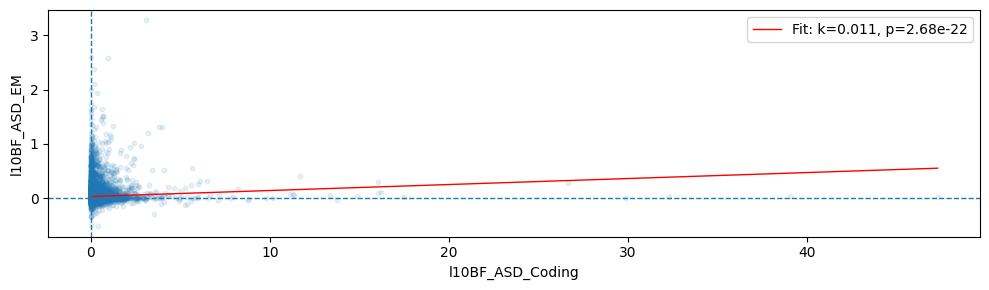

In [129]:
bf_scatter_plot(df, "l10BF_ASD_Coding", "l10BF_ASD_EM", figsize = (10,3))

859
Slope: 0.003, Intercept: 0.081, R: 0.046, p-value: 1.83e-01


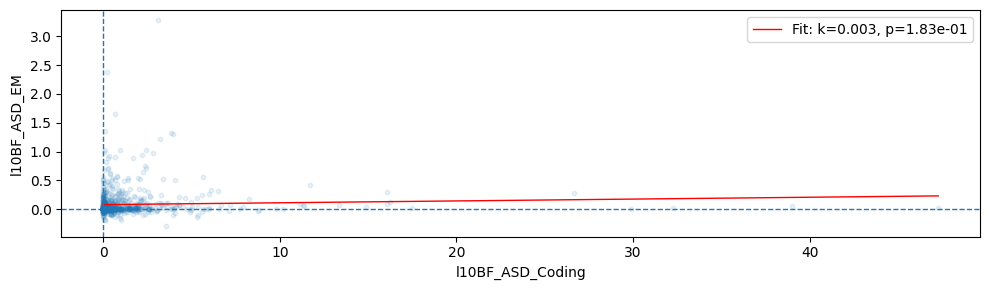

In [130]:
print(df[df["gene"].isin(sfari_genes)].shape[0])
bf_scatter_plot(df[df["gene"].isin(sfari_genes)], "l10BF_ASD_Coding", "l10BF_ASD_EM", figsize = (10,3))

214
Slope: -0.019, Intercept: 0.363, R: -0.199, p-value: 3.42e-03


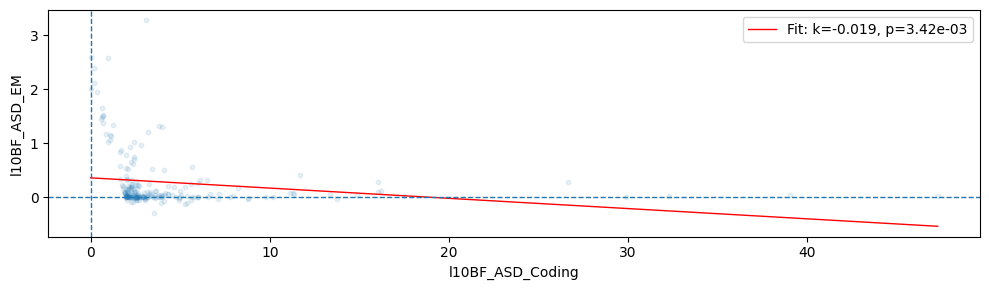

In [557]:
print(df[df["FDR_TADA_ASD_AddEM"] < 0.05].shape[0])
bf_scatter_plot(df[df["FDR_TADA_ASD_AddEM"] < 0.05], "l10BF_ASD_Coding", "l10BF_ASD_EM", figsize = (10,3))

299
Slope: -0.017, Intercept: 0.316, R: -0.172, p-value: 2.92e-03


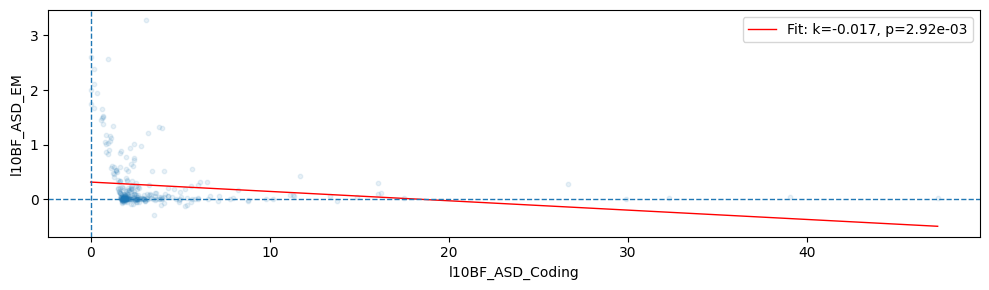

In [558]:
print(df[df["FDR_TADA_ASD_AddEM"] < 0.1].shape[0])
bf_scatter_plot(df[df["FDR_TADA_ASD_AddEM"] < 0.1], "l10BF_ASD_Coding", "l10BF_ASD_EM", figsize = (10,3))

469
Slope: -0.016, Intercept: 0.274, R: -0.150, p-value: 1.16e-03


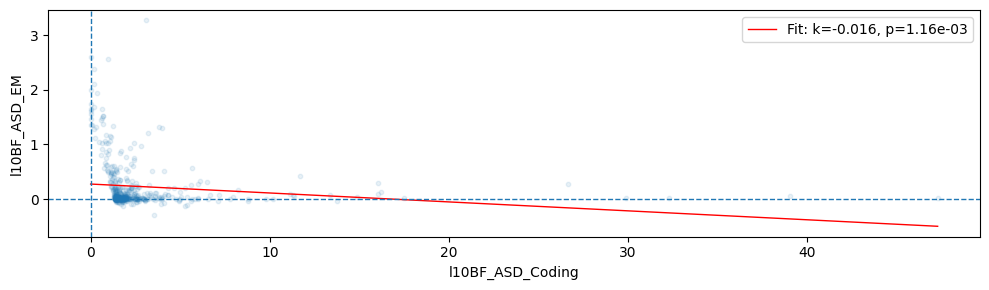

In [559]:
print(df[df["FDR_TADA_ASD_AddEM"] < 0.2].shape[0])
bf_scatter_plot(df[df["FDR_TADA_ASD_AddEM"] < 0.2], "l10BF_ASD_Coding", "l10BF_ASD_EM", figsize = (10,3))

## FuDownsampled coding vs. UCSF noncoding

In [353]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
df = pd.read_csv(dr + "FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503.txt", sep = "\t")
df["log_bf_coding"] = df.apply(lambda x: x["mean_log_bf_SupTable5"] + x["mean_log_bf_SupTable6"], axis = 1)
df["fdr"] = bayesian_fdr(df["bf"].to_numpy(), pi0=0.95)
df[["gene", "fdr", "log_bf_coding", "log_bf_UCSF"]]

,gene,fdr,log_bf_coding,log_bf_UCSF
0,DPM1,0.896849,-0.018644,0.095268
1,SCYL3,0.922465,-0.086194,0.000000
2,C1orf112,0.774192,0.740668,0.000000
3,FGR,0.671075,1.092564,0.135462
4,CFH,0.806921,0.561474,0.000000
...,...,...,...,...
18123,CTB-96E2.2,0.911694,0.000000,0.005382
18124,SNURF,0.903837,0.000000,0.038670
18125,CTC-432M15.3,0.917190,0.000000,0.000000
18126,HOXC4,0.901831,0.048672,0.000000


In [354]:
df.head()

,gene,gene_id,mean_log_bf_SupTable5,std_log_bf_SupTable5,bf_SupTable5,mean_log_bf_SupTable6,std_log_bf_SupTable6,bf_SupTable6,bf.dn.em,bf.in.em,log_bf_UCSF,log_bf,bf,log_bf_coding,fdr
0,DPM1,ENSG00000000419,-0.006039,0.039695,0.993979,-0.012604,0.039796,0.987475,1.0,1.099954,0.095268,0.076625,1.079637,-0.018644,0.896849
1,SCYL3,ENSG00000000457,-0.081336,0.155268,0.921884,-0.004858,0.121946,0.995154,1.0,1.000000,0.000000,-0.086194,0.917416,-0.086194,0.922465
2,C1orf112,ENSG00000000460,0.229190,0.197861,1.257580,0.511479,0.249096,1.667756,1.0,1.000000,0.000000,0.740668,2.097337,0.740668,0.774192
3,FGR,ENSG00000000938,0.476164,0.350523,1.609888,0.616400,0.513439,1.852248,1.0,1.145065,0.135462,1.228026,3.414482,1.092564,0.671075
4,CFH,ENSG00000000971,0.000000,0.000000,1.000000,0.561474,0.848677,1.753255,1.0,1.000000,0.000000,0.561474,1.753255,0.561474,0.806921


Slope: 0.039, Intercept: 0.073, R: 0.091, p-value: 1.18e-34


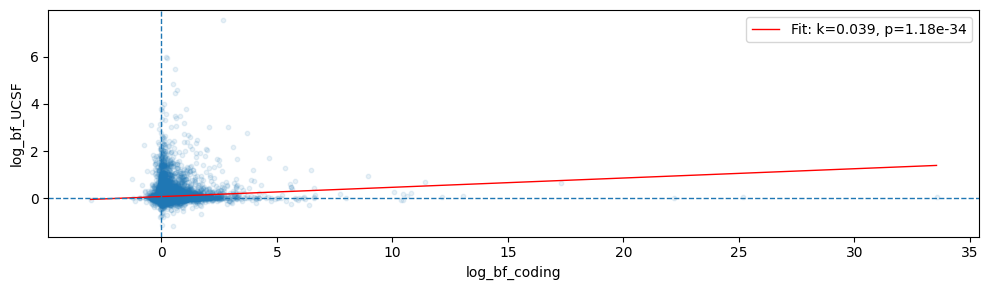

In [355]:
bf_scatter_plot(df, "log_bf_coding", "log_bf_UCSF", figsize = (10,3))

Slope: 0.039, Intercept: 0.073, R: 0.091, p-value: 1.18e-34


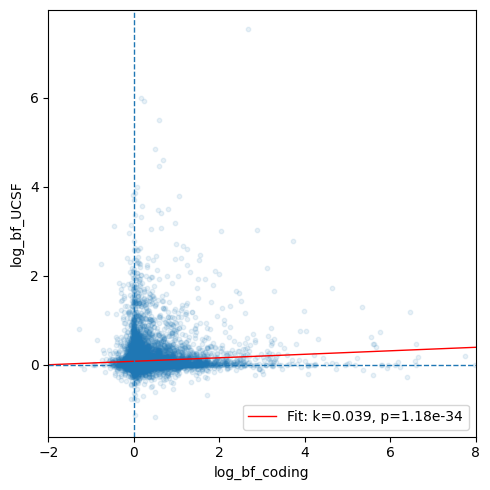

In [359]:
bf_scatter_plot(df, "log_bf_coding", "log_bf_UCSF", figsize = (5,5), xlim = (-2, 8))

859
Slope: 0.017, Intercept: 0.176, R: 0.074, p-value: 3.00e-02


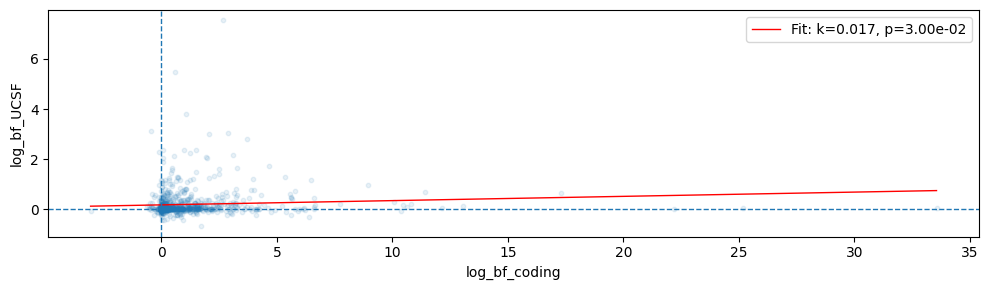

In [135]:
print(df[df["gene"].isin(sfari_genes)].shape[0])
bf_scatter_plot(df[df["gene"].isin(sfari_genes)], "log_bf_coding", "log_bf_UCSF", figsize = (10,3))

61
Slope: -0.152, Intercept: 2.171, R: -0.474, p-value: 1.14e-04


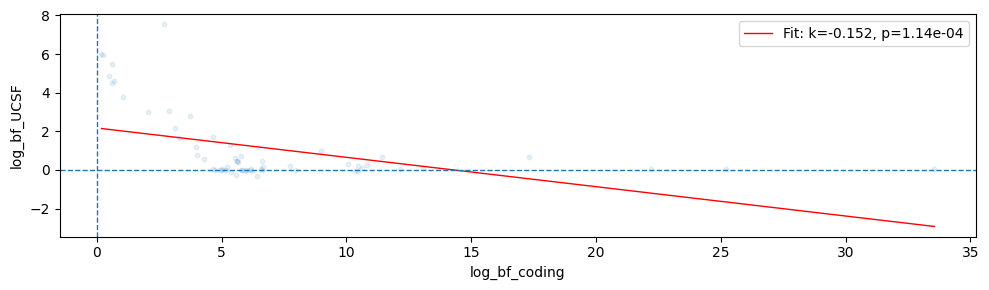

In [587]:
print(df[df["fdr"] < 0.05].shape[0])
bf_scatter_plot(df[df["fdr"] < 0.05], "log_bf_coding", "log_bf_UCSF", figsize = (10,3))

86
Slope: -0.155, Intercept: 2.035, R: -0.468, p-value: 5.43e-06


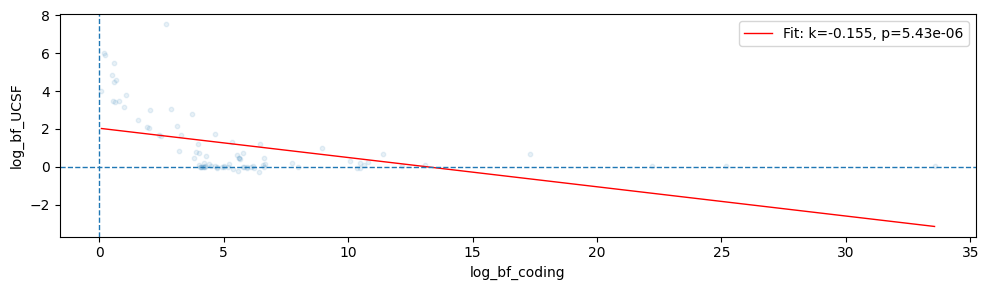

In [588]:
print(df[df["fdr"] < 0.1].shape[0])
bf_scatter_plot(df[df["fdr"] < 0.1], "log_bf_coding", "log_bf_UCSF", figsize = (10,3))

145
Slope: -0.159, Intercept: 1.835, R: -0.453, p-value: 1.05e-08


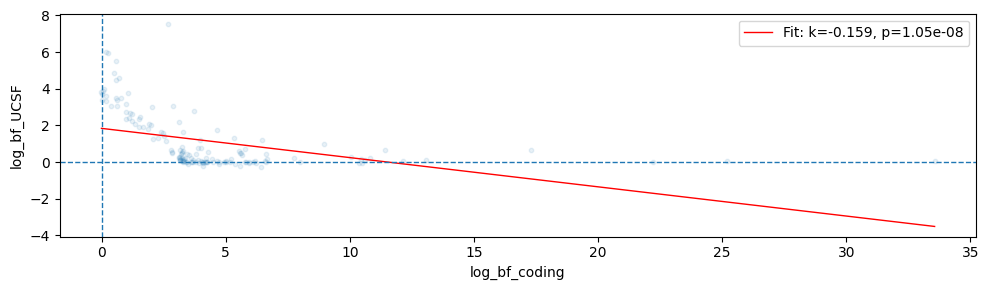

In [589]:
print(df[df["fdr"] < 0.2].shape[0])
bf_scatter_plot(df[df["fdr"] < 0.2], "log_bf_coding", "log_bf_UCSF", figsize = (10,3))

# Prepare NetFlow3D input (in_floor=FALSE)

## Fu's supplementary table 5 (ASC+SSC)

In [ ]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/FuRaw_SupTable5_Downsampled/"
df_output = pd.DataFrame({"gene_id": []})
for x in os.listdir(dr):
    if x.find("infloorFALSE") != -1:
        df = pd.read_csv(dr + x, sep="\t")
        df[f"log(bf_{x.split('_')[1]})"] = df["bf"].apply(lambda x: np.log(x))
        df_output = pd.merge(df_output, df[["gene_id", f"log(bf_{x.split('_')[1]})"]], on="gene_id", how = "outer")
df_output

In [411]:
bf_cols = [c for c in df_output.columns if c.startswith("log(bf_")]
print(len(bf_cols))
df_output["mean_log_bf"] = df_output[bf_cols].mean(axis=1)
df_output["std_log_bf"] = df_output[bf_cols].std(axis=1)
df_output["bf"] = df_output["mean_log_bf"].apply(lambda x: np.exp(x))
df_output

1000


gene_id  log(bf_rep0536)  log(bf_rep0407)  log(bf_rep0942)  \
0      ENSG00000000419        -0.018027         0.042687         0.034160   
1      ENSG00000000457        -0.294065         0.000000         0.048966   
2      ENSG00000000460         0.279147         0.298420         0.329323   
3      ENSG00000000938         0.436560         0.572701         0.924652   
4      ENSG00000000971         0.000000         0.000000         0.000000   
...                ...              ...              ...              ...   
18123  ENSG00000273171         0.000000         0.000000         0.000000   
18124  ENSG00000273173         0.000000         0.000000         0.000000   
18125  ENSG00000273217         0.000000         0.000000         0.000000   
18126  ENSG00000273266        -0.024165         0.012130         0.037616   
18127  ENSG00000273274         0.000000        -0.031986         0.000000   

       log(bf_rep0765)  log(bf_rep0247)  log(bf_rep0049)  log(bf_rep0082)  \
0             0.000000         0.060797        -0.017977         0.034164   
1            -0.188428        -0.187507        -0.294147        -0.203024   
2             0.379596         0.167677         0.197949         0.147960   
3             0.120017         0.424381         0.174269         0.624030   
4             0.000000         0.000000         0.000000         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.119957         0.035150        -0.000718         0.060996   
18127         0.000000        -0.031880         0.000000         0.000000   

       log(bf_rep0264)  log(bf_rep0452)  log(bf_rep0668)  log(bf_rep0597)  \
0            -0.055946        -0.056012        -0.017996         0.060632   
1             0.000000        -0.188373         0.049752         0.063346   
2             0.217715         0.360555         0.167442        -0.195717   
3             0.511443         0.508506        -0.085031         0.324479   
4             0.000000         0.000000         0.000000         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.024985         0.048340         0.060787         0.061137   
18127        -0.031895         0.000000         0.000000        -0.032009   

       log(bf_rep0814)  log(bf_rep0236)  log(bf_rep0943)  log(bf_rep0121)  \
0             0.000000        -0.018006        -0.037996        -0.056071   
1            -0.293288        -0.189412         0.169443         0.063394   
2             0.429906         0.047347         0.067289         0.217176   
3             1.120558         1.009409        -0.201497         0.381480   
4             0.000000         0.000000         0.000000         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.022240         0.073554         0.012074         0.025075   
18127        -0.031941        -0.032089         0.000000         0.000000   

       log(bf_rep0397)  log(bf_rep0399)  log(bf_rep0153)  log(bf_rep0154)  \
0             0.034155         0.000000        -0.056143         0.007581   
1            -0.293982         0.169326        -0.188965         0.062507   
2            -0.114605         0.410910         0.147814         0.379001   
3      

In [412]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_output[["gene_id", "mean_log_bf", "std_log_bf", "bf"]].to_csv(dr + "FuRaw_SupTable5_Downsampled_infloorFALSE_TADA_output.txt", sep="\t", index=False)

In [11]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df = pd.read_csv(dr + "FuRaw_SupTable5_Downsampled_infloorFALSE_TADA_output.txt", sep="\t")
print(df.shape[0])
df[df["mean_log_bf"] < 0]

18128


,gene_id,mean_log_bf,std_log_bf,bf
0,ENSG00000000419,-6.039266e-03,3.969531e-02,0.993979
1,ENSG00000000457,-8.133584e-02,1.552683e-01,0.921884
5,ENSG00000001036,-1.656643e-03,3.184992e-02,0.998345
8,ENSG00000001460,-1.998401e-18,4.466324e-17,1.000000
12,ENSG00000001626,-2.078338e-16,4.202740e-16,1.000000
...,...,...,...,...
18074,ENSG00000269113,-2.764402e-02,2.528394e-01,0.972735
18106,ENSG00000272325,-4.360632e-02,1.025990e-01,0.957331
18109,ENSG00000272514,-4.996004e-18,7.051257e-17,1.000000
18112,ENSG00000272636,-8.838766e-03,3.162237e-02,0.991200


## Fu's supplementary table 6 (SPARK)

In [413]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/FuRaw_SupTable6_Downsampled/"
df_output = pd.DataFrame({"gene_id": []})
for x in os.listdir(dr):
    if x.find("infloorFALSE") != -1:
        df = pd.read_csv(dr + x, sep="\t")
        df[f"log(bf_{x.split('_')[1]})"] = df["bf"].apply(lambda x: np.log(x))
        df_output = pd.merge(df_output, df[["gene_id", f"log(bf_{x.split('_')[1]})"]], on="gene_id", how = "outer")
df_output

gene_id  log(bf_rep0536)  log(bf_rep0407)  log(bf_rep0942)  \
0      ENSG00000000419        -0.017317        -0.055242         0.000000   
1      ENSG00000000457         0.000000        -0.013128         0.000000   
2      ENSG00000000460         0.309829         0.627736         0.490997   
3      ENSG00000000938         0.984559         0.107812         0.466524   
4      ENSG00000000971         0.000000         0.473212         0.000000   
...                ...              ...              ...              ...   
18123  ENSG00000273171         0.000000         0.000000         0.000000   
18124  ENSG00000273173         0.000000         0.000000         0.000000   
18125  ENSG00000273217         0.000000         0.000000         0.000000   
18126  ENSG00000273266        -0.001841        -0.062140         0.023446   
18127  ENSG00000273274        -0.031566        -0.031612        -0.031608   

       log(bf_rep0765)  log(bf_rep0247)  log(bf_rep0049)  log(bf_rep0082)  \
0            -0.037927         0.061086        -0.055186        -0.017371   
1            -0.197500         0.000000        -0.196997         0.000000   
2             0.172771         0.584076         0.538707         0.902160   
3             1.627052         1.083623         0.485220         1.071129   
4             0.171916         0.175492         0.000000         2.231515   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.050014         0.023755        -0.001918         0.109952   
18127         0.000000         0.000000         0.000000        -0.051746   

       log(bf_rep0264)  log(bf_rep0452)  log(bf_rep0668)  log(bf_rep0597)  \
0             0.019957         0.000000         0.043541        -0.061278   
1             0.160062        -0.013147         0.000000         0.000000   
2             0.993500         0.446514         0.491253         0.173489   
3             1.014724         0.811931        -0.123869         0.640692   
4            -0.300710         1.930996         0.000000         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126        -0.002229         0.023596        -0.002197         0.023665   
18127        -0.031592        -0.051896        -0.031556         0.000000   

       log(bf_rep0814)  log(bf_rep0236)  log(bf_rep0943)  log(bf_rep0121)  \
0             0.000000        -0.017344        -0.037860        -0.037924   
1             0.068546        -0.013132         0.160232         0.146636   
2             0.447786         0.583518         0.309792         0.264927   
3             0.699824         1.080747         0.095137         2.781498   
4             1.758303         0.173543         1.457916         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126        -0.002086         0.023957         0.075965        -0.013600   
18127        -0.051640        -0.031532        -0.051889        -0.031623   

       log(bf_rep0397)  log(bf_rep0399)  log(bf_rep0153)  log(bf_rep0154)  \
0            -0.055086        -0.078859        -0.017354        -0.017381   
1             0.000000        -0.197740        -0.196416        -0.196424   
2             0.857332         0.490779         0.310119         0.539018   
3      

In [414]:
bf_cols = [c for c in df_output.columns if c.startswith("log(bf_")]
print(len(bf_cols))
df_output["mean_log_bf"] = df_output[bf_cols].mean(axis=1)
df_output["std_log_bf"] = df_output[bf_cols].std(axis=1)
df_output["bf"] = df_output["mean_log_bf"].apply(lambda x: np.exp(x))
df_output

1000


gene_id  log(bf_rep0536)  log(bf_rep0407)  log(bf_rep0942)  \
0      ENSG00000000419        -0.017317        -0.055242         0.000000   
1      ENSG00000000457         0.000000        -0.013128         0.000000   
2      ENSG00000000460         0.309829         0.627736         0.490997   
3      ENSG00000000938         0.984559         0.107812         0.466524   
4      ENSG00000000971         0.000000         0.473212         0.000000   
...                ...              ...              ...              ...   
18123  ENSG00000273171         0.000000         0.000000         0.000000   
18124  ENSG00000273173         0.000000         0.000000         0.000000   
18125  ENSG00000273217         0.000000         0.000000         0.000000   
18126  ENSG00000273266        -0.001841        -0.062140         0.023446   
18127  ENSG00000273274        -0.031566        -0.031612        -0.031608   

       log(bf_rep0765)  log(bf_rep0247)  log(bf_rep0049)  log(bf_rep0082)  \
0            -0.037927         0.061086        -0.055186        -0.017371   
1            -0.197500         0.000000        -0.196997         0.000000   
2             0.172771         0.584076         0.538707         0.902160   
3             1.627052         1.083623         0.485220         1.071129   
4             0.171916         0.175492         0.000000         2.231515   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.050014         0.023755        -0.001918         0.109952   
18127         0.000000         0.000000         0.000000        -0.051746   

       log(bf_rep0264)  log(bf_rep0452)  log(bf_rep0668)  log(bf_rep0597)  \
0             0.019957         0.000000         0.043541        -0.061278   
1             0.160062        -0.013147         0.000000         0.000000   
2             0.993500         0.446514         0.491253         0.173489   
3             1.014724         0.811931        -0.123869         0.640692   
4            -0.300710         1.930996         0.000000         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126        -0.002229         0.023596        -0.002197         0.023665   
18127        -0.031592        -0.051896        -0.031556         0.000000   

       log(bf_rep0814)  log(bf_rep0236)  log(bf_rep0943)  log(bf_rep0121)  \
0             0.000000        -0.017344        -0.037860        -0.037924   
1             0.068546        -0.013132         0.160232         0.146636   
2             0.447786         0.583518         0.309792         0.264927   
3             0.699824         1.080747         0.095137         2.781498   
4             1.758303         0.173543         1.457916         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126        -0.002086         0.023957         0.075965        -0.013600   
18127        -0.051640        -0.031532        -0.051889        -0.031623   

       log(bf_rep0397)  log(bf_rep0399)  log(bf_rep0153)  log(bf_rep0154)  \
0            -0.055086        -0.078859        -0.017354        -0.017381   
1             0.000000        -0.197740        -0.196416        -0.196424   
2             0.857332         0.490779         0.310119         0.539018   
3      

In [415]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_output[["gene_id", "mean_log_bf", "std_log_bf", "bf"]].to_csv(dr + "FuRaw_SupTable6_Downsampled_infloorFALSE_TADA_output.txt", sep="\t", index=False)

In [12]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df = pd.read_csv(dr + "FuRaw_SupTable6_Downsampled_infloorFALSE_TADA_output.txt", sep="\t")
print(df.shape[0])
df[df["mean_log_bf"] < 0]

18128


,gene_id,mean_log_bf,std_log_bf,bf
0,ENSG00000000419,-1.260432e-02,3.979630e-02,0.987475
1,ENSG00000000457,-4.857932e-03,1.219463e-01,0.995154
6,ENSG00000001084,-1.124644e-01,1.762968e-01,0.893629
8,ENSG00000001460,-1.998401e-18,4.466324e-17,1.000000
9,ENSG00000001461,-1.521951e-02,4.648857e-02,0.984896
...,...,...,...,...
18107,ENSG00000272333,-4.967470e-01,3.656553e-01,0.608507
18110,ENSG00000272573,-9.992007e-19,3.159750e-17,1.000000
18112,ENSG00000272636,-8.758184e-03,3.278633e-02,0.991280
18117,ENSG00000272968,-1.249348e-02,1.847558e-02,0.987584


## Combine the BFs (260503 noncoding BF)

In [423]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_fu_sup5 = pd.read_csv(dr + "FuRaw_SupTable5_Downsampled_infloorFALSE_TADA_output.txt", sep="\t")
df_fu_sup6 = pd.read_csv(dr + "FuRaw_SupTable6_Downsampled_infloorFALSE_TADA_output.txt", sep="\t")
df_ucsf = pd.read_csv(dr + "TADA_NoncodingOnly_Combined_Simple_roulette_rd_control_formatted_260503_infloorFALSE_ScaleByLOEUF.txt", sep="\t")
df_merged = pd.merge(df_fu_sup5, df_fu_sup6, on="gene_id", suffixes=("_SupTable5", "_SupTable6"))
df_merged = pd.merge(df_merged, df_ucsf[["gene", "gene_id", "bf.dn.em", "bf.in.em"]], on="gene_id")
df_merged["log_bf_UCSF"] = df_merged.apply(lambda x: np.log(x["bf.dn.em"] * x["bf.in.em"]), axis=1)
df_merged["log_bf"] = df_merged["mean_log_bf_SupTable5"] + df_merged["mean_log_bf_SupTable6"] + df_merged["log_bf_UCSF"]
df_merged["bf"] = df_merged["log_bf"].apply(lambda x: np.exp(x))
df_merged = df_merged[["gene", "gene_id"] + [c for c in df_merged.columns if c not in ["gene", "gene_id"]]]
df_merged

,gene,gene_id,mean_log_bf_SupTable5,std_log_bf_SupTable5,bf_SupTable5,mean_log_bf_SupTable6,std_log_bf_SupTable6,bf_SupTable6,bf.dn.em,bf.in.em,log_bf_UCSF,log_bf,bf
0,DPM1,ENSG00000000419,-0.006039,0.039695,0.993979,-0.012604,0.039796,0.987475,1.0,1.099954,0.095268,0.076625,1.079637
1,SCYL3,ENSG00000000457,-0.081336,0.155268,0.921884,-0.004858,0.121946,0.995154,1.0,1.000000,0.000000,-0.086194,0.917416
2,C1orf112,ENSG00000000460,0.229190,0.197861,1.257580,0.511479,0.249096,1.667756,1.0,1.000000,0.000000,0.740668,2.097337
3,FGR,ENSG00000000938,0.476164,0.350523,1.609888,0.616400,0.513439,1.852248,1.0,1.145065,0.135462,1.228026,3.414482
4,CFH,ENSG00000000971,0.000000,0.000000,1.000000,0.561474,0.848677,1.753255,1.0,1.000000,0.000000,0.561474,1.753255
...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,CTB-96E2.2,ENSG00000273171,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.005396,0.005382,0.005382,1.005396
18124,SNURF,ENSG00000273173,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.039427,0.038670,0.038670,1.039427
18125,CTC-432M15.3,ENSG00000273217,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.000000,0.000000,0.000000,1.000000
18126,HOXC4,ENSG00000273266,0.030376,0.046465,1.030842,0.018296,0.040622,1.018464,1.0,1.000000,0.000000,0.048672,1.049875


In [424]:
df_merged["bf"].min()

np.float64(0.04363899136873234)

In [425]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_merged.to_csv(dr + "FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503.txt", sep="\t", index=False)

In [72]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df = pd.read_csv(dr + "FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503.txt", sep="\t")
df[df["log_bf"] < 0]

,gene,gene_id,mean_log_bf_SupTable5,std_log_bf_SupTable5,bf_SupTable5,mean_log_bf_SupTable6,std_log_bf_SupTable6,bf_SupTable6,bf.dn.em,bf.in.em,log_bf_UCSF,log_bf,bf
1,SCYL3,ENSG00000000457,-8.133584e-02,1.552683e-01,0.921884,-4.857932e-03,1.219463e-01,0.995154,1.0,1.000000,0.000000,-8.619377e-02,0.917416
6,GCLC,ENSG00000001084,2.102264e-01,2.268845e-01,1.233957,-1.124644e-01,1.762968e-01,0.893629,1.0,0.886555,-0.120412,-2.265032e-02,0.977604
8,STPG1,ENSG00000001460,-1.998401e-18,4.466324e-17,1.000000,-1.998401e-18,4.466324e-17,1.000000,1.0,1.000000,0.000000,-3.996803e-18,1.000000
14,CYP51A1,ENSG00000001630,-4.315528e-03,6.152240e-03,0.995694,0.000000e+00,0.000000e+00,1.000000,1.0,1.000000,0.000000,-4.315528e-03,0.995694
20,AOC1,ENSG00000002726,3.941756e-04,3.477284e-02,1.000394,1.985511e-02,3.442674e-02,1.020054,1.0,0.943225,-0.058451,-3.820142e-02,0.962519
...,...,...,...,...,...,...,...,...,...,...,...,...,...
18109,C6ORF165,ENSG00000272514,-4.996004e-18,7.051257e-17,1.000000,0.000000e+00,0.000000e+00,1.000000,1.0,1.000000,0.000000,-4.996004e-18,1.000000
18110,MUSTN1,ENSG00000272573,0.000000e+00,0.000000e+00,1.000000,-9.992007e-19,3.159750e-17,1.000000,1.0,0.998641,-0.001360,-1.360225e-03,0.998641
18117,RBAK-RBAKDN,ENSG00000272968,0.000000e+00,0.000000e+00,1.000000,-1.249348e-02,1.847558e-02,0.987584,1.0,0.856490,-0.154913,-1.674066e-01,0.845856
18122,RP11-201K10.3,ENSG00000273088,0.000000e+00,0.000000e+00,1.000000,0.000000e+00,0.000000e+00,1.000000,1.0,0.993351,-0.006672,-6.671530e-03,0.993351


In [73]:
df["log_bf"].min()

np.float64(-3.1318042308248715)

In [74]:
df["bf"].min()

np.float64(0.0436389913687323)

In [75]:
df.loc[df["log_bf"] < 0, "log_bf"] = 0
df.loc[df["bf"] < 1, "bf"] = 1
print(df["log_bf"].min(), df["bf"].min())

0.0 1.0


In [77]:
dr

'/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/'

In [76]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df.to_csv(dr + "FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503_floored_260510.txt", sep="\t", index=False)

In [ ]:
# run NetFlow3D
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503_floored_260510.txt 5 0.5
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503_floored_260510.txt 1 0.5
#  $1 = tada_output_path; $2 = tada_output_suffix; $3 = weighted_edge [optional]; $4 = restart_prob [optional]; $5 = disrupt_edges [optional]; $6 = binary_interactome [optional]; $7 = expressed_genes [optional];


In [163]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/NetFlow3D/output/"
for ew in [5, 1]:
    df = pd.read_csv(dr + f"InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503_floored_260510_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew{ew}_rp0.5_subnetworks.txt", sep="\t")
    print(f"ew={ew}", df[df["Subnetwork_size"] > 5].shape[0], df[df["Subnetwork_size"] > 5]["Subnetwork_size"].sum())

ew=5 8 84
ew=1 8 82


## Combine the BFs (260523)

In [198]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/Combined_FuRaw_SupTable5_SupTable6_Downsampled/"
df = pd.read_csv(dr + "Downsampled_rep0000_infloorFALSE_TADA_output.txt", sep="\t")
df

,gene_id,gene,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf,fdr,pval
0,ENSG00000108510,MED13,0.030,1.000000e+00,1.0,1.000000,1.000000,0.967761,1.0,1.037948,1.004485,0.910400,0.412162
1,ENSG00000164190,NIPBL,0.032,1.000000e+00,1.0,1.000000,1.000000,0.813474,1.0,1.015311,0.825929,0.932437,0.927033
2,ENSG00000108055,SMC3,0.037,1.000000e+00,1.0,1.000000,6.999374,0.388197,1.0,0.852300,2.315818,0.696410,0.037520
3,ENSG00000125107,CNOT1,0.038,1.000000e+00,1.0,0.456248,6.407608,0.834120,1.0,1.499536,3.656638,0.618680,0.023037
4,ENSG00000117000,RLF,0.040,1.000000e+00,1.0,1.000000,1.000000,1.000000,1.0,0.952637,0.952637,0.930468,0.850017
...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,ENSG00000150244,TRIM48,1.985,1.099500e-27,1.0,1.000000,1.000000,1.000000,1.0,1.000000,1.000000,0.926680,0.712472
18124,ENSG00000231924,PSG1,1.986,1.624200e-29,1.0,1.000000,1.000000,1.000000,1.0,1.000000,1.000000,0.916006,0.483132
18125,ENSG00000163386,NBPF10,1.988,4.100800e-85,1.0,1.000000,1.000000,1.000000,1.0,1.000000,1.000000,0.926682,0.712529
18126,ENSG00000099949,LZTR1,1.994,1.021100e-92,1.0,1.000000,1.000000,1.000000,1.0,1.095453,1.095453,0.889697,0.259724


In [ ]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/Combined_FuRaw_SupTable5_SupTable6_Downsampled/"
df_output = pd.DataFrame({"gene_id": []})
for x in os.listdir(dr):
    if x.find("infloorFALSE") != -1:
        df = pd.read_csv(dr + x, sep="\t")
        for col in [""]
        df[f"log(bf_{x.split('_')[1]})"] = df["bf"].apply(lambda x: np.log(x))
        df_output = pd.merge(df_output, df[["gene_id", f"log(bf_{x.split('_')[1]})"]], on="gene_id", how = "outer")
df_output

gene_id  log(bf_rep0536)  log(bf_rep0407)  log(bf_rep0942)  \
0      ENSG00000000419        -0.040005        -0.025581         0.014375   
1      ENSG00000000457        -0.386494        -0.018443        -0.047865   
2      ENSG00000000460         0.442896         0.814190         0.687493   
3      ENSG00000000938         0.921313         0.423547         0.982035   
4      ENSG00000000971         0.000000         0.434194         0.000000   
...                ...              ...              ...              ...   
18123  ENSG00000273171         0.000000         0.000000         0.000000   
18124  ENSG00000273173         0.000000         0.000000         0.000000   
18125  ENSG00000273217         0.000000         0.000000         0.000000   
18126  ENSG00000273266        -0.016784        -0.049202         0.064171   
18127  ENSG00000273274        -0.042555        -0.071528        -0.042573   

       log(bf_rep0765)  log(bf_rep0247)  log(bf_rep0049)  log(bf_rep0082)  \
0            -0.050821         0.113397        -0.090802        -0.009176   
1            -0.386547        -0.252726        -0.518583        -0.272068   
2             0.451408         0.633782         0.560920         0.860893   
3             1.355612         1.165795         0.465383         1.353194   
4             0.055126         0.058560         0.000000         2.076518   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.145733         0.048032        -0.000403         0.162045   
18127         0.000000        -0.042359         0.000000        -0.071431   

       log(bf_rep0264)  log(bf_rep0452)  log(bf_rep0668)  log(bf_rep0597)  \
0            -0.059048        -0.074474         0.008018        -0.019058   
1             0.103449        -0.272698        -0.047012        -0.028650   
2             1.050712         0.615864         0.578424        -0.083830   
3             1.295115         0.975554        -0.422488         0.588979   
4            -0.377669         1.698005         0.000000         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.032016         0.064479         0.064422         0.080792   
18127        -0.071451        -0.071501        -0.042479        -0.042489   

       log(bf_rep0814)  log(bf_rep0236)  log(bf_rep0943)  log(bf_rep0121)  \
0             0.000000        -0.040007        -0.084257        -0.108071   
1            -0.291331        -0.273150         0.328689         0.177379   
2             0.751935         0.434241         0.270431         0.396572   
3             1.476459         1.721016        -0.458631         2.608125   
4             1.642325         0.054835         1.264638         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.015575         0.096976         0.064416         0.015804   
18127        -0.100287        -0.071550        -0.071452        -0.042575   

       log(bf_rep0397)  log(bf_rep0399)  log(bf_rep0153)  log(bf_rep0154)  \
0            -0.042785        -0.108042        -0.090777        -0.042880   
1            -0.385907        -0.029092        -0.386248        -0.161393   
2             0.561288         0.742426         0.324959         0.742263   
3      

In [ ]:
bf_cols = [c for c in df_output.columns if c.startswith("log(bf_")]
print(len(bf_cols))
df_output["mean_log_bf"] = df_output[bf_cols].mean(axis=1)
df_output["std_log_bf"] = df_output[bf_cols].std(axis=1)
df_output["bf"] = df_output["mean_log_bf"].apply(lambda x: np.exp(x))
df_output


In [ ]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_output[["gene_id", "mean_log_bf", "std_log_bf", "bf"]].to_csv(dr + "FuRaw_SupTable5_Downsampled_infloorFALSE_TADA_output.txt", sep="\t", index=False)
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df = pd.read_csv(dr + "FuRaw_SupTable5_Downsampled_infloorFALSE_TADA_output.txt", sep="\t")
print(df.shape[0])
df[df["mean_log_bf"] < 0]

## Calculate FDR

In [432]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_merged = pd.read_csv(dr + "FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503.txt", sep="\t")
df_merged["log_bf_coding"] = df_merged["mean_log_bf_SupTable5"] + df_merged["mean_log_bf_SupTable6"]
df_merged["bf_coding"] = df_merged["log_bf_coding"].apply(lambda x: np.exp(x))
df_merged["FDR_coding"] = bayesian_fdr(df_merged["bf_coding"].to_numpy(), pi0=0.95)
df_merged["FDR_addEM"] = bayesian_fdr(df_merged["bf"].to_numpy(), pi0=0.95)
df_merged

,gene,gene_id,mean_log_bf_SupTable5,std_log_bf_SupTable5,bf_SupTable5,mean_log_bf_SupTable6,std_log_bf_SupTable6,bf_SupTable6,bf.dn.em,bf.in.em,log_bf_UCSF,log_bf,bf,log_bf_coding,bf_coding,FDR_coding,FDR_addEM
0,DPM1,ENSG00000000419,-0.006039,0.039695,0.993979,-0.012604,0.039796,0.987475,1.0,1.099954,0.095268,0.076625,1.079637,-0.018644,0.981529,0.929983,0.896849
1,SCYL3,ENSG00000000457,-0.081336,0.155268,0.921884,-0.004858,0.121946,0.995154,1.0,1.000000,0.000000,-0.086194,0.917416,-0.086194,0.917416,0.931007,0.922465
2,C1orf112,ENSG00000000460,0.229190,0.197861,1.257580,0.511479,0.249096,1.667756,1.0,1.000000,0.000000,0.740668,2.097337,0.740668,2.097337,0.783265,0.774192
3,FGR,ENSG00000000938,0.476164,0.350523,1.609888,0.616400,0.513439,1.852248,1.0,1.145065,0.135462,1.228026,3.414482,1.092564,2.981911,0.701692,0.671075
4,CFH,ENSG00000000971,0.000000,0.000000,1.000000,0.561474,0.848677,1.753255,1.0,1.000000,0.000000,0.561474,1.753255,0.561474,1.753255,0.816733,0.806921
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,CTB-96E2.2,ENSG00000273171,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.005396,0.005382,0.005382,1.005396,0.000000,1.000000,0.922989,0.911694
18124,SNURF,ENSG00000273173,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.039427,0.038670,0.038670,1.039427,0.000000,1.000000,0.926170,0.903837
18125,CTC-432M15.3,ENSG00000273217,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.926172,0.917190
18126,HOXC4,ENSG00000273266,0.030376,0.046465,1.030842,0.018296,0.040622,1.018464,1.0,1.000000,0.000000,0.048672,1.049875,0.048672,1.049875,0.909209,0.901831


In [433]:
df_merged[df_merged["FDR_coding"] < 0.05].shape[0]

46

In [434]:
df_merged[df_merged["FDR_addEM"] < 0.05].shape[0]

61

# Prepare NetFlow3D input

## Fu's supplementary table 5 (ASC+SSC)

In [ ]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/FuRaw_SupTable5_Downsampled/"
df_output = pd.DataFrame({"gene_id": []})
for x in os.listdir(dr):
    df = pd.read_csv(dr + x, sep="\t")
    df[f"log(bf_{x.split('_')[-3]})"] = df["bf"].apply(lambda x: np.log(x))
    df_output = pd.merge(df_output, df[["gene_id", f"log(bf_{x.split('_')[-3]})"]], on="gene_id", how = "outer")
df_output

In [94]:
bf_cols = [c for c in df_output.columns if c.startswith("log(bf_")]
print(len(bf_cols))
df_output["mean_log_bf"] = df_output[bf_cols].mean(axis=1)
df_output["std_log_bf"] = df_output[bf_cols].std(axis=1)
df_output["bf"] = df_output["mean_log_bf"].apply(lambda x: np.exp(x))
df_output

1000


gene_id  log(bf_rep0518)  log(bf_rep0311)  log(bf_rep0805)  \
0      ENSG00000000419         0.000000         0.000000         0.000000   
1      ENSG00000000457         0.063346         0.000000         0.000000   
2      ENSG00000000460         0.179009         0.147893         0.460794   
3      ENSG00000000938         0.687612         0.135277         0.288593   
4      ENSG00000000971         0.000000         0.000000         0.000000   
...                ...              ...              ...              ...   
18123  ENSG00000273171         0.000000         0.000000         0.000000   
18124  ENSG00000273173         0.000000         0.000000         0.000000   
18125  ENSG00000273217         0.000000         0.000000         0.000000   
18126  ENSG00000273266         0.048052         0.024851         0.002002   
18127  ENSG00000273274         0.000000         0.000000         0.000000   

       log(bf_rep0749)  log(bf_rep0647)  log(bf_rep0866)  log(bf_rep0010)  \
0             0.000000         0.000000         0.060511         0.000000   
1             0.000000         0.063820         0.000000         0.063174   
2             0.198255         0.429827         0.378982         0.329252   
3             0.000000         0.791473         0.378586         0.571876   
4             0.000000         0.000000         0.000000         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.060578         0.074038         0.012056         0.060959   
18127         0.000000         0.000000         0.000000         0.000000   

       log(bf_rep0182)  log(bf_rep0924)  log(bf_rep0121)  log(bf_rep0962)  \
0             0.000000         0.000000         0.000000         0.000000   
1             0.063944         0.000000         0.063394         0.167724   
2             0.198405         0.379513         0.217176         0.247732   
3             0.205020         0.341173         0.381480         0.292385   
4             0.000000         0.000000         0.000000         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.071330         0.035439         0.025075         0.000000   
18127         0.000000         0.000000         0.000000         0.000000   

       log(bf_rep0757)  log(bf_rep0086)  log(bf_rep0759)  log(bf_rep0896)  \
0             0.000000         0.000000         0.000000         0.000000   
1             0.000000         0.000000         0.000000         0.000000   
2             0.460674         0.117487         0.000000         0.016680   
3             0.093152         0.099547         0.109823         0.866891   
4             0.000000         0.000000         0.000000         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.000000         0.035267         0.132847         0.012397   
18127         0.000000         0.000000         0.000000         0.000000   

       log(bf_rep0664)  log(bf_rep0132)  log(bf_rep0968)  log(bf_rep0773)  \
0             0.000000         0.000000         0.000000         0.000000   
1             0.000000         0.062706         0.000000         0.000000   
2             0.117072         0.000000         0.066347         0.000000   
3      

In [ ]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_output[["gene_id", "mean_log_bf", "std_log_bf", "bf"]].to_csv(dr + "FuRaw_SupTable5_Downsampled_TADA_output.txt", sep="\t", index=False)

## Fu's supplementary table 6 (SPARK)

In [ ]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/FuRaw_SupTable6_Downsampled/"
df_output = pd.DataFrame({"gene_id": []})
for x in os.listdir(dr):
    df = pd.read_csv(dr + x, sep="\t")
    df[f"log(bf_{x.split('_')[-3]})"] = df["bf"].apply(lambda x: np.log(x))
    df_output = pd.merge(df_output, df[["gene_id", f"log(bf_{x.split('_')[-3]})"]], on="gene_id", how = "outer")
df_output

gene_id  log(bf_rep0518)  log(bf_rep0311)  log(bf_rep0805)  \
0      ENSG00000000419         0.037327         0.000000         0.060781   
1      ENSG00000000457         0.000000         0.000000         0.000000   
2      ENSG00000000460         0.309678         1.177883         0.401510   
3      ENSG00000000938         0.434927         0.191567         0.686890   
4      ENSG00000000971         0.000000         0.000000         0.000000   
...                ...              ...              ...              ...   
18123  ENSG00000273171         0.000000         0.000000         0.000000   
18124  ENSG00000273173         0.000000         0.000000         0.000000   
18125  ENSG00000273217         0.000000         0.000000         0.000000   
18126  ENSG00000273266         0.035018         0.023804         0.000000   
18127  ENSG00000273274         0.000000         0.000000         0.000000   

       log(bf_rep0749)  log(bf_rep0647)  log(bf_rep0866)  log(bf_rep0010)  \
0             0.037332         0.000000         0.000000         0.000000   
1             0.000000         0.000000         0.000000         0.000000   
2             0.538602         0.172465         0.266073         0.538120   
3             0.167989         1.205334         0.981658         0.838696   
4             0.473212         0.000000         0.000000         0.473212   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.012163         0.000000         0.000000         0.000000   
18127         0.000000         0.000000         0.000000         0.000000   

       log(bf_rep0182)  log(bf_rep0924)  log(bf_rep0121)  log(bf_rep0962)  \
0             0.000000         0.000000         0.000000         0.060803   
1             0.000000         0.000000         0.159775         0.000000   
2             0.490989         0.446061         0.264927         0.401594   
3             0.144947         0.322129         2.781498         1.433696   
4             0.000000         0.000000         0.000000         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.000000         0.023711         0.000000         0.000000   
18127         0.000000         0.000000         0.000000         0.000000   

       log(bf_rep0757)  log(bf_rep0086)  log(bf_rep0759)  log(bf_rep0896)  \
0             0.000000         0.060864         0.060916         0.000000   
1             0.160100         0.000000         0.160418         0.000000   
2             0.172960         0.538594         0.491270         0.309191   
3             0.325123         0.268630         0.435269         0.458641   
4             2.231515         1.758303         0.000000         0.473212   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.000000         0.000000         0.072727         0.024030   
18127         0.000000         0.000000         0.000000         0.000000   

       log(bf_rep0664)  log(bf_rep0132)  log(bf_rep0968)  log(bf_rep0773)  \
0             0.000000         0.000000         0.000000         0.000000   
1             0.159512         0.000000         0.000000         0.000000   
2             0.719682         0.583581         0.993681         1.174811   
3      

In [97]:
bf_cols = [c for c in df_output.columns if c.startswith("log(bf_")]
print(len(bf_cols))
df_output["mean_log_bf"] = df_output[bf_cols].mean(axis=1)
df_output["std_log_bf"] = df_output[bf_cols].std(axis=1)
df_output["bf"] = df_output["mean_log_bf"].apply(lambda x: np.exp(x))
df_output

1000


gene_id  log(bf_rep0518)  log(bf_rep0311)  log(bf_rep0805)  \
0      ENSG00000000419         0.037327         0.000000         0.060781   
1      ENSG00000000457         0.000000         0.000000         0.000000   
2      ENSG00000000460         0.309678         1.177883         0.401510   
3      ENSG00000000938         0.434927         0.191567         0.686890   
4      ENSG00000000971         0.000000         0.000000         0.000000   
...                ...              ...              ...              ...   
18123  ENSG00000273171         0.000000         0.000000         0.000000   
18124  ENSG00000273173         0.000000         0.000000         0.000000   
18125  ENSG00000273217         0.000000         0.000000         0.000000   
18126  ENSG00000273266         0.035018         0.023804         0.000000   
18127  ENSG00000273274         0.000000         0.000000         0.000000   

       log(bf_rep0749)  log(bf_rep0647)  log(bf_rep0866)  log(bf_rep0010)  \
0             0.037332         0.000000         0.000000         0.000000   
1             0.000000         0.000000         0.000000         0.000000   
2             0.538602         0.172465         0.266073         0.538120   
3             0.167989         1.205334         0.981658         0.838696   
4             0.473212         0.000000         0.000000         0.473212   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.012163         0.000000         0.000000         0.000000   
18127         0.000000         0.000000         0.000000         0.000000   

       log(bf_rep0182)  log(bf_rep0924)  log(bf_rep0121)  log(bf_rep0962)  \
0             0.000000         0.000000         0.000000         0.060803   
1             0.000000         0.000000         0.159775         0.000000   
2             0.490989         0.446061         0.264927         0.401594   
3             0.144947         0.322129         2.781498         1.433696   
4             0.000000         0.000000         0.000000         0.000000   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.000000         0.023711         0.000000         0.000000   
18127         0.000000         0.000000         0.000000         0.000000   

       log(bf_rep0757)  log(bf_rep0086)  log(bf_rep0759)  log(bf_rep0896)  \
0             0.000000         0.060864         0.060916         0.000000   
1             0.160100         0.000000         0.160418         0.000000   
2             0.172960         0.538594         0.491270         0.309191   
3             0.325123         0.268630         0.435269         0.458641   
4             2.231515         1.758303         0.000000         0.473212   
...                ...              ...              ...              ...   
18123         0.000000         0.000000         0.000000         0.000000   
18124         0.000000         0.000000         0.000000         0.000000   
18125         0.000000         0.000000         0.000000         0.000000   
18126         0.000000         0.000000         0.072727         0.024030   
18127         0.000000         0.000000         0.000000         0.000000   

       log(bf_rep0664)  log(bf_rep0132)  log(bf_rep0968)  log(bf_rep0773)  \
0             0.000000         0.000000         0.000000         0.000000   
1             0.159512         0.000000         0.000000         0.000000   
2             0.719682         0.583581         0.993681         1.174811   
3      

In [ ]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_output[["gene_id", "mean_log_bf", "std_log_bf", "bf"]].to_csv(dr + "FuRaw_SupTable6_Downsampled_TADA_output.txt", sep="\t", index=False)

## Combine the BFs (260503 noncoding BF)

In [304]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_fu_sup5 = pd.read_csv(dr + "FuRaw_SupTable5_Downsampled_TADA_output.txt", sep="\t")
df_fu_sup6 = pd.read_csv(dr + "FuRaw_SupTable6_Downsampled_TADA_output.txt", sep="\t")
df_ucsf = pd.read_csv(dr + "TADA_coding_FuRaw_ASC+SSC_Combined_Simple_roulette_rd_control_formatted_260503_ScaleByLOEUF.txt", sep="\t")
df_merged = pd.merge(df_fu_sup5, df_fu_sup6, on="gene_id", suffixes=("_SupTable5", "_SupTable6"))
df_merged = pd.merge(df_merged, df_ucsf[["gene", "gene_id", "bf.dn.em", "bf.in.em"]], on="gene_id")
df_merged["log_bf_UCSF"] = df_merged.apply(lambda x: np.log(x["bf.dn.em"] * x["bf.in.em"]), axis=1)
df_merged["log_bf"] = df_merged["mean_log_bf_SupTable5"] + df_merged["mean_log_bf_SupTable6"] + df_merged["log_bf_UCSF"]
df_merged["bf"] = df_merged["log_bf"].apply(lambda x: np.exp(x))
df_merged = df_merged[["gene", "gene_id"] + [c for c in df_merged.columns if c not in ["gene", "gene_id"]]]
df_merged

,gene,gene_id,mean_log_bf_SupTable5,std_log_bf_SupTable5,bf_SupTable5,mean_log_bf_SupTable6,std_log_bf_SupTable6,bf_SupTable6,bf.dn.em,bf.in.em,log_bf_UCSF,log_bf,bf
0,DPM1,ENSG00000000419,0.015410,0.023685,1.015529,0.013939,0.023075,1.014037,1.0,1.099954,0.095268,0.124617,1.132715
1,SCYL3,ENSG00000000457,0.030237,0.055194,1.030699,0.042585,0.067101,1.043505,1.0,1.000000,0.000000,0.072822,1.075539
2,C1orf112,ENSG00000000460,0.238742,0.182634,1.269651,0.511776,0.248453,1.668251,1.0,1.000000,0.000000,0.750518,2.118096
3,FGR,ENSG00000000938,0.500059,0.317694,1.648818,0.660501,0.453203,1.935762,1.0,1.145065,0.135462,1.296021,3.654726
4,CFH,ENSG00000000971,0.000000,0.000000,1.000000,0.661201,0.836869,1.937118,1.0,1.000000,0.000000,0.661201,1.937118
...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,CTB-96E2.2,ENSG00000273171,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.005396,0.005382,0.005382,1.005396
18124,SNURF,ENSG00000273173,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.039427,0.038670,0.038670,1.039427
18125,CTC-432M15.3,ENSG00000273217,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.000000,0.000000,0.000000,1.000000
18126,HOXC4,ENSG00000273266,0.037342,0.037471,1.038048,0.026251,0.031481,1.026599,1.0,1.000000,0.000000,0.063593,1.065659


In [305]:
df_merged["bf"].min()

np.float64(1.0)

In [306]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_merged.to_csv(dr + "FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_260503.txt", sep="\t", index=False)

## Combine the BFs (old noncoding BF)

In [ ]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_fu_sup5 = pd.read_csv(dr + "FuRaw_SupTable5_Downsampled_TADA_output.txt", sep="\t")
df_fu_sup6 = pd.read_csv(dr + "FuRaw_SupTable6_Downsampled_TADA_output.txt", sep="\t")
df_ucsf = pd.read_csv(dr + "TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt", sep="\t")
df_merged = pd.merge(df_fu_sup5, df_fu_sup6, on="gene_id", suffixes=("_SupTable5", "_SupTable6"))
df_merged = pd.merge(df_merged, df_ucsf[["gene_id", "BF_ASD_EM"]], on="gene_id")
df_merged["log_bf_UCSF"] = df_merged["BF_ASD_EM"].apply(lambda x: np.log(x))
df_merged["log_bf"] = df_merged["mean_log_bf_SupTable5"] + df_merged["mean_log_bf_SupTable6"] + df_merged["log_bf_UCSF"]
df_merged["bf"] = df_merged["log_bf"].apply(lambda x: np.exp(x))
df_merged

,gene_id,mean_log_bf_SupTable5,std_log_bf_SupTable5,bf_SupTable5,mean_log_bf_SupTable6,std_log_bf_SupTable6,bf_SupTable6,BF_ASD_EM,log_bf_UCSF,log_bf,bf
0,ENSG00000000419,0.015410,0.023685,1.015529,0.013939,0.023075,1.014037,1.100054,0.095359,0.124708,1.132817
1,ENSG00000000457,0.030237,0.055194,1.030699,0.042585,0.067101,1.043505,1.000000,0.000000,0.072822,1.075539
2,ENSG00000000460,0.238742,0.182634,1.269651,0.511776,0.248453,1.668251,1.000000,0.000000,0.750518,2.118096
3,ENSG00000000938,0.500059,0.317694,1.648818,0.660501,0.453203,1.935762,1.145976,0.136257,1.296817,3.657635
4,ENSG00000000971,0.000000,0.000000,1.000000,0.661201,0.836869,1.937118,1.000000,0.000000,0.661201,1.937118
...,...,...,...,...,...,...,...,...,...,...,...
18123,ENSG00000273171,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.005434,0.005419,0.005419,1.005434
18124,ENSG00000273173,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.039706,0.038938,0.038938,1.039706
18125,ENSG00000273217,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000
18126,ENSG00000273266,0.037342,0.037471,1.038048,0.026251,0.031481,1.026599,1.000000,0.000000,0.063593,1.065659


In [100]:
df_merged["bf"].min()

np.float64(1.0)

In [ ]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_merged.to_csv(dr + "FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output.txt", sep="\t", index=False)

## Calculate FDR (260503)

In [54]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_merged = pd.read_csv(dr + "FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_260503.txt", sep="\t")
df_merged["log_bf_coding"] = df_merged["mean_log_bf_SupTable5"] + df_merged["mean_log_bf_SupTable6"]
df_merged["bf_coding"] = df_merged["log_bf_coding"].apply(lambda x: np.exp(x))
df_merged["FDR_coding"] = bayesian_fdr(df_merged["bf_coding"].to_numpy(), pi0=0.95)
df_merged["FDR_addEM"] = bayesian_fdr(df_merged["bf"].to_numpy(), pi0=0.95)
df_merged

,gene_id,mean_log_bf_SupTable5,std_log_bf_SupTable5,bf_SupTable5,mean_log_bf_SupTable6,std_log_bf_SupTable6,bf_SupTable6,bf.dn.em,bf.in.em,log_bf_UCSF,log_bf,bf,log_bf_coding,bf_coding,FDR_coding,FDR_addEM
0,ENSG00000000419,0.015410,0.023685,1.015529,0.013939,0.023075,1.014037,1.0,1.099954,0.095268,0.124617,1.132715,0.029349,1.029783,0.910720,0.886247
1,ENSG00000000457,0.030237,0.055194,1.030699,0.042585,0.067101,1.043505,1.0,1.000000,0.000000,0.072822,1.075539,0.072822,1.075539,0.903529,0.894763
2,ENSG00000000460,0.238742,0.182634,1.269651,0.511776,0.248453,1.668251,1.0,1.000000,0.000000,0.750518,2.118096,0.750518,2.118096,0.783158,0.771031
3,ENSG00000000938,0.500059,0.317694,1.648818,0.660501,0.453203,1.935762,1.0,1.145065,0.135462,1.296021,3.654726,1.160560,3.191719,0.692396,0.660444
4,ENSG00000000971,0.000000,0.000000,1.000000,0.661201,0.836869,1.937118,1.0,1.000000,0.000000,0.661201,1.937118,0.661201,1.937118,0.798192,0.786853
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,ENSG00000273171,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.005396,0.005382,0.005382,1.005396,0.000000,1.000000,0.916103,0.908377
18124,ENSG00000273173,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.039427,0.038670,0.038670,1.039427,0.000000,1.000000,0.926476,0.900880
18125,ENSG00000273217,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.926502,0.917065
18126,ENSG00000273266,0.037342,0.037471,1.038048,0.026251,0.031481,1.026599,1.0,1.000000,0.000000,0.063593,1.065659,0.063593,1.065659,0.905020,0.896385


In [55]:
df_merged[df_merged["FDR_coding"] < 0.05].shape[0]

50

In [56]:
df_merged[df_merged["FDR_addEM"] < 0.05].shape[0]

67

In [57]:
(67-50) / 50

0.34

In [58]:
185 * 1.34

247.9

## Calculate FDR

In [48]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df_merged = pd.read_csv(dr + "FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output.txt", sep="\t")
df_merged["log_bf_coding"] = df_merged["mean_log_bf_SupTable5"] + df_merged["mean_log_bf_SupTable6"]
df_merged["bf_coding"] = df_merged["log_bf_coding"].apply(lambda x: np.exp(x))
df_merged["FDR_coding"] = bayesian_fdr(df_merged["bf_coding"].to_numpy(), pi0=0.95)
df_merged["FDR_addEM"] = bayesian_fdr(df_merged["bf"].to_numpy(), pi0=0.95)
df_merged

,gene_id,mean_log_bf_SupTable5,std_log_bf_SupTable5,bf_SupTable5,mean_log_bf_SupTable6,std_log_bf_SupTable6,bf_SupTable6,BF_ASD_EM,log_bf_UCSF,log_bf,bf,log_bf_coding,bf_coding,FDR_coding,FDR_addEM
0,ENSG00000000419,0.015410,0.023685,1.015529,0.013939,0.023075,1.014037,1.100054,0.095359,0.124708,1.132817,0.029349,1.029783,0.910720,0.888015
1,ENSG00000000457,0.030237,0.055194,1.030699,0.042585,0.067101,1.043505,1.000000,0.000000,0.072822,1.075539,0.072822,1.075539,0.903529,0.896387
2,ENSG00000000460,0.238742,0.182634,1.269651,0.511776,0.248453,1.668251,1.000000,0.000000,0.750518,2.118096,0.750518,2.118096,0.783158,0.773924
3,ENSG00000000938,0.500059,0.317694,1.648818,0.660501,0.453203,1.935762,1.145976,0.136257,1.296817,3.657635,1.160560,3.191719,0.692396,0.663000
4,ENSG00000000971,0.000000,0.000000,1.000000,0.661201,0.836869,1.937118,1.000000,0.000000,0.661201,1.937118,0.661201,1.937118,0.798192,0.789766
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,ENSG00000273171,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.005434,0.005419,0.005419,1.005434,0.000000,1.000000,0.916103,0.909739
18124,ENSG00000273173,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.039706,0.038938,0.038938,1.039706,0.000000,1.000000,0.926476,0.902396
18125,ENSG00000273217,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.926502,0.918305
18126,ENSG00000273266,0.037342,0.037471,1.038048,0.026251,0.031481,1.026599,1.000000,0.000000,0.063593,1.065659,0.063593,1.065659,0.905020,0.897971


In [49]:
df_merged[df_merged["FDR_coding"] < 0.05].shape[0]

50

In [50]:
df_merged[df_merged["FDR_addEM"] < 0.05].shape[0]

63

In [105]:
(63-50) / 50

0.26

In [106]:
185 * 1.26

233.1

# Run NetFlow3D (in_floor=FALSE)

## coding (downsampled, in_floor=FALSE) + noncoding (260503, in_floor=FALSE, 100kb)

In [435]:
!head {folder_path}data/TADA/output/InhAll_DNVAll/FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503.txt

gene	gene_id	mean_log_bf_SupTable5	std_log_bf_SupTable5	bf_SupTable5	mean_log_bf_SupTable6	std_log_bf_SupTable6	bf_SupTable6	bf.dn.em	bf.in.em	log_bf_UCSF	log_bf	bf
DPM1	ENSG00000000419	-0.0060392657982492	0.0396953082657356	0.9939789339113824	-0.0126043169510875	0.0397962972497497	0.9874747847620092	1.0	1.09995413461708	0.0952684831323762	0.0766249003830395	1.0796370289947552
SCYL3	ENSG00000000457	-0.0813358361805792	0.1552682546564589	0.921884037436939	-0.0048579320245174	0.1219462937791247	0.9951538486429792	1.0	1.0	0.0	-0.0861937682050966	0.9174164478578982
C1orf112	ENSG00000000460	0.2291895007393335	0.1978611969305551	1.2575803288331624	0.5114788187368099	0.2490961537652628	1.6677556805818514	1.0	1.0	0.0	0.7406683194761434	2.097336737199499
FGR	ENSG00000000938	0.4761644325072133	0.3505226057169238	1.6098877120683452	0.6163997776069079	0.5134386973661889	1.8522475203802828	1.0	1.14506527603747	0.135461645020927	1.228025855135048	3.4144821958738403
CFH	ENSG00000000971	0.0	0.0	1.0	0.

In [ ]:
# edge weight = 5 / 1
sbatchlog 3_run_NetFlow3D.sh {folder_path}data/TADA/output/InhAll_DNVAll/ FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503.txt 5 0.5
sbatchlog 3_run_NetFlow3D.sh {folder_path}data/TADA/output/InhAll_DNVAll/ FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503.txt 1 0.5
#  $1 = tada_output_path; $2 = tada_output_suffix; $3 = weighted_edge [optional]; $4 = restart_prob [optional]; $5 = disrupt_edges [optional]; $6 = binary_interactome [optional]; $7 = expressed_genes [optional];



In [452]:
dr = f"{folder_path}data/NetFlow3D/output/"
for ew in [5, 1]:
    df = pd.read_csv(dr + f"InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew{ew}_rp0.5_subnetworks.txt", sep = "\t")
    print(f"edge{ew}", df[df["Subnetwork_size"] > 5].shape[0], df[df["Subnetwork_size"] > 5]["Subnetwork_size"].sum())
    display(df[df["Subnetwork_size"] > 5])


edge5 8 82


,Subnetwork_genes,Subnetwork_size
0,"O14490,O15018,O43166,O43300,O43301,P22001,P783...",18
1,"O15020,O75152,O75541,O95996,P51531,P51532,P539...",15
2,"O94964,P08235,P10588,P10589,P35398,Q12796,Q157...",12
3,"O00255,P15884,P15923,P17535,Q02535,Q03164,Q152...",9
4,"P56524,Q01082,Q02078,Q06413,Q13813,Q14814,Q9UK...",8
5,"A4D2B0,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9HC24,Q9Y485",7
6,"O43432,P06730,P18206,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7
7,"P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1",6


edge1 8 80


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43300,O43301,P22001,P78352,Q055...",16
1,"O94964,P08235,P10588,P10589,P35398,Q12796,Q157...",12
2,"O43432,P06730,P18206,Q04741,Q13542,Q9BX66,Q9H2...",10
3,"O00255,P17535,Q03164,Q12778,Q15291,Q6ZRS2,Q7Z3...",9
4,"P56524,P98161,Q01082,Q02078,Q06413,Q13813,Q148...",9
5,"O15020,O75152,P53985,P62834,Q14669,Q8WZA2,Q925...",9
6,"O75541,O95996,O96019,P21359,P51531,P51532,Q069...",8
7,"A4D2B0,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9HC24,Q9Y485",7


In [453]:
for x in ["IQGAP1", "JUN", "TCF4", "ZBTB20", "LDB1", "PER1"]:
    prots = df_idmap[df_idmap["ID"] == x]["UniProt"].tolist()
    print(x, prots)
    df = pd.read_csv(dr + f"InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5_subnetworks.txt", sep = "\t")
    display(df[df["Subnetwork_genes"].apply(lambda x: set(x.split(",")).intersection(prots) != set())])

IQGAP1 ['P46940', 'Q6P1N4', 'A0A0J9YXZ5', 'A4QPB0', 'A0A087WWP1', 'H0YLE8', 'A0A087X225', 'H0YKA5', 'Q05DN7', 'Q5FWG8']


,Subnetwork_genes,Subnetwork_size
21,"P46940,Q12905,Q96KN3",3


JUN ['P05412', 'Q6FHK0']


,Subnetwork_genes,Subnetwork_size
198,P05412,1


TCF4 ['P15884', 'E9PH57', 'A0A1B0GWD5', 'G0LNT4', 'G0LNT7', 'H3BNI2', 'A0A1B0GV10', 'H3BPJ7', 'A0A1B0GUT3', 'A0A0D9SF18', 'H3BTC3', 'A0A0D9SFZ1', 'A0A0E3D6N2', 'A0A0D9SGH7', 'A0A075B723', 'A0A0D9SEX8', 'A0A1B0GW91', 'A0A0D9SEZ3', 'H3BT24', 'A0A0D9SF97', 'H3BTM9', 'A0A0D9SGJ4', 'A0A0D9SG61', 'A0A0D9SFU5', 'H3BUQ3', 'A0A6Q8PGE3', 'H3BP59', 'H3BTP3', 'A0A1B0GVB8', 'H3BTZ0', 'H3BRF7', 'H3BME8', 'K7ESI6', 'H3BPG3', 'A0A1B0GTP2', 'A0A0D9SGE4', 'A0A1B0GVR6', 'H3BMC8', 'H3BT95', 'A0A0D9SEK1', 'A0A0D9SG78', 'A0A1B0GXH5', 'A0A0D9SG44', 'A0A0D9SG55', 'A0A0D9SGE7', 'H3BML7', 'A0A0D9SFX5', 'H3BNZ2', 'A0A0D9SGE5', 'G0LNT5', 'G0LNT3', 'G0LNT2', 'G0LNT1', 'G0LNT8', 'G0LNT6']


,Subnetwork_genes,Subnetwork_size
3,"O00255,P15884,P15923,P17535,Q02535,Q03164,Q152...",9


... (2 outputs left out)

LDB1 ['Q86U70', 'A0A6E1WJ75']


,Subnetwork_genes,Subnetwork_size
22,"A7KAX9,P50458,Q86U70",3


PER1 ['O15534', 'J3QSH9', 'J3QL46', 'J3KRL7', 'J3QLQ5', 'J3KTM2', 'J3QL55', 'J3KSL6', 'A2I2P6', 'Q9H2D0', 'Q6IN51']


,Subnetwork_genes,Subnetwork_size


## coding (downsampled, in_floor=FALSE)

In [504]:
dr = f"{folder_path}data/TADA/output/InhAll_DNVAll/"
df1 = pd.read_csv(dr + "FuRaw_SupTable5_Downsampled_infloorFALSE_TADA_output.txt", sep="\t")
df2 = pd.read_csv(dr + "FuRaw_SupTable6_Downsampled_infloorFALSE_TADA_output.txt", sep="\t")
df_merge = pd.merge(df1, df2, on = "gene_id", suffixes=('_SupTable5', '_SupTable6'))
df_merge["bf"] = df_merge["bf_SupTable5"] * df_merge["bf_SupTable6"]
display(df_merge)
df_merge.to_csv(dr + "FuRaw_SupTable5_SupTable6_Downsampled_infloorFALSE_TADA_output.txt", sep="\t", index=False)

,gene_id,mean_log_bf_SupTable5,std_log_bf_SupTable5,bf_SupTable5,mean_log_bf_SupTable6,std_log_bf_SupTable6,bf_SupTable6,bf
0,ENSG00000000419,-0.006039,0.039695,0.993979,-0.012604,0.039796,0.987475,0.981529
1,ENSG00000000457,-0.081336,0.155268,0.921884,-0.004858,0.121946,0.995154,0.917416
2,ENSG00000000460,0.229190,0.197861,1.257580,0.511479,0.249096,1.667756,2.097337
3,ENSG00000000938,0.476164,0.350523,1.609888,0.616400,0.513439,1.852248,2.981911
4,ENSG00000000971,0.000000,0.000000,1.000000,0.561474,0.848677,1.753255,1.753255
...,...,...,...,...,...,...,...,...
18123,ENSG00000273171,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000
18124,ENSG00000273173,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000
18125,ENSG00000273217,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000
18126,ENSG00000273266,0.030376,0.046465,1.030842,0.018296,0.040622,1.018464,1.049875


In [ ]:
# edge weight = 5 / 1
sbatchlog 3_run_NetFlow3D.sh {folder_path}data/TADA/output/InhAll_DNVAll/ FuRaw_SupTable5_SupTable6_Downsampled_infloorFALSE_TADA_output.txt 5 0.5
sbatchlog 3_run_NetFlow3D.sh {folder_path}data/TADA/output/InhAll_DNVAll/ FuRaw_SupTable5_SupTable6_Downsampled_infloorFALSE_TADA_output.txt 1 0.5
#  $1 = tada_output_path; $2 = tada_output_suffix; $3 = weighted_edge [optional]; $4 = restart_prob [optional]; $5 = disrupt_edges [optional]; $6 = binary_interactome [optional]; $7 = expressed_genes [optional];



In [115]:
dr = f"{folder_path}data/NetFlow3D/output/"
for ew in [5, 1]:
    df = pd.read_csv(dr + f"InhAll_DNVAll_FuRaw_SupTable5_SupTable6_Downsampled_infloorFALSE_TADA_output_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew{ew}_rp0.5_subnetworks.txt", sep = "\t")
    print(f"edge{ew}", df[df["Subnetwork_size"] > 5].shape[0], df[df["Subnetwork_size"] > 5]["Subnetwork_size"].sum())
    display(df[df["Subnetwork_size"] > 5])
    if ew == 5:
        coding_modules = []
        for x in df[df["Subnetwork_size"] > 5]["Subnetwork_genes"]:
            coding_modules.extend(x.split(","))
        print(df[df["Subnetwork_size"] > 5]["Subnetwork_genes"].tolist())
print(len(coding_modules))


edge5 5 35


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43300,P22001,P22459,P78352,Q132...",9
1,"O00255,P15884,P15923,Q03164,Q15291,Q8NEZ4,Q92793",7
2,"O15020,P51532,P60709,P61163,Q14669,Q8TAQ2,Q9NYQ7",7
3,"A4D2B0,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",6
4,"P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1",6


['O15018,O43166,O43300,P22001,P22459,P78352,Q13224,Q9ULB1,Q9UQM7', 'O00255,P15884,P15923,Q03164,Q15291,Q8NEZ4,Q92793', 'O15020,P51532,P60709,P61163,Q14669,Q8TAQ2,Q9NYQ7', 'A4D2B0,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485', 'P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1']
edge1 3 22


,Subnetwork_genes,Subnetwork_size
0,"O00255,Q03164,Q12778,Q15291,Q6ZRS2,Q7Z3C6,Q8NE...",8
1,"O15018,O43166,O43300,P22001,P22459,P78352,Q132...",8
2,"A4D2B0,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",6


35


In [118]:
dr = f"{folder_path}data/NetFlow3D/output/"
for ew in [5, 1]:
    df = pd.read_csv(dr + f"InhAll_DNVAll_FuRaw_SupTable5_SupTable6_Downsampled_infloorFALSE_TADA_output_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew{ew}_rp0.5_subnetworks.txt", sep = "\t")
    print(f"edge{ew}", df[df["Subnetwork_size"] > 5].shape[0], df[df["Subnetwork_size"] > 5]["Subnetwork_size"].sum())
    display(df[df["Subnetwork_size"] > 5])
    if ew == 5:
        coding_modules = []
        for x in df[df["Subnetwork_size"] > 5]["Subnetwork_genes"]:
            coding_modules.extend(x.split(","))
        print(df[df["Subnetwork_size"] > 5]["Subnetwork_genes"].tolist())
print(len(coding_modules))


edge5 5 35


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43300,P22001,P22459,P78352,Q132...",9
1,"O00255,P15884,P15923,Q03164,Q15291,Q8NEZ4,Q92793",7
2,"O15020,P51532,P60709,P61163,Q14669,Q8TAQ2,Q9NYQ7",7
3,"A4D2B0,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",6
4,"P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1",6


['O15018,O43166,O43300,P22001,P22459,P78352,Q13224,Q9ULB1,Q9UQM7', 'O00255,P15884,P15923,Q03164,Q15291,Q8NEZ4,Q92793', 'O15020,P51532,P60709,P61163,Q14669,Q8TAQ2,Q9NYQ7', 'A4D2B0,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485', 'P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1']
edge1 3 22


,Subnetwork_genes,Subnetwork_size
0,"O00255,Q03164,Q12778,Q15291,Q6ZRS2,Q7Z3C6,Q8NE...",8
1,"O15018,O43166,O43300,P22001,P22459,P78352,Q132...",8
2,"A4D2B0,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",6


35


In [ ]:
# GO enrichment in regulation of neuronal synaptic plasticity
for x in "O15018,O43166,O43300,P22001,P22459,P78352,Q13224,Q9ULB1,Q9UQM7".split(","):
    print(x)

O15018
O43166
O43300
P22001
P22459
P78352
Q13224
Q9ULB1
Q9UQM7


In [ ]:
# GO enrichment in transcription regulation (TCF4 module)
for x in "O00255,P15884,P15923,Q03164,Q15291,Q8NEZ4,Q92793".split(","):
    print(x)

O00255
P15884
P15923
Q03164
Q15291
Q8NEZ4
Q92793


In [ ]:
# GO enrichment in chromatin remodeling???
for x in "O15020,P51532,P60709,P61163,Q14669,Q8TAQ2,Q9NYQ7".split(","):
    print(x)

O15020
P51532
P60709
P61163
Q14669
Q8TAQ2
Q9NYQ7


In [123]:
# no GO enrichment
for x in "A4D2B0,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485".split(","):
    print(x)

A4D2B0
Q02447
Q7Z3K3
Q8N1W2
Q96BD5
Q9Y485


In [ ]:
# GO enrichment in epigenetic regulation of gene expression
for x in "P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1".split(","):
    print(x)

P84243
Q8NB78
Q96KQ7
Q99549
Q9UBC3
Q9Y6K1


## noncoding (260503, in_floor=FALSE, 100kb)

In [104]:
dr = f"{folder_path}/data/NetFlow3D/output/"
for ew in [5, 1]:
    df = pd.read_csv(dr + f"InhAll_DNVAll_TADA_NoncodingOnly_Combined_Simple_roulette_rd_control_formatted_260503_infloorFALSE_ScaleByLOEUF_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew{ew}_rp0.5_subnetworks.txt", sep = "\t")
    print(f"edge{ew}", df[df["Subnetwork_size"] > 5].shape[0], df[df["Subnetwork_size"] > 5]["Subnetwork_size"].sum())
    display(df[df["Subnetwork_size"] > 5])
    if ew == 5:
        noncoding_modules = []
        for x in df[df["Subnetwork_size"] > 5]["Subnetwork_genes"]:
            noncoding_modules.extend(x.split(","))
        print(df[df["Subnetwork_size"] > 5]["Subnetwork_genes"].tolist())
print(len(noncoding_modules))


edge5 3 20


,Subnetwork_genes,Subnetwork_size
0,"O95155,O95206,P25963,P62837,Q14511,Q86YT6,Q8IZ...",8
1,"P56524,Q02078,Q06413,Q14814,Q9UKV0,Q9UQL6",6
2,"P10589,Q15777,Q96JE9,Q96TA2,Q9H165,Q9Y466",6


['O95155,O95206,P25963,P62837,Q14511,Q86YT6,Q8IZ52,Q9Y297', 'P56524,Q02078,Q06413,Q14814,Q9UKV0,Q9UQL6', 'P10589,Q15777,Q96JE9,Q96TA2,Q9H165,Q9Y466']
edge1 3 20


,Subnetwork_genes,Subnetwork_size
0,"O95155,O95206,P25963,P62837,Q14511,Q86YT6,Q8IZ...",8
1,"P56524,Q02078,Q06413,Q14814,Q9UKV0,Q9UQL6",6
2,"P10589,Q15777,Q96JE9,Q96TA2,Q9H165,Q9Y466",6


20


In [ ]:
# no GO enrichment (UBE4B, PCDH8, NFKBIA, UBE2D2, NEDD9, MIB1, CHPF, BTRC)
for x in "O95155,O95206,P25963,P62837,Q14511,Q86YT6,Q8IZ52,Q9Y297".split(","):
    print(x)

O95155
O95206
P25963
P62837
Q14511
Q86YT6
Q8IZ52
Q9Y297


In [ ]:
# GO enrichment in nervous system development (HDAC4,HDAC5,MEF2D,MEF2A,MEF2C)
for x in "P56524,Q02078,Q06413,Q14814,Q9UKV0,Q9UQL6".split(","):
    print(x)

P56524
Q02078
Q06413
Q14814
Q9UKV0
Q9UQL6


In [ ]:
# GO enrichment in the regulation of neuron projection development	(BCL11A,NR2E1,NR2F1,MAP6)
for x in "P10589,Q15777,Q96JE9,Q96TA2,Q9H165,Q9Y466".split(","):
    print(x)

P10589
Q15777
Q96JE9
Q96TA2
Q9H165
Q9Y466


## check overlap between coding and noncoding modules

In [101]:
print(len(coding_modules), len(noncoding_modules), len(set(coding_modules).intersection(set(noncoding_modules))))

35 20 0


# Run NetFlow3D (260503)

In [45]:
!head {folder_path}data/TADA/output/InhAll_DNVAll/FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_260503.txt

gene_id	mean_log_bf_SupTable5	std_log_bf_SupTable5	bf_SupTable5	mean_log_bf_SupTable6	std_log_bf_SupTable6	bf_SupTable6	bf.dn.em	bf.in.em	log_bf_UCSF	log_bf	bf
ENSG00000000419	0.0154095613214466	0.0236852849630832	1.0155289008132793	0.0139390160771656	0.0230750682674979	1.0140366171220234	1.0	1.09995413461708	0.0952684831323762	0.1246170605309884	1.1327146088732318
ENSG00000000457	0.0302367467697824	0.0551942068627108	1.0306985196161071	0.0425848136495719	0.0671010508724879	1.0435045560503784	1.0	1.0	0.0	0.07282156041935431	1.075538601133788
ENSG00000000460	0.2387421887582266	0.1826341400270919	1.2696511640422683	0.5117755631975158	0.2484532597837312	1.668250651278149	1.0	1.0	0.0	0.7505177519557424	2.118096381309574
ENSG00000000938	0.5000587777196742	0.3176938709996681	1.648818181624872	0.6605008043246471	0.453203324515726	1.9357615294386703	1.0	1.14506527603747	0.135461645020927	1.2960212270652482	3.6547263745138854
ENSG00000000971	0.0	0.0	1.0	0.6612011858093318	0.836868796724645	1.93

In [ ]:
# edge weight = 5 / 1
sbatchlog 3_run_NetFlow3D.sh {folder_path}data/TADA/output/InhAll_DNVAll/ FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_260503.txt 5 0.5
sbatchlog 3_run_NetFlow3D.sh {folder_path}data/TADA/output/InhAll_DNVAll/ FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_260503.txt 1 0.5
#  $1 = tada_output_path; $2 = tada_output_suffix; $3 = weighted_edge [optional]; $4 = restart_prob [optional]; $5 = disrupt_edges [optional]; $6 = binary_interactome [optional]; $7 = expressed_genes [optional];



In [454]:
dr = f"{folder_path}data/NetFlow3D/output/"
for ew in [5, 1]:
    df = pd.read_csv(dr + f"InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_260503_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew{ew}_rp0.5_subnetworks.txt", sep = "\t")
    print(f"edge{ew}", df[df["Subnetwork_size"] > 5].shape[0], df[df["Subnetwork_size"] > 5]["Subnetwork_size"].sum())
    display(df[df["Subnetwork_size"] > 5])


edge5 10 91


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43300,O43301,P22001,P78352,Q055...",18
1,"O15020,O75152,O75153,O75334,O75541,O95996,P515...",16
2,"O94964,P10588,P10589,P35398,Q12796,Q15777,Q53Q...",10
3,"O00255,P15884,P15923,Q02535,Q03164,Q15291,Q8NE...",8
4,"P50148,P98161,Q01082,Q06413,Q13563,Q13813,Q9NQ...",8
5,"A4D2B0,O43795,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",7
6,"O43791,O75367,P60484,Q12888,Q15059,Q5U5Q3",6
7,"P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1",6
8,"O75051,Q14157,Q8IY37,Q8IYU2,Q8N3X1,Q8WUJ3",6
9,"O43432,P06730,P18206,Q9BX66,Q9H2E6,Q9NR09",6


edge1 7 68


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43300,O43301,P22001,P78352,Q055...",18
1,"O94964,P10588,P10589,P35398,Q12796,Q15777,Q53Q...",10
2,"P50148,P56524,P98161,Q01082,Q02078,Q06413,Q138...",9
3,"O75334,O75541,O95996,O96019,P21359,P51531,P515...",9
4,"O15020,O75152,O75153,P53985,P61163,Q14669,Q8WZ...",9
5,"A4D2B0,O43795,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",7
6,"O75051,Q14157,Q8IY37,Q8IYU2,Q8N3X1,Q8WUJ3",6


In [444]:
for x in ["IQGAP1", "JUN", "TCF4", "ZBTB20", "LDB1", "PER1"]:
    prots = df_idmap[df_idmap["ID"] == x]["UniProt"].tolist()
    print(x, prots)
    df = pd.read_csv(dr + f"InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_260503_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5_subnetworks.txt", sep = "\t")
    display(df[df["Subnetwork_genes"].apply(lambda x: set(x.split(",")).intersection(prots) != set())])

IQGAP1 ['P46940', 'Q6P1N4', 'A0A0J9YXZ5', 'A4QPB0', 'A0A087WWP1', 'H0YLE8', 'A0A087X225', 'H0YKA5', 'Q05DN7', 'Q5FWG8']


,Subnetwork_genes,Subnetwork_size
55,"P46940,Q12905",2


JUN ['P05412', 'Q6FHK0']


,Subnetwork_genes,Subnetwork_size
203,P05412,1


TCF4 ['P15884', 'E9PH57', 'A0A1B0GWD5', 'G0LNT4', 'G0LNT7', 'H3BNI2', 'A0A1B0GV10', 'H3BPJ7', 'A0A1B0GUT3', 'A0A0D9SF18', 'H3BTC3', 'A0A0D9SFZ1', 'A0A0E3D6N2', 'A0A0D9SGH7', 'A0A075B723', 'A0A0D9SEX8', 'A0A1B0GW91', 'A0A0D9SEZ3', 'H3BT24', 'A0A0D9SF97', 'H3BTM9', 'A0A0D9SGJ4', 'A0A0D9SG61', 'A0A0D9SFU5', 'H3BUQ3', 'A0A6Q8PGE3', 'H3BP59', 'H3BTP3', 'A0A1B0GVB8', 'H3BTZ0', 'H3BRF7', 'H3BME8', 'K7ESI6', 'H3BPG3', 'A0A1B0GTP2', 'A0A0D9SGE4', 'A0A1B0GVR6', 'H3BMC8', 'H3BT95', 'A0A0D9SEK1', 'A0A0D9SG78', 'A0A1B0GXH5', 'A0A0D9SG44', 'A0A0D9SG55', 'A0A0D9SGE7', 'H3BML7', 'A0A0D9SFX5', 'H3BNZ2', 'A0A0D9SGE5', 'G0LNT5', 'G0LNT3', 'G0LNT2', 'G0LNT1', 'G0LNT8', 'G0LNT6']


,Subnetwork_genes,Subnetwork_size
3,"O00255,P15884,P15923,Q02535,Q03164,Q15291,Q8NE...",8


... (2 outputs left out)

LDB1 ['Q86U70', 'A0A6E1WJ75']


,Subnetwork_genes,Subnetwork_size
46,"P50458,Q86U70",2


PER1 ['O15534', 'J3QSH9', 'J3QL46', 'J3KRL7', 'J3QLQ5', 'J3KTM2', 'J3QL55', 'J3KSL6', 'A2I2P6', 'Q9H2D0', 'Q6IN51']


,Subnetwork_genes,Subnetwork_size


# Run NetFlow3D

In [ ]:
!head {folder_path}data/TADA/output/InhAll_DNVAll/FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output.txt

In [ ]:
# edge weight = 5 / 1
sbatchlog 3_run_NetFlow3D.sh {folder_path}data/TADA/output/InhAll_DNVAll/ FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output.txt 5 0.5  
sbatchlog 3_run_NetFlow3D.sh {folder_path}data/TADA/output/InhAll_DNVAll/ FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output.txt 1 0.5
#  $1 = tada_output_path; $2 = tada_output_suffix; $3 = weighted_edge [optional]; $4 = restart_prob [optional]; $5 = disrupt_edges [optional]; $6 = binary_interactome [optional]; $7 = expressed_genes [optional];



In [123]:
dr = f"{folder_path}data/NetFlow3D/output/"
for ew in [5, 1]:
    df = pd.read_csv(dr + f"InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew{ew}_rp0.5_subnetworks.txt", sep = "\t")
    print(f"edge{ew}", df[df["Subnetwork_size"] > 5].shape[0], df[df["Subnetwork_size"] > 5]["Subnetwork_size"].sum())
    display(df[df["Subnetwork_size"] > 5])


edge5 10 92


,Subnetwork_genes,Subnetwork_size
0,"O14490,O15018,O43166,O43300,O43301,P22001,P783...",19
1,"O94964,P08235,P10588,P10589,P33121,P35398,Q127...",12
2,"O15020,O75152,O75153,P51532,P53985,P60709,P611...",12
3,"P98161,Q01082,Q06413,Q13813,Q14814,Q9H0K1,Q9NQ...",9
4,"O00255,P15884,P15923,Q02535,Q03164,Q15291,Q8NE...",8
5,"A4D2B0,O43795,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",7
6,"O43432,P06730,P18206,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7
7,"O43791,O75367,P60484,Q12888,Q15059,Q5U5Q3",6
8,"P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1",6
9,"O75051,Q14157,Q8IY37,Q8IYU2,Q8N3X1,Q8WUJ3",6


edge1 6 57


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43300,O43301,P22001,P78352,Q055...",18
1,"O94964,P08235,P10588,P10589,P35398,Q12796,Q157...",11
2,"O15020,O75152,O75153,P53985,P61163,Q14669,Q8WZ...",9
3,"A4D2B0,O43795,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",7
4,"O75051,Q14157,Q8IY37,Q8IYU2,Q8N3X1,Q8WUJ3",6
5,"P98161,Q01082,Q06413,Q13813,Q9NQ66,Q9UKV0",6


In [ ]:
df = pd.read_csv(dr + "InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5_subnetworks.txt", sep="\t")
df[df["Subnetwork_size"] > 5]["Subnetwork_genes"].tolist()

['O14490,O15018,O43166,O43300,O43301,P22001,P78352,Q05586,Q12879,Q13224,Q15700,Q5TCQ9,Q92823,Q9C0C4,Q9P2S2,Q9ULB1,Q9UPN3,Q9UQM7,Q9Y6X6',
 'O94964,P08235,P10588,P10589,P33121,P35398,Q12796,Q15777,Q53QV2,Q92753,Q92786,Q96JE9',
 'O15020,O75152,O75153,P51532,P53985,P60709,P61163,Q14669,Q8TAQ2,Q8WZA2,Q9NYQ7,Q9UH65',
 'P98161,Q01082,Q06413,Q13813,Q14814,Q9H0K1,Q9NQ66,Q9UKV0,Q9UQL6',
 'O00255,P15884,P15923,Q02535,Q03164,Q15291,Q8NEZ4,Q92793',
 'A4D2B0,O43795,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485',
 'O43432,P06730,P18206,Q9BX66,Q9H2E6,Q9NR09,Q9Y490',
 'O43791,O75367,P60484,Q12888,Q15059,Q5U5Q3',
 'P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1',
 'O75051,Q14157,Q8IY37,Q8IYU2,Q8N3X1,Q8WUJ3']

In [ ]:
a = "P98161,Q01082,Q06413,Q13813,Q14814,Q9H0K1,Q9NQ66,Q9UKV0,Q9UQL6"
for x in a.split(","):
    print(x)

P98161
Q01082
Q06413
Q13813
Q14814
Q9H0K1
Q9NQ66
Q9UKV0
Q9UQL6


# Run NetFlow3D (split cohort)

## Noncoding split cohort

In [202]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
for x in ["rd_all", "rd_control"]:
    df1 = pd.read_csv(dr + f"TADA_coding_SPARK_FuScaled_SPARK_rounded_formatted_260424_Combined_Simple_roulette_{x}_formatted_ScaleByLOEUF.txt", sep = "\t")
    df2 = pd.read_csv(dr + f"TADA_coding_SSC_KOR_STAR_FuScaled_ASC_SSC_rounded_formatted_260424_Combined_Simple_roulette_{x}_formatted_ScaleByLOEUF.txt", sep = "\t")
    df_merge = pd.merge(df1[["gene_id", "bf"]], df2[["gene_id", "bf"]], on = "gene_id", suffixes=("_SPARK", "_SSC_KOR_STAR"))
    df_merge["bf"] = df_merge["bf_SPARK"] * df_merge["bf_SSC_KOR_STAR"]
    display(df_merge.head())
    df_merge.to_csv(dr + f"TADA_coding_ALL_NoncodingSplit_FuScaled_Combined_Simple_roulette_{x}_formatted_ScaleByLOEUF.txt", sep = "\t", index=False)

,gene_id,bf_SPARK,bf_SSC_KOR_STAR,bf
0,ENSG00000000419,1.091864,1.019392,1.113038
1,ENSG00000000457,1.000000,1.000000,1.000000
2,ENSG00000000460,1.791934,1.284320,2.301416
3,ENSG00000000938,1.903066,2.277755,4.334719
4,ENSG00000000971,1.000000,1.000000,1.000000


,gene_id,bf_SPARK,bf_SSC_KOR_STAR,bf
0,ENSG00000000419,1.091864,1.019392,1.113038
1,ENSG00000000457,1.000000,1.000000,1.000000
2,ENSG00000000460,1.791934,1.284320,2.301416
3,ENSG00000000938,1.903066,2.277755,4.334719
4,ENSG00000000971,1.000000,1.000000,1.000000


In [ ]:
# (rd_all / rd_control) * (edge weight = 5 / 1)
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ TADA_coding_ALL_NoncodingSplit_FuScaled_Combined_Simple_roulette_rd_all_formatted_ScaleByLOEUF.txt 5 0.5
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ TADA_coding_ALL_NoncodingSplit_FuScaled_Combined_Simple_roulette_rd_control_formatted_ScaleByLOEUF.txt 5 0.5
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ TADA_coding_ALL_NoncodingSplit_FuScaled_Combined_Simple_roulette_rd_all_formatted_ScaleByLOEUF.txt 1 0.5
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ TADA_coding_ALL_NoncodingSplit_FuScaled_Combined_Simple_roulette_rd_control_formatted_ScaleByLOEUF.txt 1 0.5


In [230]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/NetFlow3D/output/"
for x in ["rd_all", "rd_control"]:
    for ew in [5, 1]:
        df = pd.read_csv(dr + f"InhAll_DNVAll_TADA_coding_ALL_NoncodingSplit_FuScaled_Combined_Simple_roulette_{x}_formatted_ScaleByLOEUF_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew{ew}_rp0.5_subnetworks.txt", sep = "\t")
        print(f"{x}_ew{ew}: {df[df['Subnetwork_size'] > 5].shape[0]} subnetworks", f"total genes in subnetworks = {df[df['Subnetwork_size'] > 5]['Subnetwork_size'].sum()}")
        display(df[df['Subnetwork_size'] > 5])

rd_all_ew5: 4 subnetworks total genes in subnetworks = 49


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43301,P22001,P78352,Q05586,Q128...",19
1,"O15020,O75153,P51532,P60709,P61163,P62834,Q146...",14
2,"P56524,P61981,P98161,Q06413,Q14814,Q96RR4,Q9GZ...",9
3,"O94964,P10588,P10589,Q12796,Q15777,Q92753,Q96JE9",7


rd_all_ew1: 4 subnetworks total genes in subnetworks = 45


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43301,O60307,O94952,P22001,P783...",21
1,"O15020,O75153,P61163,P62834,Q14669,Q14697,Q8WZ...",11
2,"O94964,P10588,P10589,Q12796,Q15777,Q92753,Q96JE9",7
3,"P56524,P98161,Q06413,Q14814,Q9UKV0,Q9UQL6",6


rd_control_ew5: 4 subnetworks total genes in subnetworks = 49


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43301,P22001,P78352,Q05586,Q128...",19
1,"O15020,O75153,P51532,P60709,P61163,P62834,Q146...",14
2,"P56524,P61981,P98161,Q06413,Q14814,Q96RR4,Q9GZ...",9
3,"O94964,P10588,P10589,Q12796,Q15777,Q92753,Q96JE9",7


rd_control_ew1: 4 subnetworks total genes in subnetworks = 45


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43301,O60307,O94952,P22001,P783...",21
1,"O15020,O75153,P61163,P62834,Q14669,Q14697,Q8WZ...",11
2,"O94964,P10588,P10589,Q12796,Q15777,Q92753,Q96JE9",7
3,"P56524,P98161,Q06413,Q14814,Q9UKV0,Q9UQL6",6


## Noncoding not split cohort

In [217]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
df_noncoding = pd.read_csv(dr + f"TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt", sep = "\t")
for x in ["rd_all", "rd_control"]:
    df1 = pd.read_csv(dr + f"TADA_coding_SPARK_FuScaled_SPARK_rounded_formatted_260424_Combined_Simple_roulette_{x}_formatted_ScaleByLOEUF.txt", sep = "\t")
    df1["bf.coding"] = df1.apply(lambda x: x["bf.dn.ptv"] * x["bf.dn.misb"] * x["bf.dn.misa"] * x["bf.in.ptv"] * x["bf.in.misb"] * x["bf.in.misa"], axis = 1)
    df2 = pd.read_csv(dr + f"TADA_coding_SSC_KOR_STAR_FuScaled_ASC_SSC_rounded_formatted_260424_Combined_Simple_roulette_{x}_formatted_ScaleByLOEUF.txt", sep = "\t")
    df2["bf.coding"] = df2.apply(lambda x: x["bf.dn.ptv"] * x["bf.dn.misb"] * x["bf.dn.misa"] * x["bf.in.ptv"] * x["bf.in.misb"] * x["bf.in.misa"], axis = 1)
    df_merge = pd.merge(df1[["gene_id", "bf.coding"]], df2[["gene_id", "bf.coding"]], on = "gene_id", suffixes=("_SPARK", "_SSC_KOR_STAR"))
    df_merge = pd.merge(df_merge, df_noncoding[["gene_id", "BF_ASD_EM"]], on = "gene_id")
    df_merge["bf"] = df_merge["bf.coding_SPARK"] * df_merge["bf.coding_SSC_KOR_STAR"] * df_merge["BF_ASD_EM"]
    display(df_merge.head())
    df_merge.to_csv(dr + f"TADA_CodingSplit_FuScaled_NoncodingNoSplit_Combined_Simple_roulette_{x}_formatted_ScaleByLOEUF.txt", sep = "\t", index=False)

,gene_id,bf.coding_SPARK,bf.coding_SSC_KOR_STAR,BF_ASD_EM,bf
0,ENSG00000000419,1.000000,1.00000,1.100054,1.100054
1,ENSG00000000457,1.000000,1.00000,1.000000,1.000000
2,ENSG00000000460,1.791934,1.28432,1.000000,2.301416
3,ENSG00000000938,1.903066,1.71236,1.145976,3.734433
4,ENSG00000000971,1.000000,1.00000,1.000000,1.000000


,gene_id,bf.coding_SPARK,bf.coding_SSC_KOR_STAR,BF_ASD_EM,bf
0,ENSG00000000419,1.000000,1.00000,1.100054,1.100054
1,ENSG00000000457,1.000000,1.00000,1.000000,1.000000
2,ENSG00000000460,1.791934,1.28432,1.000000,2.301416
3,ENSG00000000938,1.903066,1.71236,1.145976,3.734433
4,ENSG00000000971,1.000000,1.00000,1.000000,1.000000


In [ ]:
# (rd_all / rd_control) * (edge weight = 5 / 1)
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ TADA_CodingSplit_FuScaled_NoncodingNoSplit_Combined_Simple_roulette_rd_all_formatted_ScaleByLOEUF.txt 5 0.5
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ TADA_CodingSplit_FuScaled_NoncodingNoSplit_Combined_Simple_roulette_rd_control_formatted_ScaleByLOEUF.txt 5 0.5
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ TADA_CodingSplit_FuScaled_NoncodingNoSplit_Combined_Simple_roulette_rd_all_formatted_ScaleByLOEUF.txt 1 0.5
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ TADA_CodingSplit_FuScaled_NoncodingNoSplit_Combined_Simple_roulette_rd_control_formatted_ScaleByLOEUF.txt 1 0.5


In [233]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/NetFlow3D/output/"
for x in ["rd_all", "rd_control"]:
    for ew in [5, 1]:
        df = pd.read_csv(dr + f"InhAll_DNVAll_TADA_CodingSplit_FuScaled_NoncodingNoSplit_Combined_Simple_roulette_{x}_formatted_ScaleByLOEUF_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew{ew}_rp0.5_subnetworks.txt", sep = "\t")
        print(f"{x}_ew{ew}: {df[df['Subnetwork_size'] > 5].shape[0]} subnetworks", f"total genes in subnetworks = {df[df['Subnetwork_size'] > 5]['Subnetwork_size'].sum()}")
        display(df[df['Subnetwork_size'] > 5])

rd_all_ew5: 6 subnetworks total genes in subnetworks = 74


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43301,O60307,O94952,P22001,P224...",23
1,"O14745,O15020,O75153,O95996,P21359,P51531,P515...",22
2,"P56524,P61981,P98161,Q06413,Q14814,Q96RR4,Q9GZ...",9
3,"A4D2B0,O43795,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",7
4,"O94964,P10588,P10589,Q12796,Q15777,Q92753,Q96JE9",7
5,"O75051,Q14157,Q8IY37,Q8IYU2,Q8N3X1,Q8WUJ3",6


rd_all_ew1: 8 subnetworks total genes in subnetworks = 76


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43301,O60307,O94952,P22001,P224...",22
1,"A4D2B0,O43795,O75475,Q02447,Q03164,Q7Z3K3,Q8N1...",9
2,"O14745,O95996,P21359,P51531,P51532,P60484,Q069...",9
3,"O15020,O75153,P53985,P61163,P62834,Q14669,Q8WZ...",9
4,"O75164,P84243,Q8IZD2,Q92794,Q9BYW2,Q9P2R6,Q9UL...",8
5,"O94964,P10588,P10589,Q12796,Q15777,Q92753,Q96JE9",7
6,"P56524,P98161,Q06413,Q14814,Q9UKV0,Q9UQL6",6
7,"O75051,Q14157,Q8IY37,Q8IYU2,Q8N3X1,Q8WUJ3",6


rd_control_ew5: 6 subnetworks total genes in subnetworks = 74


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43301,O60307,O94952,P22001,P224...",23
1,"O14745,O15020,O75153,O95996,P21359,P51531,P515...",22
2,"P56524,P61981,P98161,Q06413,Q14814,Q96RR4,Q9GZ...",9
3,"A4D2B0,O43795,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",7
4,"O94964,P10588,P10589,Q12796,Q15777,Q92753,Q96JE9",7
5,"O75051,Q14157,Q8IY37,Q8IYU2,Q8N3X1,Q8WUJ3",6


rd_control_ew1: 8 subnetworks total genes in subnetworks = 76


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43301,O60307,O94952,P22001,P224...",22
1,"A4D2B0,O43795,O75475,Q02447,Q03164,Q7Z3K3,Q8N1...",9
2,"O14745,O95996,P21359,P51531,P51532,P60484,Q069...",9
3,"O15020,O75153,P53985,P61163,P62834,Q14669,Q8WZ...",9
4,"O75164,P84243,Q8IZD2,Q92794,Q9BYW2,Q9P2R6,Q9UL...",8
5,"O94964,P10588,P10589,Q12796,Q15777,Q92753,Q96JE9",7
6,"P56524,P98161,Q06413,Q14814,Q9UKV0,Q9UQL6",6
7,"O75051,Q14157,Q8IY37,Q8IYU2,Q8N3X1,Q8WUJ3",6


## run TADA

In [ ]:
### Example with noncoding:
# sbatch 2_run_Yingying_TADA_single.sh \
#   /Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/input/InhAll_DNVAll/ \
#   sample_InhAll_DNVAll.txt \
#   TADA_coding_UCSF_mutscaled_formatted.txt \
#   TADA_Deconv_Astrocytes_roulette_dist_formatted.txt \  
#   /Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/output/InhAll_DNVAll/ \
#
### Example coding only:
# sbatch 2_run_Yingying_TADA_single.sh \
#   /Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/input/InhAll_DNVAll/ \
#   sample_InhAll_DNVAll.txt \
#   TADA_coding_UCSF_mutscaled_formatted.txt \
#   NA \  
#   /Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/output/InhAll_DNVAll/ \
#

# Arguments:
#   $1 = tada_input_path         (contains info.txt and prior.txt)
#   $3 = sample_file
#   $2 = coding_count
#   $5 = noncoding_count          (use NA if coding only)
#   $4 = tada_output_path
#   $6 = tada_script             [optional]

In [ ]:
# SPARK
# coding only; proband+sibling rare damaging rate
sbatch 2_run_Yingying_TADA_single.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/input/InhAll_DNVAll/ sample_SPARK_FuScaled_SPARK_InhAll_DNVAll_260421.txt TADA_coding_SPARK_FuScaled_SPARK_rounded_formatted_260421.txt NA /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/

# coding + noncoding; proband+sibling rare damaging rate
sbatch 2_run_Yingying_TADA_single.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/input/InhAll_DNVAll/ sample_SPARK_FuScaled_SPARK_InhAll_DNVAll_260421.txt TADA_coding_SPARK_FuScaled_SPARK_rounded_formatted_260421.txt TADA_SPARK_Combined_Simple_roulette.txt /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ 

In [ ]:
df_coding = pd.read_csv(f"{folder_path}data/TADA/output/InhAll_DNVAll/TADA_coding_FuScaled_ASC+SSC_rounded_formatted_260412.txt_CodingOnly_Roulette_MR_ScaleByLOEUF.txt", sep = "\t")
df_coding[df_coding["fdr"] < 0.05].shape[0]

56

In [ ]:
df_noncoding = pd.read_csv(f"{folder_path}data/TADA/output/InhAll_DNVAll/TADA_coding_FuScaled_ASC+SSC_rounded_formatted_260412.txt_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt", sep = "\t")
df_noncoding[df_noncoding["fdr"] < 0.05].shape[0]

72

In [ ]:
df_coding = pd.read_csv(f"{folder_path}data/TADA/output/InhAll_DNVAll/TADA_coding_FuScaled_ASC+SSC_rounded_formatted_260412.txt_CodingOnly_Roulette_MR_ScaleByLOEUF.txt", sep = "\t")
df_coding[df_coding["fdr"] < 0.05].shape[0]

56

In [ ]:
df_noncoding = pd.read_csv(f"{folder_path}data/TADA/output/InhAll_DNVAll/TADA_coding_FuScaled_ASC+SSC_rounded_formatted_260412.txt_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt", sep = "\t")
df_noncoding[df_noncoding["fdr"] < 0.05].shape[0]

72

In [ ]:
# edge weight = 5 / 1
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ TADA_coding_FuScaled_ASC+SSC_rounded_formatted_260412.txt_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt 5 0.5 
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/ TADA_coding_FuScaled_ASC+SSC_rounded_formatted_260412.txt_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt 1 0.5 
#  $1 = tada_output_path; $2 = tada_output_suffix; $3 = weighted_edge [optional]; $4 = restart_prob [optional]; $5 = disrupt_edges [optional]; $6 = binary_interactome [optional]; $7 = expressed_genes [optional];


In [ ]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/NetFlow3D/output/"
df = pd.read_csv(dr + "InhAll_DNVAll_TADA_coding_FuScaled_ASC+SSC_rounded_formatted_260412.txt_Combined_Simple_Roulette_MR_ScaleByLOEUF_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew1_rp0.5_subnetworks.txt", sep="\t")
print(df[df["Subnetwork_size"] > 5].shape[0])
print(df[df["Subnetwork_size"] > 5]["Subnetwork_size"].sum())

9
99


In [ ]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/NetFlow3D/output/"
df = pd.read_csv(dr + "InhAll_DNVAll_TADA_coding_FuScaled_ASC+SSC_rounded_formatted_260412.txt_Combined_Simple_Roulette_MR_ScaleByLOEUF_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5_subnetworks.txt", sep="\t")
print(df[df["Subnetwork_size"] > 5].shape[0])
print(df[df["Subnetwork_size"] > 5]["Subnetwork_size"].sum())

10
105


To Yutong: why in UCSF sample count, n_dn_case_coding != n_in_case_coding, n_dn_control_coding != n_in_control_coding?

# Prepare disrupted PPI

## Annotate AlphaMissense and REVEL scores for de novo missense variants

1. Install plugins: 

/usr/local/vep/110/INSTALL.pl -n -a p -g AlphaMissense

/usr/local/vep/110/INSTALL.pl -n -a p -g REVEL

2. Download data to /Genomics/argo/users/yz8667/.vep/Plugins/data (See instructions at https://useast.ensembl.org/info/docs/tools/vep/script/vep_plugins.html?#alphamissense and https://useast.ensembl.org/info/docs/tools/vep/script/vep_plugins.html?#revel)



## UCSF missense

To Yutong: 
1. how do you define "coding only" when selecting variants for MPC annotation?
2. are the variants lifted to hg19 to annotate MPC?

In [337]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
bcf = pysam.VariantFile(dr + "UCSF_20211001_dnms_WGS_hg38.includemultiplex.codingonly.filtered.vep.with_asdinfo.bcf")
csq_desc = bcf.header.info["CSQ"].description
fields = csq_desc.split("Format: ")[1].split("|")
print(fields)

['Allele', 'Consequence', 'Gene', 'Feature_type', 'Feature', 'SIFT', 'PolyPhen', 'REVEL', 'CADD_PHRED', 'CADD_RAW', 'phyloP100way_max', 'phastCons100way_max', 'gnomADg_v3_AF', 'gnomADg_AF', 'SYMBOL', 'Gene', 'HGVSc', 'HGVSp', 'Protein_position', 'Amino_acids', 'Codons']


In [338]:
# iterate through variants
df_output = []
for rec in bcf:
    try:
        mpc_score = rec.info["MPC"]
    except:
        continue
    for i,allele in enumerate(rec.info["CSQ"]):
        df_output.append(dict(zip(["chrom", "pos", "ref", "STATUS", "MPC"] + fields, [rec.chrom, rec.pos, rec.ref, rec.info["STATUS"], mpc_score] + allele.split("|"))))
df_output = pd.DataFrame(df_output)
df_output

,chrom,pos,ref,STATUS,MPC,Allele,Consequence,Gene,Feature_type,Feature,SIFT,PolyPhen,REVEL,CADD_PHRED,CADD_RAW,phyloP100way_max,phastCons100way_max,gnomADg_v3_AF,gnomADg_AF,SYMBOL,HGVSc,HGVSp,Protein_position,Amino_acids,Codons
0,1,972320,G,case,0.013650,A,downstream_gene_variant,ENSG00000187642,Transcript,ENST00000341290,,,,19.65,2.652424,0.419999986886978,0.00100000004749745,,1.314e-05,PERM1,,,,,
1,1,972320,G,case,0.013650,A,missense_variant,ENSG00000187583,Transcript,ENST00000379407,tolerated(0.06),possibly_damaging(0.464),0.189,19.65,2.652424,0.419999986886978,0.00100000004749745,,1.314e-05,PLEKHN1,,,312,A/T,Gcc/Acc
2,1,972320,G,case,0.013650,A,missense_variant,ENSG00000187583,Transcript,ENST00000379409,tolerated(0.06),benign(0.25),0.189,19.65,2.652424,0.419999986886978,0.00100000004749745,,1.314e-05,PLEKHN1,,,352,A/T,Gcc/Acc
3,1,972320,G,case,0.013650,A,missense_variant,ENSG00000187583,Transcript,ENST00000379410,tolerated(0.08),benign(0.32),0.189,19.65,2.652424,0.419999986886978,0.00100000004749745,,1.314e-05,PLEKHN1,,,300,A/T,Gcc/Acc
4,1,972320,G,case,0.013650,A,downstream_gene_variant,ENSG00000187642,Transcript,ENST00000433179,,,,19.65,2.652424,0.419999986886978,0.00100000004749745,,1.314e-05,PERM1,,,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93615,22,50482584,G,case,0.063324,T,missense_variant,ENSG00000128165,Transcript,ENST00000395737,tolerated(0.11),benign(0),0.028,0.609,-0.143656,-1.87800002098083,0,,6.565e-06,ADM2,,,43,S/I,aGc/aTc
93616,22,50482584,G,case,0.063324,T,missense_variant,ENSG00000128165,Transcript,ENST00000395738,tolerated(0.11),benign(0),0.028,0.609,-0.143656,-1.87800002098083,0,,6.565e-06,ADM2,,,43,S/I,aGc/aTc
93617,22,50482584,G,case,0.063324,T,upstream_gene_variant,ENSG00000100253,Transcript,ENST00000451761,,,,0.609,-0.143656,-1.87800002098083,0,,6.565e-06,MIOX,,,,,
93618,22,50482584,G,case,0.063324,T,intron_variant&non_coding_transcript_variant,ENSG00000100241,Transcript,ENST00000685180,,,,0.609,-0.143656,-1.87800002098083,0,,6.565e-06,SBF1,,,,,


In [339]:
# identify rare disruptive missense variants
display(df_output[~df_output["Consequence"].apply(lambda x: "missense_variant" in x.split("&"))])
df_output = df_output[df_output["Consequence"].apply(lambda x: "missense_variant" in x.split("&"))]
df_output = df_output[df_output["STATUS"] == "case"]
df_output = df_output[(df_output["MPC"]>=2) | (df_output["CADD_PHRED"].astype(float)>=25)]
df_output

,chrom,pos,ref,STATUS,MPC,Allele,Consequence,Gene,Feature_type,Feature,SIFT,PolyPhen,REVEL,CADD_PHRED,CADD_RAW,phyloP100way_max,phastCons100way_max,gnomADg_v3_AF,gnomADg_AF,SYMBOL,HGVSc,HGVSp,Protein_position,Amino_acids,Codons
0,1,972320,G,case,0.013650,A,downstream_gene_variant,ENSG00000187642,Transcript,ENST00000341290,,,,19.65,2.652424,0.419999986886978,0.00100000004749745,,1.314e-05,PERM1,,,,,
4,1,972320,G,case,0.013650,A,downstream_gene_variant,ENSG00000187642,Transcript,ENST00000433179,,,,19.65,2.652424,0.419999986886978,0.00100000004749745,,1.314e-05,PERM1,,,,,
5,1,972320,G,case,0.013650,A,downstream_gene_variant,ENSG00000187642,Transcript,ENST00000479361,,,,19.65,2.652424,0.419999986886978,0.00100000004749745,,1.314e-05,PERM1,,,,,
6,1,972320,G,case,0.013650,A,downstream_gene_variant,ENSG00000187583,Transcript,ENST00000480267,,,,19.65,2.652424,0.419999986886978,0.00100000004749745,,1.314e-05,PLEKHN1,,,,,
7,1,972320,G,case,0.013650,A,upstream_gene_variant,ENSG00000187583,Transcript,ENST00000491024,,,,19.65,2.652424,0.419999986886978,0.00100000004749745,,1.314e-05,PLEKHN1,,,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93613,22,50482584,G,case,0.063324,T,upstream_gene_variant,ENSG00000100253,Transcript,ENST00000395732,,,,0.609,-0.143656,-1.87800002098083,0,,6.565e-06,MIOX,,,,,
93614,22,50482584,G,case,0.063324,T,upstream_gene_variant,ENSG00000100253,Transcript,ENST00000395733,,,,0.609,-0.143656,-1.87800002098083,0,,6.565e-06,MIOX,,,,,
93617,22,50482584,G,case,0.063324,T,upstream_gene_variant,ENSG00000100253,Transcript,ENST00000451761,,,,0.609,-0.143656,-1.87800002098083,0,,6.565e-06,MIOX,,,,,
93618,22,50482584,G,case,0.063324,T,intron_variant&non_coding_transcript_variant,ENSG00000100241,Transcript,ENST00000685180,,,,0.609,-0.143656,-1.87800002098083,0,,6.565e-06,SBF1,,,,,


,chrom,pos,ref,STATUS,MPC,Allele,Consequence,Gene,Feature_type,Feature,SIFT,PolyPhen,REVEL,CADD_PHRED,CADD_RAW,phyloP100way_max,phastCons100way_max,gnomADg_v3_AF,gnomADg_AF,SYMBOL,HGVSc,HGVSp,Protein_position,Amino_acids,Codons
132,1,1312018,C,case,0.195595,G,missense_variant&splice_region_variant,ENSG00000127054,Transcript,ENST00000411962,deleterious_low_confidence(0.02),possibly_damaging(0.719),0.203,32,5.437875,4.33900022506714,1,,,INTS11,,,481,Q/H,caG/caC
133,1,1312018,C,case,0.195595,G,missense_variant&splice_region_variant,ENSG00000127054,Transcript,ENST00000419704,deleterious_low_confidence(0.02),possibly_damaging(0.854),0.203,32,5.437875,4.33900022506714,1,,,INTS11,,,478,Q/H,caG/caC
134,1,1312018,C,case,0.195595,G,missense_variant&splice_region_variant,ENSG00000127054,Transcript,ENST00000421495,deleterious(0.03),possibly_damaging(0.719),0.203,32,5.437875,4.33900022506714,1,,,INTS11,,,321,Q/H,caG/caC
137,1,1312018,C,case,0.195595,G,missense_variant&splice_region_variant,ENSG00000127054,Transcript,ENST00000435064,deleterious_low_confidence(0.02),possibly_damaging(0.719),0.203,32,5.437875,4.33900022506714,1,,,INTS11,,,579,Q/H,caG/caC
139,1,1312018,C,case,0.195595,G,missense_variant&splice_region_variant,ENSG00000127054,Transcript,ENST00000450926,deleterious_low_confidence(0.02),possibly_damaging(0.854),0.203,32,5.437875,4.33900022506714,1,,,INTS11,,,557,Q/H,caG/caC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93523,22,50418979,C,case,1.165060,T,missense_variant&splice_region_variant,ENSG00000100239,Transcript,ENST00000966987,deleterious_low_confidence(0),possibly_damaging(0.579),0.182,33,5.827355,2.5,1,,,PPP6R2,,,244,S/L,tCg/tTg
93524,22,50418979,C,case,1.165060,T,missense_variant&splice_region_variant,ENSG00000100239,Transcript,ENST00000966988,deleterious_low_confidence(0),possibly_damaging(0.558),0.182,33,5.827355,2.5,1,,,PPP6R2,,,244,S/L,tCg/tTg
93525,22,50418979,C,case,1.165060,T,missense_variant&splice_region_variant,ENSG00000100239,Transcript,ENST00000966989,deleterious_low_confidence(0),possibly_damaging(0.579),0.182,33,5.827355,2.5,1,,,PPP6R2,,,244,S/L,tCg/tTg
93526,22,50418979,C,case,1.165060,T,missense_variant&splice_region_variant,ENSG00000100239,Transcript,ENST00000966990,,,0.182,33,5.827355,2.5,1,,,PPP6R2,,,210,S/L,tCg/tTg


In [340]:
df_merge = pd.merge(df_output[["chrom", "pos", "ref", "Allele", "gnomADg_AF", "Feature", "Protein_position"]].drop_duplicates(), df_enstmap.drop(columns = ["ID_type"]).drop_duplicates(), left_on="Feature", right_on="ID")
df_merge

,chrom,pos,ref,Allele,gnomADg_AF,Feature,Protein_position,UniProt,ID
0,1,1312018,C,G,,ENST00000411962,481,C9IYS7,ENST00000411962
1,1,1312018,C,G,,ENST00000419704,478,Q5TA45,ENST00000419704
2,1,1312018,C,G,,ENST00000421495,321,J3QRY6,ENST00000421495
3,1,1312018,C,G,,ENST00000435064,579,Q5TA45,ENST00000435064
4,1,1312018,C,G,,ENST00000450926,557,Q5TA45,ENST00000450926
...,...,...,...,...,...,...,...,...,...
6136,22,50418979,C,T,,ENST00000216061,244,O75170,ENST00000216061
6137,22,50418979,C,T,,ENST00000359139,244,O75170,ENST00000359139
6138,22,50418979,C,T,,ENST00000395741,244,O75170,ENST00000395741
6139,22,50418979,C,T,,ENST00000395744,244,O75170,ENST00000395744


In [341]:
df_merge[["UniProt", "Protein_position"]].drop_duplicates()

,UniProt,Protein_position
0,C9IYS7,481
1,Q5TA45,478
2,J3QRY6,321
3,Q5TA45,579
4,Q5TA45,557
...,...,...
6130,O95696,889
6132,O95696,1020
6134,Q96RT7,1748
6135,H7C2H5,417


In [342]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
df_merge[["UniProt", "Protein_position"]].drop_duplicates().to_csv(f"{dr}UCSF.all_disruptive_missense.protein_position.txt", sep = "\t", header=True, index=False)

In [343]:
df_merge = df_merge[df_merge["gnomADg_AF"].isin({"0", ""})]
df_merge[["UniProt", "Protein_position"]].drop_duplicates()

,UniProt,Protein_position
0,C9IYS7,481
1,Q5TA45,478
2,J3QRY6,321
3,Q5TA45,579
4,Q5TA45,557
...,...,...
6121,B1AHL2,223
6122,H7C1M6,80
6124,B1AHM8,105
6125,B1AHN3,165


In [344]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
df_merge[["UniProt", "Protein_position"]].drop_duplicates().to_csv(f"{dr}UCSF.rare_disruptive_missense.protein_position.txt", sep = "\t", header=True, index=False)

## Fu's missense

In [156]:
def Parse_Fu(fu_mut_table, fu_vep_output):
    # Read in raw data
    Sup20 = pd.read_excel(fu_mut_table,
                        sheet_name="Supplementary Table 20", dtype=str)
    Sup20 = Sup20.dropna(subset=["Role"])

    Sup20[["Chrom", "Position", "Ref", "Alt"]] = pd.DataFrame(
        Sup20["Variant"].apply(lambda x: x.split(":")).tolist(), index=Sup20.index)
    Sup20["End_Position"] = Sup20.apply(lambda x: int(
        x["Position"]) + len(x["Ref"]) - 1, axis=1)
    Sup20["Mutation"] = Sup20.apply(lambda x: str(
        x["Ref"]) + "/" + str(x["Alt"]), axis=1)
    Sup20["#Uploaded_variation"] = Sup20.apply(
        lambda x: x["Chrom"] + "_" + x["Position"] + "_" + x["Ref"] + "/" + x["Alt"], axis=1)

    # Read in vep results and merge raw data with vep results
    Sup20_results = pd.read_csv(fu_vep_output, sep="\t", dtype=str)
    Sup20_merge = pd.merge(Sup20, Sup20_results,
                        on="#Uploaded_variation")
    Sup20_merge = Sup20_merge[Sup20_merge["Protein_position"] != "-"]
    Sup20_merge["GenomeBuild"] = "grch38"
    Sup20_merge = Sup20_merge.rename(
        columns={"Chrom": "chr", "Position": "pos", "Ref": "ref", "Alt": "alt"})
    return Sup20_merge, Sup20

In [157]:
fu_mut_table = f"{folder_path}ref/NIHMS1844621-supplement-Supplementary_Table.xlsx"
fu_vep_output = f"{folder_path}data/analysis/Disrupted_PPI/Fu_vep_results.txt"
df_output, df_raw = Parse_Fu(fu_mut_table, fu_vep_output)

In [369]:
df_output.shape[0]

332548

In [370]:
df_output.head()

,Variant,Sample,Role,Father,Mother,gene,gene_id,Simplified_csq,isIndel,isPTV,isMisB,isMisA,isMis,isSyn,MPC,chr,pos,ref,alt,End_Position,Mutation,#Uploaded_variation,Consequence,SYMBOL,Gene,Feature_type,Feature,BIOTYPE,EXON,HGVSc,HGVSp,Protein_position,Amino_acids,Codons,ENSP,SIFT,PolyPhen,AF,gnomADe_AF,CADD_PHRED,CADD_RAW,GenomeBuild
0,12:9113374:A:G,14397_s1,Sibling,14397_fa,14397_mo,A2M,ENSG00000175899,missense_variant,False,False,False,True,True,False,1.0762,12,9113374,A,G,9113374,A/G,12_9113374_A/G,missense_variant,A2M,ENSG00000175899,Transcript,ENST00000318602.12,protein_coding,2/36,ENST00000318602.12:c.256T>C,ENSP00000323929.8:p.Cys86Arg,86,C/R,Tgt/Cgt,ENSP00000323929,0,NaN,NaN,NaN,25.4,3.695236,grch38
1,12:9113374:A:G,14397_s1,Sibling,14397_fa,14397_mo,A2M,ENSG00000175899,missense_variant,False,False,False,True,True,False,1.0762,12,9113374,A,G,9113374,A/G,12_9113374_A/G,missense_variant,A2M,ENSG00000175899,Transcript,ENST00000404455.2,protein_coding,3/6,ENST00000404455.2:c.256T>C,ENSP00000385710.2:p.Cys86Arg,86,C/R,Tgt/Cgt,ENSP00000385710,0,1,NaN,NaN,25.4,3.695236,grch38
2,12:9113374:A:G,14397_s1,Sibling,14397_fa,14397_mo,A2M,ENSG00000175899,missense_variant,False,False,False,True,True,False,1.0762,12,9113374,A,G,9113374,A/G,12_9113374_A/G,non_coding_transcript_exon_variant,A2M,ENSG00000175899,Transcript,ENST00000467091.1,protein_coding_CDS_not_defined,2/3,ENST00000467091.1:n.468T>C,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25.4,3.695236,grch38
3,12:9113374:A:G,14397_s1,Sibling,14397_fa,14397_mo,A2M,ENSG00000175899,missense_variant,False,False,False,True,True,False,1.0762,12,9113374,A,G,9113374,A/G,12_9113374_A/G,downstream_gene_variant,A2M,ENSG00000175899,Transcript,ENST00000497324.1,protein_coding_CDS_not_defined,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25.4,3.695236,grch38
4,12:9113374:A:G,14397_s1,Sibling,14397_fa,14397_mo,A2M,ENSG00000175899,missense_variant,False,False,False,True,True,False,1.0762,12,9113374,A,G,9113374,A/G,12_9113374_A/G,missense_variant&NMD_transcript_variant,A2M,ENSG00000175899,Transcript,ENST00000539638.5,nonsense_mediated_decay,2/6,ENST00000539638.5:c.256T>C,ENSP00000445717.1:p.Cys86Arg,86,C/R,Tgt/Cgt,ENSP00000445717,0,1,NaN,NaN,25.4,3.695236,grch38


In [371]:
# identify rare disruptive missense variants
df_output = df_output[df_output["Consequence"].apply(lambda x: "missense_variant" in x.split("&"))]
df_output = df_output[df_output["Role"] == "Proband"]
df_output = df_output[(df_output["MPC"].astype(float)>=2) | (df_output["CADD_PHRED"].astype(float)>=25)]
df_output

,Variant,Sample,Role,Father,Mother,gene,gene_id,Simplified_csq,isIndel,isPTV,isMisB,isMisA,isMis,isSyn,MPC,chr,pos,ref,alt,End_Position,Mutation,#Uploaded_variation,Consequence,SYMBOL,Gene,Feature_type,Feature,BIOTYPE,EXON,HGVSc,HGVSp,Protein_position,Amino_acids,Codons,ENSP,SIFT,PolyPhen,AF,gnomADe_AF,CADD_PHRED,CADD_RAW,GenomeBuild
6,12:9077413:A:C,G01-GEA-209-HI,Proband,G01-GEA-209-PA,G01-GEA-209-MA,A2M,ENSG00000175899,missense_variant,False,False,False,False,True,False,0.68504,12,9077413,A,C,9077413,A/C,12_9077413_A/C,missense_variant,A2M,ENSG00000175899,Transcript,ENST00000318602.12,protein_coding,27/36,ENST00000318602.12:c.3284T>G,ENSP00000323929.8:p.Val1095Gly,1095,V/G,gTa/gGa,ENSP00000323929,0,NaN,NaN,NaN,29.1,4.244659,grch38
22,12:8857229:G:A,SSC03765,Proband,SSC03769,SSC03767,A2ML1,ENSG00000166535,missense_variant,False,False,False,False,True,False,0.56081,12,8857229,G,A,8857229,G/A,12_8857229_G/A,missense_variant,A2ML1,ENSG00000166535,Transcript,ENST00000299698.12,protein_coding,24/36,ENST00000299698.12:c.2914G>A,ENSP00000299698.7:p.Glu972Lys,972,E/K,Gag/Aag,ENSP00000299698,0,1,NaN,1.202e-05,27.1,4.020410,grch38
23,12:8857229:G:A,SSC03765,Proband,SSC03769,SSC03767,A2ML1,ENSG00000166535,missense_variant,False,False,False,False,True,False,0.56081,12,8857229,G,A,8857229,G/A,12_8857229_G/A,missense_variant,A2ML1,ENSG00000166535,Transcript,ENST00000539547.5,protein_coding,13/25,ENST00000539547.5:c.1441G>A,ENSP00000438292.1:p.Glu481Lys,481,E/K,Gag/Aag,ENSP00000438292,0,1,NaN,1.202e-05,27.1,4.020410,grch38
24,12:8857229:G:A,SSC03765,Proband,SSC03769,SSC03767,A2ML1,ENSG00000166535,missense_variant,False,False,False,False,True,False,0.56081,12,8857229,G,A,8857229,G/A,12_8857229_G/A,missense_variant,A2ML1,ENSG00000166535,Transcript,ENST00000541459.5,protein_coding,13/25,ENST00000541459.5:c.1564G>A,ENSP00000443174.1:p.Glu522Lys,522,E/K,Gag/Aag,ENSP00000443174,0,1,NaN,1.202e-05,27.1,4.020410,grch38
37,12:53314298:C:T,08C75732,Proband,08C75733,08C75642,AAAS,ENSG00000094914,missense_variant,False,False,False,False,True,False,0.39782,12,53314298,C,T,53314298,C/T,12_53314298_C/T,missense_variant&splice_region_variant,AAAS,ENSG00000094914,Transcript,ENST00000209873.9,protein_coding,7/16,ENST00000209873.9:c.689G>A,ENSP00000209873.4:p.Arg230Gln,230,R/Q,cGa/cAa,ENSP00000209873,0,0.952,NaN,3.978e-06,34,5.497724,grch38
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
332399,3:21564650:G:T,SP0018345,Proband,SP0018576,SP0018310,ZNF385D,ENSG00000151789,missense_variant,False,False,False,False,True,False,0.73019,3,21564650,G,T,21564650,G/T,3_21564650_G/T,missense_variant,ZNF385D,ENSG00000151789,Transcript,ENST00000706134.1,protein_coding,3/8,ENST00000706134.1:c.191C>A,ENSP00000516219.1:p.Thr64Lys,64,T/K,aCa/aAa,ENSP00000516219,0,0.994,NaN,NaN,27.6,4.080787,grch38
332534,16:3383002:G:T,SP0021852,Proband,SP0013006,SP0029108,ZSCAN32,ENSG00000140987,missense_variant,False,False,False,False,True,False,0.016812,16,3383002,G,T,3383002,G/T,16_3383002_G/T,missense_variant,ZSCAN32,ENSG00000140987,Transcript,ENST00000304926.7,protein_coding,6/6,ENST00000304926.7:c.1308C>A,ENSP00000302502.3:p.Phe436Leu,436,F/L,ttC/ttA,ENSP00000302502,0.76,0.115,NaN,3.978e-06,33,4.804501,grch38
332535,16:3383002:G:T,SP0021852,Proband,SP0013006,SP0029108,ZSCAN32,ENSG00000140987,missense_variant,False,False,False,False,True,False,0.016812,16,3383002,G,T,3383002,G/T,16_3383002_G/T,missense_variant,ZSCAN32,ENSG00000140987,Transcript,ENST00000396852.9,protein_coding,7/7,ENST00000396852.9:c.1944C>A,ENSP00000380061.4:p.Phe648Leu,648,F/L,ttC/ttA,ENSP00000380061,0.5,0.09,NaN,3.978e-06,33,4.804501,grch38
332537,16:3383002:G:T,SP0021852,Proband,SP0013006,SP0029108,ZSCAN32,ENSG00000140987,missense_variant,False,False,False,False,True,False,0.016812,16,3383002,G,T,3383002,G/T,16_3383002_G/T,missense_variant,ZSCAN32,ENSG00000140987,Transcript,ENST00000439568.2,pro

In [372]:
df_merge = pd.merge(df_output[["chr", "pos", "ref", "alt", "gnomADe_AF", "ENSP", "Protein_position"]].drop_duplicates(), df_enspmap.drop(columns = ["ID_type"]).drop_duplicates(), left_on="ENSP", right_on="ID")
df_merge

,chr,pos,ref,alt,gnomADe_AF,ENSP,Protein_position,UniProt,ID
0,12,9077413,A,C,NaN,ENSP00000323929,1095,P01023,ENSP00000323929
1,12,8857229,G,A,1.202e-05,ENSP00000299698,972,A8K2U0,ENSP00000299698
2,12,8857229,G,A,1.202e-05,ENSP00000438292,481,A8K2U0,ENSP00000438292
3,12,8857229,G,A,1.202e-05,ENSP00000443174,522,H0YGG5,ENSP00000443174
4,12,53314298,C,T,3.978e-06,ENSP00000209873,230,Q9NRG9,ENSP00000209873
...,...,...,...,...,...,...,...,...,...
20523,3,21564650,G,T,NaN,ENSP00000516219,64,A0A994J524,ENSP00000516219
20524,16,3383002,G,T,3.978e-06,ENSP00000302502,436,Q9NX65,ENSP00000302502
20525,16,3383002,G,T,3.978e-06,ENSP00000380061,648,Q9NX65,ENSP00000380061
20526,16,3383002,G,T,3.978e-06,ENSP00000391787,359,Q9NX65,ENSP00000391787


In [373]:
df_merge[["chr", "pos", "ref", "alt"]].drop_duplicates().shape[0]

4198

In [374]:
df_merge[["UniProt", "Protein_position"]].drop_duplicates()

,UniProt,Protein_position
0,P01023,1095
1,A8K2U0,972
2,A8K2U0,481
3,H0YGG5,522
4,Q9NRG9,230
...,...,...
20522,A0A994J5P6,168
20523,A0A994J524,64
20524,Q9NX65,436
20525,Q9NX65,648


In [375]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
df_merge[["UniProt", "Protein_position"]].drop_duplicates().to_csv(f"{dr}Fu.all_disruptive_missense.protein_position.txt", sep = "\t", header=True, index=False)

In [376]:
df_merge = df_merge[df_merge["gnomADe_AF"].isin({"0", np.nan})]
df_merge[["UniProt", "Protein_position"]].drop_duplicates()

,UniProt,Protein_position
0,P01023,1095
8,F8WAH1,146
9,Q9UDR5,146
11,F8WE53,146
13,A0A7P0T9N4,146
...,...,...
20519,Q9H6B1,67
20520,F8WEJ0,67
20521,A0A2R8YG37,168
20522,A0A994J5P6,168


In [418]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/NetFlow3D/output/"
df = pd.read_csv(dr + "InhAll_DNVAll_TADA_coding_FuScaled_ASC+SSC_rounded_Combined_Simple_Roulette_MR_ScaleByLOEUF_Disrupted_PPI_all_UCSF+Fu+Zhou_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5_subnetworks.txt", sep = "\t")
df[df["Subnetwork_size"] > 5]

,Subnetwork_genes,Subnetwork_size
0,"O00255,O94964,P08235,P10588,P10589,P10827,P108...",30
1,"O14490,O15018,O43166,O43300,P22001,P78352,Q055...",17
2,"O15020,O75152,P53985,P61163,P62834,Q14669,Q8WZ...",10
3,"O00512,O95206,P35222,Q8IZ52,Q9BRQ0,Q9UPU3,Q9Y2...",8
4,"P18206,P56945,Q14511,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7
5,"P11309,Q7Z5J4,Q8IYH5,Q96JK9,Q99608,Q9Y2K1",6
6,"O43791,P60484,Q13283,Q14444,Q5U5Q3,Q6WCQ1",6
7,"O15105,O95625,Q7LFL8,Q9NR48,Q9ULH7,Q9Y2K7",6


In [419]:
df[df["Subnetwork_size"] > 5]["Subnetwork_size"].sum()

np.int64(90)

In [377]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
df_merge[["UniProt", "Protein_position"]].drop_duplicates().to_csv(f"{dr}Fu.rare_disruptive_missense.protein_position.txt", sep = "\t", header=True, index=False)

## Zhou's missense

In [389]:
zhou_mut_table_path = f"{folder_path}ref/PMID35982159"
df1 = pd.read_excel(zhou_mut_table_path + "_supplementary_data1.xlsx", dtype=str)
df1["DataSet"] = 1
df2 = pd.read_excel(zhou_mut_table_path + "_supplementary_data2.xlsx", dtype=str)
df2["DataSet"] = 2
df3 = pd.read_excel(zhou_mut_table_path + "_supplementary_data3.xlsx", dtype=str)
df3["DataSet"] = 3
df_output = pd.concat([df1, df2, df3])
df_output

,Cohort,IID,Sex,Pheno,DNASource,VarID,Chrom,Position,Ref,Alt,Context,GeneID,HGNC,ExACpLI,LOEUFbin,Arisk,GeneEff,TransCount,TransIDs,TransEffs,cDNAChg,CodonChg,AAChg,REVEL,MPC,PrimateAI,CADD13,ExAC_ALL,gnomADexome_ALL,LoF,LoF_filter,LoF_flags,pExt_GTExBrain,pExt_HBDR,HGNCv24,DS_AG,DS_AL,DS_DG,DS_DL,DP_AG,DP_AL,DP_DG,DP_DL,DataSet
0,SPARK,SP0012309,Male,Affected,Saliva,1:874817:C:T,1,874817,C,T,CCC>CTC,ENSG00000187634,SAMD11,1.35e-10,7,0.073027265,missense,1,ENST00000342066.3,missense,c.683C>T,683:cCc/cTc,p.P228L,0.08,0.007143762,0.405146092,.,0.0004,0.0003,.,.,.,1,1,SAMD11,0.0008,0,0,0,-29,-3,23,-25,1
1,MSSNG,MSSNG00218-003,Male,Affected,Blood,1:878673:A:T,1,878673,A,T,CAG>CTG,ENSG00000187634,SAMD11,1.35e-10,7,0.073027265,synonymous,1,ENST00000342066.3,synonymous,c.1605A>T,1605:ccA/ccT,p.P535=,.,.,.,.,.,.,.,.,.,1,1,SAMD11,0.0086,0,0,0,-31,2,-36,36,1
2,SPARK,SP0051031,Female,Unaffected,Saliva,1:878698:A:G,1,878698,A,G,GAC>GGC,ENSG00000187634,SAMD11,1.35e-10,7,0.073027265,missense,1,ENST00000342066.3,missense,c.1630A>G,1630:Acc/Gcc,p.T544A,0.283,0.036658893,0.560923696,24.9,.,.,.,.,.,1,1,SAMD11,0.0016,0,0.0002,0,-33,-30,-5,49,1
3,SPARK,SP0102505,Male,Unaffected,Saliva,1:878723:T:TG,1,878723,T,TG,.,ENSG00000187634,SAMD11,1.35e-10,7,0.073027265,frameshift,1,ENST00000342066.3,frameshift,c.1661dup,1655-1656:gtg/gtGg,p.L555Pfs*186,.,.,.,.,2.71e-05,2.13e-05,HC,.,.,1,1,SAMD11,.,.,.,.,.,.,.,.,1
4,SPARK,SP0129616,Male,Affected,Saliva,1:879375:CG:C,1,879375,CG,C,.,ENSG00000187634,SAMD11,1.35e-10,7,0.073027265,frameshift,1,ENST00000342066.3,frameshift,c.1889del,1889:cGa/ca,p.R630Qfs*92,.,.,.,.,.,.,LC,END_TRUNC,.,.,.,SAMD11,.,.,.,.,.,.,.,.,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,GDX,GDX_100413,Female,Affected,NaN,1:205238334:T:C,1,205238334,T,C,GTG>GCG,ENSG00000133069,TMCC2,0.288835546910598,2,0.289553289184617,missense,4,"ENST00000329800.7,ENST00000330675.7,ENST000003...","missense,missense,missense,missense","c.284T>C,c.329T>C,c.1004T>C,c.770T>C","284:gTg/gCg,329:gTg/gCg,1004:gTg/gCg,770:gTg/gCg","p.V95A,p.V110A,p.V335A,p.V257A",0.465,1.69057853142,0.858725845814,25.3,.,.,".,.,.,.",".,.,.,.",".,.,.,.",1,1,TMCC2,0.0001,0,0,0,-22,11,0,-6,3
96,GDX,GDX_100413,Female,Affected,NaN,5:147469116:A:G,5,147469116,A,G,AAA>AGA,ENSG00000133710,SPINK5,2.116589476282e-17,5,0.0943795925247683,synonymous,3,"ENST00000256084.7,ENST00000359874.3,ENST000003...","synonymous,synonymous,synonymous","c.534A>G,c.534A>G,c.534A>G","534:gaA/gaG,534:gaA/gaG,534:gaA/gaG","p.E178=,p.E178=,p.E178=",.,.,.,.,.,.,".,.,.",".,.,.",".,.,.",1,1,SPINK5,0.0251,0,0,0,-27,31,44,16,3
97,GDX,GDX_100413,Female,Affected,NaN,8:120807859:C:G,8,120807859,C,G,CCC>CGC,ENSG00000064313,TAF2,0.566087060043687,2,0.256538132012296,missense,1,ENST00000378164.2,missense,c.1104G>C,1104:tgG/tgC,p.W368C,0.747,1.58851135445,0.910193800926,34,.,.,.,.,.,1,1,TAF2,0,0,0,0,12,39,4,0,3
98,GDX,GDX_100419,Male,Affected,NaN,16:3788634:G:T,16,3788634,G,T,GGA>GTA,ENSG00000005339,CREBBP,0.999999999999794,0,0.779113939152102,missense,2,"ENST00000262367.5,ENST00000382070.3","missense,missense","c.4320C>A,c.4206C>A","4320:ttC/ttA,4206:ttC/ttA","p.F1440L,p.F1402L",0.888,1.3076364056,0.859529852867,25.1,.,.,".,.",".,.",".,.",1,1,CREBBP,0.0052,0.1016,0,0,-23,39,39,14,3


In [390]:
def damaging_flag(row):
    if row["MPC"] != "." and float(row["MPC"]) >= 2:
        return True
    elif row["CADD13"] != "." and float(row["CADD13"]) >= 25:
        return True
    else:
        return False
    
def aa_change(row):
    enst_list = row["TransIDs"].split(",")
    consequence_list = row["TransEffs"].split(",")
    aa_change_list = row["AAChg"].split(",")
    output = []
    for enst, eff, aa in zip(enst_list, consequence_list, aa_change_list):
        if eff == "missense":
            output.append(enst.split(".")[0] + "_" + aa.split("p.")[1][1:-1])
        else:
            output.append(".")
    return ",".join(output)

In [391]:
# identify rare disruptive missense variants
df_output = df_output[df_output["Pheno"] == "Affected"]
df_output = df_output[df_output.apply(damaging_flag, axis=1)]
df_output["aa_chage"] = df_output.apply(aa_change, axis=1)
df_output

,Cohort,IID,Sex,Pheno,DNASource,VarID,Chrom,Position,Ref,Alt,Context,GeneID,HGNC,ExACpLI,LOEUFbin,Arisk,GeneEff,TransCount,TransIDs,TransEffs,cDNAChg,CodonChg,AAChg,REVEL,MPC,PrimateAI,CADD13,ExAC_ALL,gnomADexome_ALL,LoF,LoF_filter,LoF_flags,pExt_GTExBrain,pExt_HBDR,HGNCv24,DS_AG,DS_AL,DS_DG,DS_DL,DP_AG,DP_AL,DP_DG,DP_DL,DataSet,aa_chage
60,SSC,11563.p1,Male,Affected,Blood,1:1222518:C:A,1,1222518,C,A,ACC>AAC,ENSG00000162572,SCNN1D,2.82e-15,8,0.266492681,stop_gained,4,"ENST00000325425.8,ENST00000338555.2,ENST000003...","stop_gained,stop_gained,stop_gained,stop_gained","c.855C>A,c.657C>A,c.1149C>A,c.657C>A","855:taC/taA,657:taC/taA,1149:taC/taA,657:taC/taA","p.Y285*,p.Y219*,p.Y383*,p.Y219*",.,.,.,35,.,.,"HC,HC,HC,HC",".,.,.,.",".,.,.,.",1,1,SCNN1D,0.0264,0,0,0,-21,5,-21,38,1,".,.,.,."
67,MSSNG,3-0422-000,Male,Affected,Blood,1:1233288:C:T,1,1233288,C,T,TCG>TTG,ENSG00000131584,ACAP3,0.03943093,3,0.254905608,missense,2,"ENST00000353662.3,ENST00000354700.5","missense,missense","c.916G>A,c.1042G>A","916:Gag/Aag,1042:Gag/Aag","p.E306K,p.E348K",0.599,1.123398375,0.901427686,25.1,.,.,".,.",".,.",".,.",1,1,ACAP3,0.0009,0,0,0,-3,9,-35,5,1,"ENST00000353662_306,ENST00000354700_348"
83,MSSNG,1-0721-003,Male,Affected,Blood,1:1374835:G:A,1,1374835,G,A,AGA>AAA,ENSG00000179403,VWA1,0.03319976,5,0.098969459,missense,3,"ENST00000338660.5,ENST00000404702.3,ENST000004...","3_prime_UTR,missense,missense","c.*416G>A,c.370G>A,c.1006G>A",".,370:Gag/Aag,1006:Gag/Aag",".,p.E124K,p.E336K",0.074,2.250336222,0.906092167,.,.,.,".,.,.",".,.,.",".,.,.",0.144,0.297,VWA1,0.0024,0,0,0,35,-14,3,41,1,".,ENST00000404702_124,ENST00000476993_336"
85,ASC,UK10K_SKUSE5080252,Male,Affected,NaN,1:1423250:C:T,1,1423250,C,T,GCT>GTT,ENSG00000160072,ATAD3B,1.92e-13,7,0.201375575,missense,2,"ENST00000308647.7,ENST00000378741.3","missense,downstream_gene","c.1222C>T,.","1222:Ctc/Ttc,.","p.L408F,.",0.796,0.234101161,0.728608131,25.2,.,.,".,.",".,.",".,.",1,0.988,ATAD3B,0.0249,0,0,0,19,36,42,44,1,"ENST00000308647_408,."
96,MSSNG,7-0411-003,Male,Affected,Blood,1:1572275:A:G,1,1572275,A,G,CAG>CGG,ENSG00000248333,CDK11B,0.72829444,3,0.315882778,missense,4,"ENST00000317673.7,ENST00000340677.5,ENST000003...","missense,missense,missense,missense","c.1787T>C,c.1754T>C,c.1652T>C,c.1793T>C","1787:cTg/cCg,1754:cTg/cCg,1652:cTg/cCg,1793:cT...","p.L596P,p.L585P,p.L551P,p.L598P",.,0.951923593,0.870690227,25.2,.,.,".,.,.,.",".,.,.,.",".,.,.,.",1,1,CDK11B,0.0001,0,0.0001,0,3,-22,18,-20,1,"ENST00000317673_596,ENST00000340677_585,ENST00..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,GDX,GDX_100413,Female,Affected,NaN,12:52775183:G:A,12,52775183,G,A,CGC>CAC,ENSG00000161849,KRT84,9.43275724197859e-07,6,.,missense,1,ENST00000257951.3,missense,c.1039C>T,1039:Cgc/Tgc,p.R347C,0.551,0.0400969523753,0.412135899067,26,1.647e-05,7.954e-06,.,.,.,1,1,KRT84,0,0,0.0259,0.001,2,-38,2,-38,3,ENST00000257951_347
95,GDX,GDX_100413,Female,Affected,NaN,1:205238334:T:C,1,205238334,T,C,GTG>GCG,ENSG00000133069,TMCC2,0.288835546910598,2,0.289553289184617,missense,4,"ENST00000329800.7,ENST00000330675.7,ENST000003...","missense,missense,missense,missense","c.284T>C,c.329T>C,c.1004T>C,c.770T>C","284:gTg/gCg,329:gTg/gCg,1004:gTg/gCg,770:gTg/gCg","p.V95A,p.V110A,p.V335A,p.V257A",0.465,1.69057853142,0.858725845814,25.3,.,.,".,.,.,.",".,.,.,.",".,.,.,.",1,1,TMCC2,0.0001,0,0,0,-22,11,0,-6,3,"ENST00000329800_95,ENST00000330675_110,ENST000..."
97,GDX,GDX_100413,Female,Affected,NaN,8:120807859:C:G,8,120807859,C,G,CCC>CGC,ENSG00000064313,TAF2,0.566087060043687,2,0.256538132012296,missense,1,ENST00000378164.2,missense,c.1104G>C,1104:tgG/tgC,p.W368C,0.747,1.58851135445,0.910193800926,34,.,.,.,.,.,1,1,TAF2,0,0,0,0,12,39,4,0,3,ENST00000378164_368
98,GDX,GDX_100419,Male,Affected,NaN,16:3788634:G:T,16,3788634,G,T,GGA>GTA,ENSG00000005339,CREBBP,0.999999999999794,0,0.779113939152102,missense,2,"ENST00

In [392]:
df = {"Feature": [], "Protein_position": []}
for x in df_output["aa_chage"]:
    for y in x.split(","):
        if y != ".":
            enst, pos = y.split("_")
            df["Feature"].append(enst)
            df["Protein_position"].append(pos)
df = pd.DataFrame(df)
df

,Feature,Protein_position
0,ENST00000353662,306
1,ENST00000354700,348
2,ENST00000404702,124
3,ENST00000476993,336
4,ENST00000308647,408
...,...,...
193,ENST00000545499,257
194,ENST00000378164,368
195,ENST00000262367,1440
196,ENST00000382070,1402


In [393]:
df_merge = pd.merge(df[["Feature", "Protein_position"]].drop_duplicates(), df_enstmap.drop(columns = ["ID_type"]).drop_duplicates(), left_on="Feature", right_on="ID")
df_merge

,Feature,Protein_position,UniProt,ID
0,ENST00000353662,306,Q96P50,ENST00000353662
1,ENST00000354700,348,Q96P50,ENST00000354700
2,ENST00000476993,336,Q6PCB0,ENST00000476993
3,ENST00000308647,408,A0A5K1VW56,ENST00000308647
4,ENST00000340677,585,P21127,ENST00000340677
...,...,...,...,...
165,ENST00000545499,257,O75069,ENST00000545499
166,ENST00000378164,368,Q6P1X5,ENST00000378164
167,ENST00000262367,1440,Q92793,ENST00000262367
168,ENST00000382070,1402,Q92793,ENST00000382070


In [394]:
df_merge[["UniProt", "Protein_position"]].drop_duplicates()

,UniProt,Protein_position
0,Q96P50,306
1,Q96P50,348
2,Q6PCB0,336
3,A0A5K1VW56,408
4,P21127,585
...,...,...
165,O75069,257
166,Q6P1X5,368
167,Q92793,1440
168,Q92793,1402


In [395]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
df_merge[["UniProt", "Protein_position"]].drop_duplicates().to_csv(f"{dr}Zhou.all_disruptive_missense.protein_position.txt", sep = "\t", header=True, index=False)

In [399]:
df_output = df_output[df_output["gnomADexome_ALL"].isin({"0", "."})]
df_output

,Cohort,IID,Sex,Pheno,DNASource,VarID,Chrom,Position,Ref,Alt,Context,GeneID,HGNC,ExACpLI,LOEUFbin,Arisk,GeneEff,TransCount,TransIDs,TransEffs,cDNAChg,CodonChg,AAChg,REVEL,MPC,PrimateAI,CADD13,ExAC_ALL,gnomADexome_ALL,LoF,LoF_filter,LoF_flags,pExt_GTExBrain,pExt_HBDR,HGNCv24,DS_AG,DS_AL,DS_DG,DS_DL,DP_AG,DP_AL,DP_DG,DP_DL,DataSet,aa_chage
60,SSC,11563.p1,Male,Affected,Blood,1:1222518:C:A,1,1222518,C,A,ACC>AAC,ENSG00000162572,SCNN1D,2.82e-15,8,0.266492681,stop_gained,4,"ENST00000325425.8,ENST00000338555.2,ENST000003...","stop_gained,stop_gained,stop_gained,stop_gained","c.855C>A,c.657C>A,c.1149C>A,c.657C>A","855:taC/taA,657:taC/taA,1149:taC/taA,657:taC/taA","p.Y285*,p.Y219*,p.Y383*,p.Y219*",.,.,.,35,.,.,"HC,HC,HC,HC",".,.,.,.",".,.,.,.",1,1,SCNN1D,0.0264,0,0,0,-21,5,-21,38,1,".,.,.,."
67,MSSNG,3-0422-000,Male,Affected,Blood,1:1233288:C:T,1,1233288,C,T,TCG>TTG,ENSG00000131584,ACAP3,0.03943093,3,0.254905608,missense,2,"ENST00000353662.3,ENST00000354700.5","missense,missense","c.916G>A,c.1042G>A","916:Gag/Aag,1042:Gag/Aag","p.E306K,p.E348K",0.599,1.123398375,0.901427686,25.1,.,.,".,.",".,.",".,.",1,1,ACAP3,0.0009,0,0,0,-3,9,-35,5,1,"ENST00000353662_306,ENST00000354700_348"
83,MSSNG,1-0721-003,Male,Affected,Blood,1:1374835:G:A,1,1374835,G,A,AGA>AAA,ENSG00000179403,VWA1,0.03319976,5,0.098969459,missense,3,"ENST00000338660.5,ENST00000404702.3,ENST000004...","3_prime_UTR,missense,missense","c.*416G>A,c.370G>A,c.1006G>A",".,370:Gag/Aag,1006:Gag/Aag",".,p.E124K,p.E336K",0.074,2.250336222,0.906092167,.,.,.,".,.,.",".,.,.",".,.,.",0.144,0.297,VWA1,0.0024,0,0,0,35,-14,3,41,1,".,ENST00000404702_124,ENST00000476993_336"
85,ASC,UK10K_SKUSE5080252,Male,Affected,NaN,1:1423250:C:T,1,1423250,C,T,GCT>GTT,ENSG00000160072,ATAD3B,1.92e-13,7,0.201375575,missense,2,"ENST00000308647.7,ENST00000378741.3","missense,downstream_gene","c.1222C>T,.","1222:Ctc/Ttc,.","p.L408F,.",0.796,0.234101161,0.728608131,25.2,.,.,".,.",".,.",".,.",1,0.988,ATAD3B,0.0249,0,0,0,19,36,42,44,1,"ENST00000308647_408,."
96,MSSNG,7-0411-003,Male,Affected,Blood,1:1572275:A:G,1,1572275,A,G,CAG>CGG,ENSG00000248333,CDK11B,0.72829444,3,0.315882778,missense,4,"ENST00000317673.7,ENST00000340677.5,ENST000003...","missense,missense,missense,missense","c.1787T>C,c.1754T>C,c.1652T>C,c.1793T>C","1787:cTg/cCg,1754:cTg/cCg,1652:cTg/cCg,1793:cT...","p.L596P,p.L585P,p.L551P,p.L598P",.,0.951923593,0.870690227,25.2,.,.,".,.,.,.",".,.,.,.",".,.,.,.",1,1,CDK11B,0.0001,0,0.0001,0,3,-22,18,-20,1,"ENST00000317673_596,ENST00000340677_585,ENST00..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92,GDX,GDX_100409,Male,Affected,NaN,11:57578958:G:T,11,57578958,G,T,AGG>ATG,ENSG00000198561,CTNND1,0.995312685088934,0,0.141526411470794,missense,32,"ENST00000358694.6,ENST00000360682.6,ENST000003...","missense,missense,missense,missense,missense,m...","c.2620G>T,c.2638G>T,c.2620G>T,c.2620G>T,c.2620...","2620:Gat/Tat,2638:Gat/Tat,2620:Gat/Tat,2620:Ga...","p.D874Y,p.D880Y,p.D874Y,p.D874Y,p.D874Y,p.D880...",0.266,1.07786358497,0.645871639252,31,.,.,"OS,OS,OS,OS,OS,OS,OS,OS,OS,OS,OS,OS,OS,OS,OS,O...",".,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,...",".,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,...",1,1,CTNND1,0,0,0.0006,0.891,36,1,5,0,3,"ENST00000358694_874,ENST00000360682_880,ENST00..."
95,GDX,GDX_100413,Female,Affected,NaN,1:205238334:T:C,1,205238334,T,C,GTG>GCG,ENSG00000133069,TMCC2,0.288835546910598,2,0.289553289184617,missense,4,"ENST00000329800.7,ENST00000330675.7,ENST000003...","missense,missense,missense,missense","c.284T>C,c.329T>C,c.1004T>C,c.770T>C","284:gTg/gCg,329:gTg/gCg,1004:gTg/gCg,770:gTg/gCg","p.V95A,p.V110A,p.V335A,p.V257A",0.465,1.69057853142,0.858725845814,25.3,.,.,".,.,.,.",".,.,.,.",".,.,.,.",1,1,TMCC2,0.0001,0,0,0,-22,11,0,-6,3,"ENST00000329800_95,ENST00000330675_110,ENST000..."
97,GDX,GDX_100413,Female,Affected,NaN,8:120807859:C:G,8,120807859,C,G,CCC>CGC,E

In [400]:
df = {"Feature": [], "Protein_position": []}
for x in df_output["aa_chage"]:
    for y in x.split(","):
        if y != ".":
            enst, pos = y.split("_")
            df["Feature"].append(enst)
            df["Protein_position"].append(pos)
df = pd.DataFrame(df)
df

,Feature,Protein_position
0,ENST00000353662,306
1,ENST00000354700,348
2,ENST00000404702,124
3,ENST00000476993,336
4,ENST00000308647,408
...,...,...
155,ENST00000545499,257
156,ENST00000378164,368
157,ENST00000262367,1440
158,ENST00000382070,1402


In [401]:
df_merge = pd.merge(df[["Feature", "Protein_position"]].drop_duplicates(), df_enstmap.drop(columns = ["ID_type"]).drop_duplicates(), left_on="Feature", right_on="ID")
df_merge

,Feature,Protein_position,UniProt,ID
0,ENST00000353662,306,Q96P50,ENST00000353662
1,ENST00000354700,348,Q96P50,ENST00000354700
2,ENST00000476993,336,Q6PCB0,ENST00000476993
3,ENST00000308647,408,A0A5K1VW56,ENST00000308647
4,ENST00000340677,585,P21127,ENST00000340677
...,...,...,...,...
129,ENST00000545499,257,O75069,ENST00000545499
130,ENST00000378164,368,Q6P1X5,ENST00000378164
131,ENST00000262367,1440,Q92793,ENST00000262367
132,ENST00000382070,1402,Q92793,ENST00000382070


In [402]:
df_merge[["UniProt", "Protein_position"]].drop_duplicates()

,UniProt,Protein_position
0,Q96P50,306
1,Q96P50,348
2,Q6PCB0,336
3,A0A5K1VW56,408
4,P21127,585
...,...,...
129,O75069,257
130,Q6P1X5,368
131,Q92793,1440
132,Q92793,1402


In [403]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
df_merge[["UniProt", "Protein_position"]].drop_duplicates().to_csv(f"{dr}Zhou.rare_disruptive_missense.protein_position.txt", sep = "\t", header=True, index=False)

## Map to PPI interface

### UCSF + Fu rare

In [289]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
df_fu = pd.read_csv(dr + "Fu.rare_disruptive_missense.protein_position.txt", sep="\t")
df_ucsf = pd.read_csv(dr + "UCSF.rare_disruptive_missense.protein_position.txt", sep="\t")
df_mut = pd.concat([df_fu, df_ucsf]).drop_duplicates()
df_mut

,UniProt,Protein_position
0,P01023,1095
1,F8WAH1,146
2,Q9UDR5,146
3,F8WE53,146
4,A0A7P0T9N4,146
...,...,...
3071,P23142,185
3072,B1AHL2,223
3073,H7C1M6,80
3074,B1AHM8,105


In [290]:
mut_res_list = set(df_mut.apply(lambda x: x["UniProt"] + "_" + str(x["Protein_position"]), axis=1))
print(len(mut_res_list), list(mut_res_list)[:10])

12847 ['A0A7P0T956_213', 'A0A7I2V3N0_559', 'Q14671_1006', 'A0A2R8Y815_551', 'A0A0U1RRH1_2678', 'Q9BQF6_808', 'A0A2R8Y5T1_611', 'J3QSH4_299', 'A0A994J419_252', 'A0A8I5KSF9_308']


In [291]:
dr = f"{folder_path}src/NetFlow3D/metadata/"
df_ppi_interface = pd.read_csv(dr + "HomoSapiens_interfaces_PIONEER_veryhigh.txt", sep="\t")
df_ppi_interface

,P1,P2,P1_IRES,P2_IRES,Interaction,Source
0,P28062,P40306,"P28062_269,P28062_272,P28062_273",P40306_251,"P28062,P40306",PDB
1,O14977,O14977,"O14977_158,O14977_174,O14977_175,O14977_204,O1...","O14977_158,O14977_174,O14977_175,O14977_204,O1...","O14977,O14977",PDB
2,Q7Z7F7,Q9H2W6,"Q7Z7F7_34,Q7Z7F7_35,Q7Z7F7_36,Q7Z7F7_37,Q7Z7F7...","Q9H2W6_57,Q9H2W6_58,Q9H2W6_59,Q9H2W6_60,Q9H2W6...","Q7Z7F7,Q9H2W6",PDB
3,P62263,P62857,"P62263_61,P62263_70,P62263_71,P62263_72,P62263...","P62857_5,P62857_6,P62857_7,P62857_8,P62857_10,...","P62263,P62857",PDB
4,P08603,P08603,"P08603_241,P08603_265,P08603_336,P08603_337,P0...","P08603_241,P08603_265,P08603_336,P08603_337,P0...","P08603,P08603",PDB
...,...,...,...,...,...,...
146132,V9HW27,V9HW27,NaN,NaN,"V9HW27,V9HW27",PIONEER
146133,V9HW80,V9HW80,NaN,NaN,"V9HW80,V9HW80",PIONEER
146134,V9HW89,V9HW89,NaN,NaN,"V9HW89,V9HW89",PIONEER
146135,V9HWJ5,V9HWJ5,NaN,NaN,"V9HWJ5,V9HWJ5",PIONEER


In [292]:
df_disrupt_ppi = df_ppi_interface[df_ppi_interface.apply(lambda x: get_disrupted_ppi(x, mut_res_list), axis=1)]
df_disrupt_ppi

,P1,P2,P1_IRES,P2_IRES,Interaction,Source
9,Q8N3F8,Q9H4M9,"Q8N3F8_424,Q8N3F8_425,Q8N3F8_426,Q8N3F8_427,Q8...","Q9H4M9_464,Q9H4M9_468,Q9H4M9_478,Q9H4M9_482,Q9...","Q8N3F8,Q9H4M9",PDB
24,P61201,Q13098,"P61201_211,P61201_212,P61201_215,P61201_216,P6...","Q13098_238,Q13098_239,Q13098_240,Q13098_275,Q1...","P61201,Q13098",PDB
65,P43686,Q99460,"P43686_39,P43686_40,P43686_41,P43686_42,P43686...","Q99460_98,Q99460_102,Q99460_105,Q99460_106,Q99...","P43686,Q99460",PDB
67,P12956,P13010,"P12956_72,P12956_73,P12956_75,P12956_76,P12956...","P13010_44,P13010_46,P13010_47,P13010_49,P13010...","P12956,P13010",PDB
80,P15884,P15884,"P15884_565,P15884_566,P15884_567,P15884_568,P1...","P15884_565,P15884_566,P15884_567,P15884_568,P1...","P15884,P15884",PDB
...,...,...,...,...,...,...
144920,Q9HC98,Q9NXV2,"Q9HC98_205,Q9HC98_206,Q9HC98_207,Q9HC98_252","Q9NXV2_159,Q9NXV2_160","Q9HC98,Q9NXV2",PIONEER
145074,Q9NP71,Q9UH92,NaN,"Q9UH92_215,Q9UH92_239,Q9UH92_242,Q9UH92_243,Q9...","Q9NP71,Q9UH92",PIONEER
145786,Q9UH92,Q9UHR5,"Q9UH92_242,Q9UH92_246,Q9UH92_247,Q9UH92_250,Q9...",NaN,"Q9UH92,Q9UHR5",PIONEER
145787,Q9UH92,Q9Y2Y4,"Q9UH92_242,Q9UH92_243,Q9UH92_246,Q9UH92_247,Q9...",NaN,"Q9UH92,Q9Y2Y4",PIONEER


In [293]:
df_disrupt_ppi[["P1", "P2"]].drop_duplicates()

,P1,P2
9,Q8N3F8,Q9H4M9
24,P61201,Q13098
65,P43686,Q99460
67,P12956,P13010
80,P15884,P15884
...,...,...
144920,Q9HC98,Q9NXV2
145074,Q9NP71,Q9UH92
145786,Q9UH92,Q9UHR5
145787,Q9UH92,Q9Y2Y4


In [199]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
df_disrupt_ppi[["P1", "P2"]].drop_duplicates().to_csv(dr + "Disrupted_PPI_UCSF+Fu.txt", sep="\t", index=False, header=True)

In [ ]:
# edge_weight = 5 / 1
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/output/InhAll_DNVAll/ TADA_coding_FuScaled_ASC+SSC_rounded_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt 5 0.5 /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/analysis/Disrupted_PPI/Disrupted_PPI_UCSF+Fu.txt 
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/output/InhAll_DNVAll/ TADA_coding_FuScaled_ASC+SSC_rounded_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt 1 0.5 /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/analysis/Disrupted_PPI/Disrupted_PPI_UCSF+Fu.txt 

### UCSF+Fu+Zhou rare

In [416]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
df_fu = pd.read_csv(dr + "Fu.rare_disruptive_missense.protein_position.txt", sep="\t")
df_ucsf = pd.read_csv(dr + "UCSF.rare_disruptive_missense.protein_position.txt", sep="\t")
df_zhou = pd.read_csv(dr + "Zhou.rare_disruptive_missense.protein_position.txt", sep="\t")
print(df_fu.shape[0], df_ucsf.shape[0], df_zhou.shape[0])
df_mut = pd.concat([df_fu, df_ucsf, df_zhou]).drop_duplicates()
df_mut

10749 3077 93


,UniProt,Protein_position
0,P01023,1095
1,F8WAH1,146
2,Q9UDR5,146
3,F8WE53,146
4,A0A7P0T9N4,146
...,...,...
88,O75069,257
89,Q6P1X5,368
90,Q92793,1440
91,Q92793,1402


In [304]:
mut_res_list = set(df_mut.apply(lambda x: x["UniProt"] + "_" + str(x["Protein_position"]), axis=1))
print(len(mut_res_list), list(mut_res_list)[:10])

12932 ['A0A7P0T956_213', 'A0A7I2V3N0_559', 'Q14671_1006', 'A0A2R8Y815_551', 'A0A0U1RRH1_2678', 'Q9BQF6_808', 'A0A2R8Y5T1_611', 'J3QSH4_299', 'A0A994J419_252', 'A0A8I5KSF9_308']


In [305]:
dr = f"{folder_path}src/NetFlow3D/metadata/"
df_ppi_interface = pd.read_csv(dr + "HomoSapiens_interfaces_PIONEER_veryhigh.txt", sep="\t")
df_ppi_interface

,P1,P2,P1_IRES,P2_IRES,Interaction,Source
0,P28062,P40306,"P28062_269,P28062_272,P28062_273",P40306_251,"P28062,P40306",PDB
1,O14977,O14977,"O14977_158,O14977_174,O14977_175,O14977_204,O1...","O14977_158,O14977_174,O14977_175,O14977_204,O1...","O14977,O14977",PDB
2,Q7Z7F7,Q9H2W6,"Q7Z7F7_34,Q7Z7F7_35,Q7Z7F7_36,Q7Z7F7_37,Q7Z7F7...","Q9H2W6_57,Q9H2W6_58,Q9H2W6_59,Q9H2W6_60,Q9H2W6...","Q7Z7F7,Q9H2W6",PDB
3,P62263,P62857,"P62263_61,P62263_70,P62263_71,P62263_72,P62263...","P62857_5,P62857_6,P62857_7,P62857_8,P62857_10,...","P62263,P62857",PDB
4,P08603,P08603,"P08603_241,P08603_265,P08603_336,P08603_337,P0...","P08603_241,P08603_265,P08603_336,P08603_337,P0...","P08603,P08603",PDB
...,...,...,...,...,...,...
146132,V9HW27,V9HW27,NaN,NaN,"V9HW27,V9HW27",PIONEER
146133,V9HW80,V9HW80,NaN,NaN,"V9HW80,V9HW80",PIONEER
146134,V9HW89,V9HW89,NaN,NaN,"V9HW89,V9HW89",PIONEER
146135,V9HWJ5,V9HWJ5,NaN,NaN,"V9HWJ5,V9HWJ5",PIONEER


In [306]:
df_disrupt_ppi = df_ppi_interface[df_ppi_interface.apply(lambda x: get_disrupted_ppi(x, mut_res_list), axis=1)]
df_disrupt_ppi

,P1,P2,P1_IRES,P2_IRES,Interaction,Source
9,Q8N3F8,Q9H4M9,"Q8N3F8_424,Q8N3F8_425,Q8N3F8_426,Q8N3F8_427,Q8...","Q9H4M9_464,Q9H4M9_468,Q9H4M9_478,Q9H4M9_482,Q9...","Q8N3F8,Q9H4M9",PDB
24,P61201,Q13098,"P61201_211,P61201_212,P61201_215,P61201_216,P6...","Q13098_238,Q13098_239,Q13098_240,Q13098_275,Q1...","P61201,Q13098",PDB
65,P43686,Q99460,"P43686_39,P43686_40,P43686_41,P43686_42,P43686...","Q99460_98,Q99460_102,Q99460_105,Q99460_106,Q99...","P43686,Q99460",PDB
67,P12956,P13010,"P12956_72,P12956_73,P12956_75,P12956_76,P12956...","P13010_44,P13010_46,P13010_47,P13010_49,P13010...","P12956,P13010",PDB
80,P15884,P15884,"P15884_565,P15884_566,P15884_567,P15884_568,P1...","P15884_565,P15884_566,P15884_567,P15884_568,P1...","P15884,P15884",PDB
...,...,...,...,...,...,...
144920,Q9HC98,Q9NXV2,"Q9HC98_205,Q9HC98_206,Q9HC98_207,Q9HC98_252","Q9NXV2_159,Q9NXV2_160","Q9HC98,Q9NXV2",PIONEER
145074,Q9NP71,Q9UH92,NaN,"Q9UH92_215,Q9UH92_239,Q9UH92_242,Q9UH92_243,Q9...","Q9NP71,Q9UH92",PIONEER
145786,Q9UH92,Q9UHR5,"Q9UH92_242,Q9UH92_246,Q9UH92_247,Q9UH92_250,Q9...",NaN,"Q9UH92,Q9UHR5",PIONEER
145787,Q9UH92,Q9Y2Y4,"Q9UH92_242,Q9UH92_243,Q9UH92_246,Q9UH92_247,Q9...",NaN,"Q9UH92,Q9Y2Y4",PIONEER


In [307]:
df_disrupt_ppi[["P1", "P2"]].drop_duplicates()

,P1,P2
9,Q8N3F8,Q9H4M9
24,P61201,Q13098
65,P43686,Q99460
67,P12956,P13010
80,P15884,P15884
...,...,...
144920,Q9HC98,Q9NXV2
145074,Q9NP71,Q9UH92
145786,Q9UH92,Q9UHR5
145787,Q9UH92,Q9Y2Y4


In [308]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
df_disrupt_ppi[["P1", "P2"]].drop_duplicates().to_csv(dr + "Disrupted_PPI_UCSF+Fu+Zhou.txt", sep="\t", index=False, header=True)

### UCSF+Fu+Zhou all

In [415]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
df_fu = pd.read_csv(dr + "Fu.all_disruptive_missense.protein_position.txt", sep="\t")
df_ucsf = pd.read_csv(dr + "UCSF.all_disruptive_missense.protein_position.txt", sep="\t")
df_zhou = pd.read_csv(dr + "Zhou.all_disruptive_missense.protein_position.txt", sep="\t")
print(df_fu.shape[0], df_ucsf.shape[0], df_zhou.shape[0])
df_mut = pd.concat([df_fu, df_ucsf, df_zhou]).drop_duplicates()
df_mut

15145 4423 123


,UniProt,Protein_position
0,P01023,1095
1,A8K2U0,972
2,A8K2U0,481
3,H0YGG5,522
4,Q9NRG9,230
...,...,...
118,O75069,257
119,Q6P1X5,368
120,Q92793,1440
121,Q92793,1402


In [407]:
mut_res_list = set(df_mut.apply(lambda x: x["UniProt"] + "_" + str(x["Protein_position"]), axis=1))
print(len(mut_res_list), list(mut_res_list)[:10])

18047 ['A0A7P0T956_213', 'A0A7I2V3N0_559', 'Q14671_1006', 'Q8TCA0_105', 'A0A2R8Y815_551', 'A0A0U1RRH1_2678', 'M0QZ09_50', 'O95696_1020', 'Q9BQF6_808', 'A0A2R8Y5T1_611']


In [408]:
dr = f"{folder_path}src/NetFlow3D/metadata/"
df_ppi_interface = pd.read_csv(dr + "HomoSapiens_interfaces_PIONEER_veryhigh.txt", sep="\t")
df_ppi_interface

,P1,P2,P1_IRES,P2_IRES,Interaction,Source
0,P28062,P40306,"P28062_269,P28062_272,P28062_273",P40306_251,"P28062,P40306",PDB
1,O14977,O14977,"O14977_158,O14977_174,O14977_175,O14977_204,O1...","O14977_158,O14977_174,O14977_175,O14977_204,O1...","O14977,O14977",PDB
2,Q7Z7F7,Q9H2W6,"Q7Z7F7_34,Q7Z7F7_35,Q7Z7F7_36,Q7Z7F7_37,Q7Z7F7...","Q9H2W6_57,Q9H2W6_58,Q9H2W6_59,Q9H2W6_60,Q9H2W6...","Q7Z7F7,Q9H2W6",PDB
3,P62263,P62857,"P62263_61,P62263_70,P62263_71,P62263_72,P62263...","P62857_5,P62857_6,P62857_7,P62857_8,P62857_10,...","P62263,P62857",PDB
4,P08603,P08603,"P08603_241,P08603_265,P08603_336,P08603_337,P0...","P08603_241,P08603_265,P08603_336,P08603_337,P0...","P08603,P08603",PDB
...,...,...,...,...,...,...
146132,V9HW27,V9HW27,NaN,NaN,"V9HW27,V9HW27",PIONEER
146133,V9HW80,V9HW80,NaN,NaN,"V9HW80,V9HW80",PIONEER
146134,V9HW89,V9HW89,NaN,NaN,"V9HW89,V9HW89",PIONEER
146135,V9HWJ5,V9HWJ5,NaN,NaN,"V9HWJ5,V9HWJ5",PIONEER


In [409]:
df_disrupt_ppi = df_ppi_interface[df_ppi_interface.apply(lambda x: get_disrupted_ppi(x, mut_res_list), axis=1)]
df_disrupt_ppi

,P1,P2,P1_IRES,P2_IRES,Interaction,Source
9,Q8N3F8,Q9H4M9,"Q8N3F8_424,Q8N3F8_425,Q8N3F8_426,Q8N3F8_427,Q8...","Q9H4M9_464,Q9H4M9_468,Q9H4M9_478,Q9H4M9_482,Q9...","Q8N3F8,Q9H4M9",PDB
24,P61201,Q13098,"P61201_211,P61201_212,P61201_215,P61201_216,P6...","Q13098_238,Q13098_239,Q13098_240,Q13098_275,Q1...","P61201,Q13098",PDB
30,P07437,Q5T5Y3,"P07437_121,P07437_124,P07437_125,P07437_127,P0...","Q5T5Y3_1477,Q5T5Y3_1478,Q5T5Y3_1480,Q5T5Y3_148...","P07437,Q5T5Y3",PDB
65,P43686,Q99460,"P43686_39,P43686_40,P43686_41,P43686_42,P43686...","Q99460_98,Q99460_102,Q99460_105,Q99460_106,Q99...","P43686,Q99460",PDB
67,P12956,P13010,"P12956_72,P12956_73,P12956_75,P12956_76,P12956...","P13010_44,P13010_46,P13010_47,P13010_49,P13010...","P12956,P13010",PDB
...,...,...,...,...,...,...
145028,Q9HD42,Q9NWQ9,Q9HD42_54,NaN,"Q9HD42,Q9NWQ9",PIONEER
145074,Q9NP71,Q9UH92,NaN,"Q9UH92_215,Q9UH92_239,Q9UH92_242,Q9UH92_243,Q9...","Q9NP71,Q9UH92",PIONEER
145786,Q9UH92,Q9UHR5,"Q9UH92_242,Q9UH92_246,Q9UH92_247,Q9UH92_250,Q9...",NaN,"Q9UH92,Q9UHR5",PIONEER
145787,Q9UH92,Q9Y2Y4,"Q9UH92_242,Q9UH92_243,Q9UH92_246,Q9UH92_247,Q9...",NaN,"Q9UH92,Q9Y2Y4",PIONEER


In [410]:
df_disrupt_ppi[["P1", "P2"]].drop_duplicates()

,P1,P2
9,Q8N3F8,Q9H4M9
24,P61201,Q13098
30,P07437,Q5T5Y3
65,P43686,Q99460
67,P12956,P13010
...,...,...
145028,Q9HD42,Q9NWQ9
145074,Q9NP71,Q9UH92
145786,Q9UH92,Q9UHR5
145787,Q9UH92,Q9Y2Y4


In [411]:
dr = f"{folder_path}data/analysis/Disrupted_PPI/"
df_disrupt_ppi[["P1", "P2"]].drop_duplicates().to_csv(dr + "Disrupted_PPI_all_UCSF+Fu+Zhou.txt", sep="\t", index=False, header=True)

In [ ]:
# edge_weight = 5
sbatchlog 3_run_NetFlow3D.sh /Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/output/InhAll_DNVAll/ TADA_coding_FuScaled_ASC+SSC_rounded_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt 5 0.5 /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/analysis/Disrupted_PPI/Disrupted_PPI_all_UCSF+Fu+Zhou.txt

In [413]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/NetFlow3D/output/"
df = pd.read_csv(dr + "InhAll_DNVAll_TADA_coding_FuScaled_ASC+SSC_rounded_Combined_Simple_Roulette_MR_ScaleByLOEUF_Disrupted_PPI_UCSF+Fu_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew1_rp0.5_subnetworks.txt", sep="\t")
df[df["Subnetwork_size"] > 5]

,Subnetwork_genes,Subnetwork_size
0,"O00255,O94964,P08235,P10588,P10589,P10827,P108...",29
1,"O14490,O15018,O43166,O43300,P22001,P78352,Q010...",20
2,"O15020,O75152,P53985,P61163,P62834,Q14669,Q8WZ...",10
3,"O00512,O95206,P35222,Q8IZ52,Q9BRQ0,Q9UPU3,Q9Y2...",8
4,"P18206,P56945,Q14511,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7
5,"O43791,P60484,Q13283,Q14444,Q5U5Q3,Q6WCQ1,Q9ULU4",7
6,"P11309,Q7Z5J4,Q8IYH5,Q96JK9,Q99608,Q9Y2K1",6
7,"P78362,Q05519,Q07955,Q8WVK2,Q9BSF8,Q9UKV3",6
8,"O15105,O95625,Q7LFL8,Q9NR48,Q9ULH7,Q9Y2K7",6


In [414]:
df[df["Subnetwork_size"] > 5]["Subnetwork_size"].sum()

np.int64(99)

# Run NetFlow3D (using clear disrupted PPI)

In [ ]:
### bash script for batch job submission:

set -euo pipefail

eval "$(conda shell.bash hook)"
conda activate jupyter

# ---- Paths and parameters ----
netflow3d_input_path=f"{folder_path}/data/NetFlow3D/input/"
netflow3d_output_path=f"{folder_path}/data/NetFlow3D/output/"
tada_output_path=f"{folder_path}/data/TADA/output/InhAll_DNVAll/"

# ---- Setup batch jobs ----
tada_output_suffix="TADA_FuScaled_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt"
weighted_edge="${3:-5.0}"
restart_prob="${4:-0.5}"
interface_dn="${5:-${folder_path}/data/NetFlow3D/input/Interface_DN.txt}"
disrupt_edges_tag="$(basename "$interface_dn" .txt)"
binary_interactome="${6:-${folder_path}/src/NetFlow3D/metadata/HomoSapiens_binary_HINThq.txt}"
interactome_tag="$(basename "$binary_interactome" .txt)"
expressed_genes="${7:-${folder_path}/data/ENCODE_GTEx/fetal_frontal_cortex_expressed_genes_TPM0.1.txt}"
if [[ -n "$expressed_genes" ]]; then
  expressed_genes_tag="$(basename "$expressed_genes" .txt)"
  express_command="-X $expressed_genes" 
else
  expressed_genes_tag="NoExprFilter"
  express_command=""
fi

mkdir -p "$netflow3d_input_path" "$netflow3d_output_path" logs

# ---- Collect TADA files (sorted, deterministic) ----
# Note: uses grep -E for a clean filter.
mapfile -t TADA_FILES < <(
  find "$tada_output_path" -maxdepth 1 -type f -name "$tada_output_suffix" \
)

# ---- Select TADA file for this array task ----
n="${#TADA_FILES[@]}"
if [[ "$n" -eq 0 ]]; then
  echo "No selected TADA files found in: $tada_output_path" >&2
  exit 1
fi

if [[ "${SLURM_ARRAY_TASK_COUNT}" -lt "$n" ]]; then
  echo "ERROR: Found $n TADA files, but SLURM array has ${SLURM_ARRAY_TASK_COUNT} tasks." >&2
  echo "       Please adjust --array to 0-$((n-1))." >&2
  exit 1
fi

task_id="${SLURM_ARRAY_TASK_ID}"
tada_output="${TADA_FILES[$task_id]}"
tada_file_tag="$(basename "$tada_output_path")"_"$(basename "$tada_output" .txt)"
infile="${netflow3d_input_path}/${tada_file_tag}_NetFlow3D_Input.txt"

echo "Task ${SLURM_ARRAY_JOB_ID}_${task_id} running: $tada_output"
echo "Using disrupt edges file: $interface_dn"
echo "Using binary interactome file: $binary_interactome"
echo "Using expressed flag: ${express_command}"

# ---- Build NetFlow3D input (Gene, Score) ----
python - <<PY
import pandas as pd
import numpy as np

tada_output = "${tada_output}"
infile = "${infile}"

df = pd.read_csv(tada_output, sep="\\t").rename(columns={"gene_id": "Gene"})
df["Score"] = df["bf"].apply(lambda x: np.log(x))
df[["Gene", "Score"]].to_csv(infile, sep="\\t", header=True, index=False)
PY

# ---- Run NetFlow3D ----
python f"{folder_path}/src/NetFlow3D/NetFlow3D_ASD_version.py" \
  -I "${tada_file_tag}_${disrupt_edges_tag}_${interactome_tag}_${expressed_genes_tag}" \
  -m "$infile" \
  -e "$interface_dn" \
  -o "$netflow3d_output_path" \
  -t "${SLURM_CPUS_PER_TASK}" \
  -r "$restart_prob" \
  -w "$weighted_edge" \
  -D 15 \
  -n "${binary_interactome}" \
  ${express_command}

echo "Done."

In [ ]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/NetFlow3D/output/"
df = pd.read_csv(dr + "InhAll_DNVAll_TADA_coding_FuScaled_ASC+SSC_rounded_Combined_Simple_Roulette_MR_ScaleByLOEUF_Disrupted_PPI_UCSF+Fu_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5_subnetworks.txt", sep = "\t")
df[df["Subnetwork_size"] > 5]


,Subnetwork_genes,Subnetwork_size
0,"O00255,O94964,P08235,P10588,P10589,P10827,P108...",30
1,"O14490,O15018,O43166,O43300,P22001,P78352,Q055...",15
2,"O15020,O75152,P53985,P61163,P62834,Q14669,Q8WZ...",10
3,"O00512,O95206,P35222,Q8IZ52,Q9BRQ0,Q9UPU3,Q9Y2...",8
4,"P18206,P56945,Q14511,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7
5,"P11309,Q7Z5J4,Q8IYH5,Q96JK9,Q99608,Q9Y2K1",6
6,"O43791,P60484,Q13283,Q14444,Q5U5Q3,Q6WCQ1",6
7,"O15105,O95625,Q7LFL8,Q9NR48,Q9ULH7,Q9Y2K7",6


In [ ]:
df[df["Subnetwork_size"] > 5]["Subnetwork_size"].sum()

np.int64(88)

# Prepare figures

## Number of NetFlow3D-identified significantly interconnected modules and genes (in_floor=FALSE, 260503, 100kb)

In [23]:
tag2module_num = {}
tag2module_prot_num = {}

In [24]:
# coding only
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/NetFlow3D/output/"
netflow3d_result_prefix = "InhAll_DNVAll_Fu_2022_bf_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5"
df_coding = pd.read_csv(dr + netflow3d_result_prefix + "_subnetworks.txt", sep = "\t")
df_coding = df_coding[df_coding["Subnetwork_size"] > 5]
module_prots = []
for x in df_coding["Subnetwork_genes"]:
    module_prots.extend(x.split(","))
module_prots = set(module_prots)
tag2module_num["coding only"] = df_coding.shape[0]
tag2module_prot_num["coding only"] = len(module_prots)
df_coding

,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43300,P22001,P78352,P78559,Q055...",13
1,"O00255,P15884,P15923,Q03164,Q15291,Q8NEZ4,Q92793",7
2,"O15020,O75334,O95996,P51531,P51532,P60709,Q8TAQ2",7
3,"O43795,Q02447,Q14119,Q7Z3K3,Q8N1W2,Q96BD5",6
4,"O43791,O75367,P60484,Q15059,Q5U5Q3,Q9P0U4",6


In [25]:
# coding+noncoding
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/NetFlow3D/output/"
netflow3d_result_prefix = "InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_260503_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5"
df_all = pd.read_csv(dr + netflow3d_result_prefix + "_subnetworks.txt", sep = "\t")
df_all = df_all[df_all["Subnetwork_size"] > 5]
module_prots = []
for x in df_all["Subnetwork_genes"]:
    module_prots.extend(x.split(","))
module_prots = set(module_prots)
tag2module_num["coding+noncoding"] = df_all.shape[0]
tag2module_prot_num["coding+noncoding"] = len(module_prots)
df_all



,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43300,O43301,P22001,P78352,Q055...",18
1,"O15020,O75152,O75153,O75334,O75541,O95996,P515...",16
2,"O94964,P10588,P10589,P35398,Q12796,Q15777,Q53Q...",10
3,"O00255,P15884,P15923,Q02535,Q03164,Q15291,Q8NE...",8
4,"P50148,P98161,Q01082,Q06413,Q13563,Q13813,Q9NQ...",8
5,"A4D2B0,O43795,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",7
6,"O43791,O75367,P60484,Q12888,Q15059,Q5U5Q3",6
7,"P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1",6
8,"O75051,Q14157,Q8IY37,Q8IYU2,Q8N3X1,Q8WUJ3",6
9,"O43432,P06730,P18206,Q9BX66,Q9H2E6,Q9NR09",6


In [26]:
tag2module_prot_num

{'coding only': 39, 'coding+noncoding': 91}

In [27]:
tag2module_num

{'coding only': 5, 'coding+noncoding': 10}

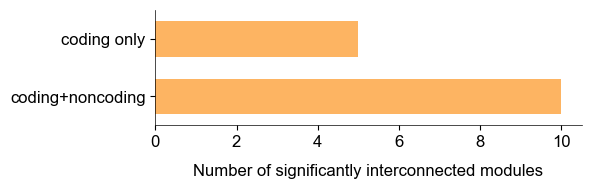

[<Figure size 550x150 with 1 Axes>,
 <Axes: xlabel='Number of significantly interconnected modules'>]

In [30]:
all_function_py3.horizontal_bar_graph(list(tag2module_num.keys()), list(tag2module_num.values()), x_original_2 = None, output = None, xerr_original = None, pval_list = None, figsize = (5.5,1.5), color = None, label = "Number of significantly interconnected modules", fontsize = 12, title = None, \
	cutoff = None, xlim = None, ylim = None, invert = False, tick_bins = None, labelpad = 10, ax = None, show = True, capsize = 5, barWidth = 0.618, logbase = None)

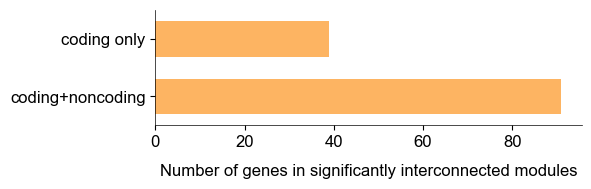

[<Figure size 550x150 with 1 Axes>,
 <Axes: xlabel='Number of genes in significantly interconnected modules'>]

In [29]:
all_function_py3.horizontal_bar_graph(list(tag2module_prot_num.keys()), list(tag2module_prot_num.values()), x_original_2 = None, output = None, xerr_original = None, pval_list = None, figsize = (5.5,1.5), color = None, label = "Number of genes in significantly interconnected modules", fontsize = 12, title = None, \
	cutoff = None, xlim = None, ylim = None, invert = False, tick_bins = None, labelpad = 10, ax = None, show = True, capsize = 5, barWidth = 0.618, logbase = None)

## SFARI enrichment of NetFlow3D-identified additional genes (in_floor=FALSE, 260503, 100kb)

In [123]:
# load TADA output
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
df = pd.read_csv(dr + f"TADA_coding_FuRawSup11_noncoding_UCSF_Combined_Simple_roulette_rd_control_formatted_260503_infloorFALSE_ScaleByLOEUF.txt", sep = "\t")
df = df.sort_values(by = "FDR_TADA_ASD_AddEM")
all_genes = set(df["gene_gencodeV33"])
print("all genes:", len(all_genes))
fu_genes = set(df[df["FDR_TADA_ASD"]<0.05]["gene_gencodeV33"])
fu_prots = set(df_idmap_slim[df_idmap_slim["ID"].isin(fu_genes)]["UniProt"])
print("Fu genes:", len(fu_genes), "Fu prots:", len(fu_prots))
noncoding_top_genes = set(df.sort_values("BF_ASD_EM", ascending=False).head(500)["gene_gencodeV33"])
noncoding_top_prots = set(df_idmap_slim[df_idmap_slim["ID"].isin(noncoding_top_genes)]["UniProt"])
print("Noncoding top 500 genes:", len(noncoding_top_genes), "Noncoding top 500 prots:", len(noncoding_top_prots))
df_sig = df[df["FDR_TADA_ASD_AddEM"] < 0.05]
df_nonsig = df[df["FDR_TADA_ASD_AddEM"] >= 0.05]
tada_genes = set(df_sig["gene_gencodeV33"])
tada_additional_genes = set(df_sig[df_sig["FDR_TADA_ASD"] >= 0.05]["gene_gencodeV33"])
tada_prots = set(df_idmap_slim[df_idmap_slim["ID"].isin(tada_genes)]["UniProt"])
print(len(tada_genes), len(tada_additional_genes), len(tada_prots))
df

all genes: 18107
Fu genes: 185 Fu prots: 184
Noncoding top 500 genes: 500 Noncoding top 500 prots: 496
214 31 213


,gene,gene_gencodeV33,gene_id,FDR_TADA_ASD,p_TADA_ASD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_ASD_EM,BF_ASD_PTV,BF_ASD_misB,BF_ASD_misA,BF_ASD_DEL,BF_ASD_DUP,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM
98,CHD8,CHD8,ENSG00000100888,0.000000,0.000000,22.553394,8.481258,1.248313,0.000000,0.0,0.019214,3.575967e+22,3.028709e+08,17.713867,1.000000e+00,1.0,1.045235,2.005296e+32,0.000000,0.000000
15,SYNGAP1,SYNGAP1,ENSG00000197283,0.000000,0.000000,24.628669,4.022717,0.149576,1.091557,0.0,0.011415,4.252739e+24,1.053700e+04,1.411160,1.234688e+01,1.0,1.026632,8.015561e+29,0.000000,0.000000
4559,PTEN,PTEN,ENSG00000171862,0.000000,0.000000,3.267106,14.020618,0.077350,0.132195,0.0,0.023560,1.849719e+03,1.048619e+14,1.194950,1.355799e+00,1.0,1.055748,3.317636e+17,0.000000,0.000000
327,SHANK3,SHANK3,ENSG00000251322,0.000000,0.000000,19.321853,0.000000,0.000000,19.704500,0.0,0.049270,2.098230e+19,1.000000e+00,1.000000,5.064068e+19,1.0,1.120135,1.190208e+39,0.000000,0.000000
346,SCN2A,SCN2A,ENSG00000136531,0.000000,0.000000,24.299391,20.847937,1.328200,0.803454,0.0,0.025128,1.992467e+24,7.045909e+20,21.291213,6.359960e+00,1.0,1.059566,2.014240e+47,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1534,PITPNC1,PITPNC1,ENSG00000154217,0.851998,0.368287,0.042740,0.000000,0.004478,0.000000,0.0,-0.349652,1.103417e+00,1.000000e+00,1.010364,1.000000e+00,1.0,0.447042,4.983860e-01,0.902391,0.999761
4264,CREB5,CREB5,ENSG00000146592,0.863096,0.423149,0.000000,0.000000,0.027311,0.000000,0.0,-0.338635,1.000000e+00,1.000000e+00,1.064904,1.000000e+00,1.0,0.458527,4.882875e-01,0.902395,0.999821
564,RXRA,RXRA,ENSG00000186350,0.888922,0.622310,0.000000,0.000000,0.000000,0.000000,0.0,-0.312022,1.000000e+00,1.000000e+00,1.000000,1.000000e+00,1.0,0.487503,4.875033e-01,0.902399,0.999880
14928,CAMKMT,CAMKMT,ENSG00000143919,0.906422,0.889385,0.000000,0.000000,0.000000,0.000000,0.0,-0.333416,1.000000e+00,1.000000e+00,1.000000,1.000000e+00,1.0,0.464070,4.640701e-01,0.902404,0.999940


In [134]:
label2num = {"TADA\nadditional\ngenes\n(n={})".format(len(tada_additional_genes)): (len(set(tada_additional_genes).intersection(sfari_genes)), len(tada_additional_genes)), \
"Genome-wide\nbackground\n(n={})".format(len(all_genes)): (len(all_genes.intersection(sfari_genes)), len(all_genes))}

In [135]:
# load NetFlow3D results
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/NetFlow3D/output/"
netflow3d_result_prefix = "InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5"
G = nx.read_graphml(dr + netflow3d_result_prefix + "/initial_state.graphml.gz")
df = pd.read_csv(dr + netflow3d_result_prefix + "_subnetworks.txt", sep = "\t")
df["Contain_extended_TADA_genes"] = df["Subnetwork_genes"].apply(lambda x: ",".join(sorted(set(x.split(",")).intersection(tada_prots))))
df["Contain_Fu's_genes"] = df["Subnetwork_genes"].apply(lambda x: ",".join(sorted(set(x.split(",")).intersection(fu_prots))))
df["Contain_noncoding_top_genes"] = df["Subnetwork_genes"].apply(lambda x: ",".join(sorted(set(x.split(",")).intersection(noncoding_top_prots))))
df = df[df["Subnetwork_size"] > 5]
module_prots = []
for x in df["Subnetwork_genes"]:
    module_prots.extend(x.split(","))
module_prots = set(module_prots)
module_genes = set(df_idmap[df_idmap["UniProt"].isin(module_prots)]["ID"])
print(len(module_prots), list(module_prots)[:5])
print(len(module_genes), list(module_genes)[:5])
df

82 ['O00255', 'Q14814', 'O94964', 'Q92823', 'Q96KQ7']
83 ['SEMA4C', 'MPHOSPH8', 'KCNA3', 'ZNF821', 'KMT2A']


,Subnetwork_genes,Subnetwork_size,Contain_extended_TADA_genes,Contain_Fu's_genes,Contain_noncoding_top_genes
0,"O14490,O15018,O43166,O43300,O43301,P22001,P783...",18,"P78352,Q13224,Q9ULB1,Q9UPN3,Q9UQM7","P78352,Q13224,Q9ULB1,Q9UQM7","O43166,Q15700,Q9C0C4,Q9UPN3"
1,"O15020,O75152,O75541,O95996,P51531,P51532,P539...",15,"P51531,Q14669,Q8TAQ2","P51531,Q14669,Q8TAQ2","P51531,P51532,Q8WZA2,Q92565,Q9UH65"
2,"O94964,P08235,P10588,P10589,P35398,Q12796,Q157...",12,Q92753,Q92753,"P10589,Q15777,Q92786"
3,"O00255,P15884,P15923,P17535,Q02535,Q03164,Q152...",9,"P15884,Q03164,Q8NEZ4,Q92793","P15884,Q03164,Q8NEZ4,Q92793","P15884,Q03164"
4,"P56524,Q01082,Q02078,Q06413,Q13813,Q14814,Q9UK...",8,"P56524,Q06413","P56524,Q06413","P56524,Q06413,Q9UKV0"
5,"A4D2B0,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9HC24,Q9Y485",7,"Q7Z3K3,Q96BD5","Q7Z3K3,Q96BD5",Q8N1W2
6,"O43432,P06730,P18206,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7,,,Q9BX66
7,"P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1",6,"P84243,Q9Y6K1","P84243,Q9Y6K1",


In [136]:
netflow3d_additional_genes = module_genes - tada_genes
print(len(netflow3d_additional_genes), list(netflow3d_additional_genes)[:5])
tada_extended_genes = set(df_nonsig["gene_gencodeV33"].head(len(netflow3d_additional_genes)))
print(len(tada_extended_genes), list(tada_extended_genes)[:5])

64 ['SEMA4C', 'MPHOSPH8', 'TLN1', 'KCNA3', 'RORA']
64 ['EIF3G', 'ELAVL3', 'DAB2IP', 'TFAP4', 'SRRM3']


In [137]:
label2num["NetFlow3D\nadditional\ngenes\n(n={})".format(len(netflow3d_additional_genes))] = (len(netflow3d_additional_genes.intersection(sfari_genes)), len(netflow3d_additional_genes))
label2num["TADA\nextended\ngenes\n(n={})".format(len(tada_extended_genes))] = (len(tada_extended_genes.intersection(sfari_genes)), len(tada_extended_genes))

In [138]:
tada_prot_neighbors = []
tada_prots_not_in_ppi = []
for x in tada_prots:
    if x in G.nodes:
        tada_prot_neighbors.extend(list(G.neighbors(x)))
    else:
        tada_prots_not_in_ppi.append(x)
print(len(tada_prots_not_in_ppi))
tada_neighbor_prots = list(set(tada_prot_neighbors) - tada_prots)
tada_neighbor_genes = set(df_idmap[df_idmap["UniProt"].isin(tada_neighbor_prots)]["ID"])
print(len(tada_neighbor_prots), len(tada_neighbor_genes), list(tada_neighbor_prots)[:5])

2164
1714 1742 ['Q5T3U5', 'Q2TAY7', 'Q14627', 'Q9Y5Z9', 'Q8WWM7']


In [139]:
label2num["TADA gene\nneighbors\n(n={})".format(len(tada_neighbor_genes))] = (len(set(tada_neighbor_genes).intersection(sfari_genes)), len(tada_neighbor_genes))
label2num

{'TADA\nadditional\ngenes\n(n=31)': (10, 31),
 'Genome-wide\nbackground\n(n=18107)': (876, 18107),
 'NetFlow3D\nadditional\ngenes\n(n=64)': (18, 64),
 'TADA\nextended\ngenes\n(n=64)': (21, 64),
 'TADA gene\nneighbors\n(n=1742)': (129, 1742)}

In [140]:
129 / 1742

0.07405281285878301

TADA additional genes (n=31) Genome-wide background (n=18107) 1.4760412621887258e-12
TADA additional genes (n=31) NetFlow3D additional genes (n=64) 0.6786729454066974
TADA additional genes (n=31) TADA extended genes (n=64) 0.9569035452553669
TADA additional genes (n=31) TADA gene neighbors (n=1742) 3.348236981861503e-07
Genome-wide background (n=18107) NetFlow3D additional genes (n=64) 8.087221902714003e-18
Genome-wide background (n=18107) TADA extended genes (n=64) 6.172131171388957e-25
Genome-wide background (n=18107) TADA gene neighbors (n=1742) 3.040626294777487e-06
NetFlow3D additional genes (n=64) TADA extended genes (n=64) 0.5645466433514832
NetFlow3D additional genes (n=64) TADA gene neighbors (n=1742) 2.624112856479091e-09
TADA extended genes (n=64) TADA gene neighbors (n=1742) 4.703687402814584e-13


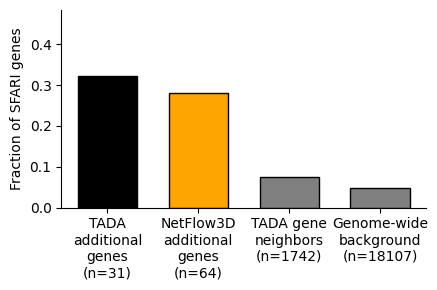

In [141]:
labels = ["TADA\nadditional\ngenes\n(n={})".format(len(tada_additional_genes)), "NetFlow3D\nadditional\ngenes\n(n={})".format(len(netflow3d_additional_genes)), "TADA gene\nneighbors\n(n={})".format(len(tada_neighbor_genes)), "Genome-wide\nbackground\n(n={})".format(len(all_genes))]
fractions = [label2num[x][0]/label2num[x][1] for x in labels]
for x,y in combinations(label2num.keys(), 2):
    p = all_function_py3.bino2test(label2num[x][0], label2num[x][1], label2num[y][0], label2num[y][1])
    print(x.replace("\n", " "), y.replace("\n", " "), p)

# -----------------------------
# 3. plot
# -----------------------------
fig, ax = plt.subplots(figsize=(4.5,3))

x = np.arange(len(labels))

colors = ["black", "orange", "gray", "gray", "gray"]

bars = ax.bar(
    x,
    fractions,
    capsize=4,
    width=0.65,
    edgecolor="black",
    color=colors
)

ax.set_ylabel("Fraction of SFARI genes")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, max(fractions)*1.5)


# -----------------------------
# 7. clean style
# -----------------------------
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## SFARI enrichment of NetFlow3D-identified additional genes (in_floor=TRUE, 260503, 100kb)

In [464]:
# load TADA output
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
df = pd.read_csv(dr + f"TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaledByLOEUF_260503.txt", sep = "\t")
all_genes = set(df["gene_gencodeV33"])
print("all genes:", len(all_genes))
df = df[df["FDR_TADA_ASD_AddEM"] < 0.05]
tada_genes = set(df["gene_gencodeV33"])
tada_additional_genes = set(df[df["FDR_TADA_ASD"] >= 0.05]["gene_gencodeV33"])
tada_prots = set(df_idmap_slim[df_idmap_slim["ID"].isin(tada_genes)]["UniProt"])
print(len(tada_genes), len(tada_additional_genes), len(tada_prots), list(tada_prots)[:5])
df

all genes: 18107
215 32 214 ['O14980', 'Q9P2B2', 'Q8IWV7', 'Q9UPQ9', 'Q96L73']


,gene,gene_gencodeV33,gene_id,FDR_TADA_ASD,p_TADA_ASD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_ASD_EM,BF_ASD_PTV,BF_ASD_misB,BF_ASD_misA,BF_ASD_DEL,BF_ASD_DUP,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM
0,MED13,MED13,ENSG00000108510,1.390292e-07,2.104537e-10,6.671037e+00,0.362988,0.062879,0.000000,0.000000,0.000000,4.688530e+06,2.306685,1.155790,1.000000,1.000000,1.000000,1.249983e+07,1.297772e-07,1.984961e-10
1,NIPBL,NIPBL,ENSG00000164190,9.954028e-06,2.290304e-08,0.000000e+00,1.586224,0.144206,0.000000,3.659043,0.033117,1.000000e+00,38.567683,1.393818,1.000000,4560.822556,1.079239,2.646002e+05,9.245475e-06,2.262573e-08
8,NCKAP1,NCKAP1,ENSG00000061676,8.298073e-03,5.376153e-05,5.347946e-01,0.807108,0.000000,1.206512,0.050489,0.000000,3.426057e+00,6.413686,1.000000,16.088364,1.123284,1.000000,3.971034e+02,1.002971e-02,7.608930e-05
13,XPO1,XPO1,ENSG00000082898,2.896763e-02,2.701122e-04,0.000000e+00,0.788930,0.089966,0.000000,1.270036,0.059327,1.000000e+00,6.150775,1.230172,1.000000,18.622418,1.146376,1.615322e+02,2.700401e-02,2.858169e-04
14,PRR12,PRR12,ENSG00000126464,1.482879e-02,1.122345e-04,1.990790e+00,0.074377,0.366096,0.000000,0.000000,0.093441,9.790159e+01,1.186798,2.323250,1.000000,1.000000,1.240056,3.347371e+02,1.344333e-02,1.118560e-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13796,PRH1,PRH1,ENSG00000231887,3.625124e-03,1.997445e-05,2.958373e+00,0.000000,0.000000,0.000000,0.000000,0.000000,9.086015e+02,1.000000,1.000000,1.000000,1.000000,1.000000,9.086015e+02,3.377236e-03,2.004225e-05
14246,ROPN1,ROPN1,ENSG00000065371,2.563345e-02,2.297097e-04,9.643275e-17,2.220495,0.000000,0.000000,0.000000,0.000000,1.000000e+00,166.147898,1.000000,1.000000,1.000000,1.000000,1.661479e+02,2.609356e-02,2.729876e-04
15292,DNMT3A,DNMT3A,ENSG00000119772,2.763366e-05,7.362101e-08,5.651927e-01,0.000000,4.404570,0.000000,0.000000,0.127271,3.674453e+00,1.000000,25384.584404,1.000000,1.000000,1.340514,1.250357e+05,2.092762e-05,5.761635e-08
16158,PTGDR2,PTGDR2,ENSG00000183134,1.523312e-02,1.162171e-04,0.000000e+00,2.431145,0.000000,0.000000,0.000000,0.001887,1.000000e+00,269.864192,1.000000,1.000000,1.000000,1.004355,2.710394e+02,1.676962e-02,1.508183e-04


In [465]:
label2num = {"TADA\nadditional genes\n(n={})".format(len(tada_additional_genes)): (len(set(tada_additional_genes).intersection(sfari_genes)), len(tada_additional_genes)), \
"Genome-wide\nbackground\n(n={})".format(len(all_genes)): (len(all_genes.intersection(sfari_genes)), len(all_genes))}

In [466]:
# load NetFlow3D results
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/NetFlow3D/output/"
netflow3d_result_prefix = "InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_260503_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5"
G = nx.read_graphml(dr + netflow3d_result_prefix + "/initial_state.graphml.gz")
df = pd.read_csv(dr + netflow3d_result_prefix + "_subnetworks.txt", sep = "\t")
df = df[df["Subnetwork_size"] > 5]
module_prots = []
for x in df["Subnetwork_genes"]:
    module_prots.extend(x.split(","))
module_prots = set(module_prots)
module_genes = set(df_idmap[df_idmap["UniProt"].isin(module_prots)]["ID"])
print(len(module_prots), list(module_prots)[:5])
print(len(module_genes), list(module_genes)[:5])
df

91 ['Q9UBC3', 'Q8WUJ3', 'O94964', 'O15018', 'O75541']
92 ['ZNF710', 'GRIN1', 'SMARCC2', 'KMT2C', 'GRIN2A']


,Subnetwork_genes,Subnetwork_size
0,"O15018,O43166,O43300,O43301,P22001,P78352,Q055...",18
1,"O15020,O75152,O75153,O75334,O75541,O95996,P515...",16
2,"O94964,P10588,P10589,P35398,Q12796,Q15777,Q53Q...",10
3,"O00255,P15884,P15923,Q02535,Q03164,Q15291,Q8NE...",8
4,"P50148,P98161,Q01082,Q06413,Q13563,Q13813,Q9NQ...",8
5,"A4D2B0,O43795,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",7
6,"O43791,O75367,P60484,Q12888,Q15059,Q5U5Q3",6
7,"P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1",6
8,"O75051,Q14157,Q8IY37,Q8IYU2,Q8N3X1,Q8WUJ3",6
9,"O43432,P06730,P18206,Q9BX66,Q9H2E6,Q9NR09",6


In [467]:
netflow3d_additional_genes = module_genes - tada_genes
print(len(netflow3d_additional_genes), list(netflow3d_additional_genes)[:5])

73 ['MPHOSPH8', 'HACE1', 'ZNF710', 'GRIN1', 'DLG2']


In [468]:
label2num["NetFlow3D\nadditional genes\n(n={})".format(len(netflow3d_additional_genes))] = (len(netflow3d_additional_genes.intersection(sfari_genes)), len(netflow3d_additional_genes))

In [469]:
tada_prot_neighbors = []
tada_prots_not_in_ppi = []
for x in tada_prots:
    if x in G.nodes:
        tada_prot_neighbors.extend(list(G.neighbors(x)))
    else:
        tada_prots_not_in_ppi.append(x)
print(len(tada_prots_not_in_ppi))
tada_neighbor_prots = list(set(tada_prot_neighbors) - tada_prots)
tada_neighbor_genes = set(df_idmap[df_idmap["UniProt"].isin(tada_neighbor_prots)]["ID"])
print(len(tada_neighbor_prots), len(tada_neighbor_genes), list(tada_neighbor_prots)[:5])

49
1714 1742 ['Q12959', 'Q13952', 'A2A2V5', 'Q3KNS6', 'O14964']


In [470]:
label2num["TADA gene\nneighbors\n(n={})".format(len(tada_neighbor_genes))] = (len(set(tada_neighbor_genes).intersection(sfari_genes)), len(tada_neighbor_genes))
label2num

{'TADA\nadditional genes\n(n=32)': (10, 32),
 'Genome-wide\nbackground\n(n=18107)': (876, 18107),
 'NetFlow3D\nadditional genes\n(n=73)': (18, 73),
 'TADA gene\nneighbors\n(n=1742)': (129, 1742)}

In [471]:
129 / 1742

0.07405281285878301

TADA additional genes (n=32) Genome-wide background (n=18107) 4.340760161772814e-12
TADA additional genes (n=32) NetFlow3D additional genes (n=73) 0.4819556247671496
TADA additional genes (n=32) TADA gene neighbors (n=1742) 6.560075497078191e-07
Genome-wide background (n=18107) NetFlow3D additional genes (n=73) 5.471165513243175e-15
Genome-wide background (n=18107) TADA gene neighbors (n=1742) 3.040626294777487e-06
NetFlow3D additional genes (n=73) TADA gene neighbors (n=1742) 1.2023728218534292e-07


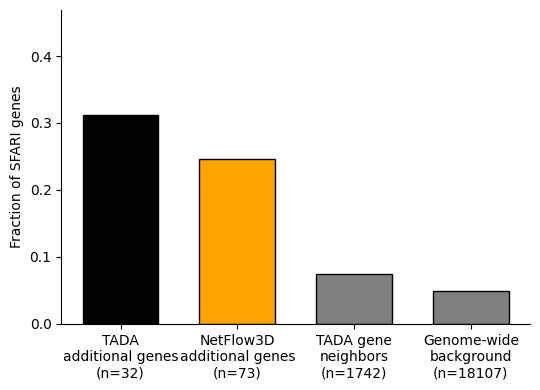

In [472]:
labels = ["TADA\nadditional genes\n(n={})".format(len(tada_additional_genes)), "NetFlow3D\nadditional genes\n(n={})".format(len(netflow3d_additional_genes)), "TADA gene\nneighbors\n(n={})".format(len(tada_neighbor_genes)), "Genome-wide\nbackground\n(n={})".format(len(all_genes))]
fractions = [label2num[x][0]/label2num[x][1] for x in labels]
for x,y in combinations(label2num.keys(), 2):
    p = all_function_py3.bino2test(label2num[x][0], label2num[x][1], label2num[y][0], label2num[y][1])
    print(x.replace("\n", " "), y.replace("\n", " "), p)

# -----------------------------
# 3. plot
# -----------------------------
fig, ax = plt.subplots(figsize=(5.5,4))

x = np.arange(len(labels))

colors = ["black", "orange", "gray", "gray"]

bars = ax.bar(
    x,
    fractions,
    capsize=4,
    width=0.65,
    edgecolor="black",
    color=colors
)

ax.set_ylabel("Fraction of SFARI genes")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, max(fractions)*1.5)


# -----------------------------
# 7. clean style
# -----------------------------
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## SFARI enrichment of NetFlow3D-identified additional genes (50kb+100kb)

In [272]:
# load TADA output
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
df = pd.read_csv(dr + f"TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt", sep = "\t")
all_genes = set(df["gene_gencodeV33"])
print("all genes:", len(all_genes))
df = df[df["FDR_TADA_ASD_AddEM"] < 0.05]
tada_genes = set(df["gene_gencodeV33"])
tada_additional_genes = set(df[df["FDR_TADA_ASD"] >= 0.05]["gene_gencodeV33"])
tada_prots = set(df_idmap_slim[df_idmap_slim["ID"].isin(tada_genes)]["UniProt"])
print(len(tada_genes), len(tada_additional_genes), len(tada_prots), list(tada_prots)[:5])
df

all genes: 18107
211 28 210 ['O14980', 'Q9P2B2', 'Q8IWV7', 'Q9UPQ9', 'Q96L73']


,gene,gene_gencodeV33,gene_id,FDR_TADA_ASD,p_TADA_ASD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_ASD_EM,BF_ASD_PTV,BF_ASD_misB,BF_ASD_misA,BF_ASD_DEL,BF_ASD_DUP,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM
0,MED13,MED13,ENSG00000108510,1.390292e-07,2.104537e-10,6.671037e+00,0.362988,0.062879,0.000000,0.000000,0.000000,4.688530e+06,2.306685,1.155790,1.000000,1.000000,1.000000,1.249983e+07,1.296459e-07,1.980326e-10
1,NIPBL,NIPBL,ENSG00000164190,9.954028e-06,2.290304e-08,0.000000e+00,1.586224,0.144206,0.000000,3.659043,0.033308,1.000000e+00,38.567683,1.393818,1.000000,4560.822556,1.079713,2.647166e+05,7.895777e-06,1.833227e-08
8,NCKAP1,NCKAP1,ENSG00000061676,8.298073e-03,5.376153e-05,5.347946e-01,0.807108,0.000000,1.206512,0.050489,0.000000,3.426057e+00,6.413686,1.000000,16.088364,1.123284,1.000000,3.971034e+02,9.493987e-03,6.960938e-05
13,XPO1,XPO1,ENSG00000082898,2.896763e-02,2.701122e-04,0.000000e+00,0.788930,0.089966,0.000000,1.270036,0.000000,1.000000e+00,6.150775,1.230172,1.000000,18.622418,1.000000,1.409068e+02,2.973520e-02,3.179412e-04
14,PRR12,PRR12,ENSG00000126464,1.482879e-02,1.122345e-04,1.990790e+00,0.074377,0.366096,0.000000,0.000000,0.093805,9.790159e+01,1.186798,2.323250,1.000000,1.000000,1.241094,3.350172e+02,1.284368e-02,1.028013e-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13796,PRH1,PRH1,ENSG00000231887,3.625124e-03,1.997445e-05,2.958373e+00,0.000000,0.000000,0.000000,0.000000,0.000000,9.086015e+02,1.000000,1.000000,1.000000,1.000000,1.000000,9.086015e+02,3.324573e-03,1.929734e-05
14246,ROPN1,ROPN1,ENSG00000065371,2.563345e-02,2.297097e-04,9.643275e-17,2.220495,0.000000,0.000000,0.000000,0.000000,1.000000e+00,166.147898,1.000000,1.000000,1.000000,1.000000,1.661479e+02,2.680088e-02,2.767411e-04
15292,DNMT3A,DNMT3A,ENSG00000119772,2.763366e-05,7.362101e-08,5.651927e-01,0.000000,4.404570,0.000000,0.000000,0.128323,3.674453e+00,1.000000,25384.584404,1.000000,1.000000,1.343764,1.253389e+05,1.670710e-05,4.287344e-08
16158,PTGDR2,PTGDR2,ENSG00000183134,1.523312e-02,1.162171e-04,0.000000e+00,2.431145,0.000000,0.000000,0.000000,0.001905,1.000000e+00,269.864192,1.000000,1.000000,1.000000,1.004396,2.710505e+02,1.666408e-02,1.455980e-04


In [273]:
label2num = {"TADA\nadditional genes\n(n={})".format(len(tada_additional_genes)): (len(set(tada_additional_genes).intersection(sfari_genes)), len(tada_additional_genes)), \
"Genome-wide\nbackground\n(n={})".format(len(all_genes)): (len(all_genes.intersection(sfari_genes)), len(all_genes))}

In [274]:
# load NetFlow3D results
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/NetFlow3D/output/"
netflow3d_result_prefix = "InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5"
G = nx.read_graphml(dr + netflow3d_result_prefix + "/initial_state.graphml.gz")
df = pd.read_csv(dr + netflow3d_result_prefix + "_subnetworks.txt", sep = "\t")
df = df[df["Subnetwork_size"] > 5]
module_prots = []
for x in df["Subnetwork_genes"]:
    module_prots.extend(x.split(","))
module_prots = set(module_prots)
module_genes = set(df_idmap[df_idmap["UniProt"].isin(module_prots)]["ID"])
print(len(module_prots), list(module_prots)[:5])
print(len(module_genes), list(module_genes)[:5])
df

92 ['Q9UBC3', 'Q8WUJ3', 'O94964', 'O15018', 'P84243']
93 ['ZNF710', 'GRIN1', 'SMARCC2', 'KMT2C', 'GRIN2A']


,Subnetwork_genes,Subnetwork_size
0,"O14490,O15018,O43166,O43300,O43301,P22001,P783...",19
1,"O94964,P08235,P10588,P10589,P33121,P35398,Q127...",12
2,"O15020,O75152,O75153,P51532,P53985,P60709,P611...",12
3,"P98161,Q01082,Q06413,Q13813,Q14814,Q9H0K1,Q9NQ...",9
4,"O00255,P15884,P15923,Q02535,Q03164,Q15291,Q8NE...",8
5,"A4D2B0,O43795,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9Y485",7
6,"O43432,P06730,P18206,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7
7,"O43791,O75367,P60484,Q12888,Q15059,Q5U5Q3",6
8,"P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1",6
9,"O75051,Q14157,Q8IY37,Q8IYU2,Q8N3X1,Q8WUJ3",6


In [275]:
netflow3d_additional_genes = module_genes - tada_genes
print(len(netflow3d_additional_genes), list(netflow3d_additional_genes)[:5])

73 ['MPHOSPH8', 'HACE1', 'ZNF710', 'GRIN1', 'DLG2']


In [276]:
label2num["NetFlow3D\nadditional genes\n(n={})".format(len(netflow3d_additional_genes))] = (len(netflow3d_additional_genes.intersection(sfari_genes)), len(netflow3d_additional_genes))

In [277]:
tada_prot_neighbors = []
tada_prots_not_in_ppi = []
for x in tada_prots:
    if x in G.nodes:
        tada_prot_neighbors.extend(list(G.neighbors(x)))
    else:
        tada_prots_not_in_ppi.append(x)
print(len(tada_prots_not_in_ppi))
tada_neighbor_prots = list(set(tada_prot_neighbors))
tada_neighbor_genes = set(df_idmap[df_idmap["UniProt"].isin(tada_neighbor_prots)]["ID"])
print(len(tada_neighbor_prots), len(tada_neighbor_genes), list(tada_neighbor_prots)[:5])

45
1818 1846 ['Q12959', 'O14964', 'Q8IWV7', 'Q9HAU4', 'P52888']


In [278]:
label2num["TADA gene\nneighbors\n(n={})".format(len(tada_neighbor_genes))] = (len(set(tada_neighbor_genes).intersection(sfari_genes)), len(tada_neighbor_genes))
label2num

{'TADA\nadditional genes\n(n=28)': (8, 28),
 'Genome-wide\nbackground\n(n=18107)': (876, 18107),
 'NetFlow3D\nadditional genes\n(n=73)': (19, 73),
 'TADA gene\nneighbors\n(n=1846)': (211, 1846)}

TADA additional genes (n=28) Genome-wide background (n=18107) 5.622922083173114e-09
TADA additional genes (n=28) NetFlow3D additional genes (n=73) 0.7959451135781346
TADA additional genes (n=28) TADA gene neighbors (n=1846) 0.005075187906021539
Genome-wide background (n=18107) NetFlow3D additional genes (n=73) 6.749574415281428e-17
Genome-wide background (n=18107) TADA gene neighbors (n=1846) 1.361554102323452e-32
NetFlow3D additional genes (n=73) TADA gene neighbors (n=1846) 0.00016572499432448612


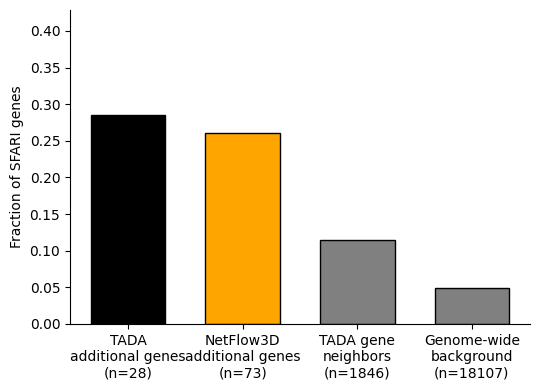

In [279]:
labels = ["TADA\nadditional genes\n(n={})".format(len(tada_additional_genes)), "NetFlow3D\nadditional genes\n(n={})".format(len(netflow3d_additional_genes)), "TADA gene\nneighbors\n(n={})".format(len(tada_neighbor_genes)), "Genome-wide\nbackground\n(n={})".format(len(all_genes))]
fractions = [label2num[x][0]/label2num[x][1] for x in labels]
for x,y in combinations(label2num.keys(), 2):
    p = all_function_py3.bino2test(label2num[x][0], label2num[x][1], label2num[y][0], label2num[y][1])
    print(x.replace("\n", " "), y.replace("\n", " "), p)

# -----------------------------
# 3. plot
# -----------------------------
fig, ax = plt.subplots(figsize=(5.5,4))

x = np.arange(len(labels))

colors = ["black", "orange", "gray", "gray"]

bars = ax.bar(
    x,
    fractions,
    capsize=4,
    width=0.65,
    edgecolor="black",
    color=colors
)

ax.set_ylabel("Fraction of SFARI genes")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, max(fractions)*1.5)


# -----------------------------
# 7. clean style
# -----------------------------
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## Network topology analysis

### load gene sets

In [143]:
# load TADA output  
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/output/InhAll_DNVAll/"
df_tada_results = pd.read_csv(dr + "TADA_coding_FuRawSup11_noncoding_UCSF_Combined_Simple_roulette_rd_control_formatted_260503_infloorFALSE_ScaleByLOEUF.txt", sep = "\t")
df_tada_results["l10BF_ASD_Coding"] = df_tada_results.apply(lambda x: x["l10BF_ASD_PTV"] + x["l10BF_ASD_misB"] + x["l10BF_ASD_misA"] + x["l10BF_ASD_DEL"] + x["l10BF_ASD_DUP"], axis = 1)
tada_genes = set(df_tada_results[df_tada_results["FDR_TADA_ASD_AddEM"] < 0.05]["gene_gencodeV33"])
fu_genes = set(df_tada_results[df_tada_results["FDR_TADA_ASD"] < 0.05]["gene_gencodeV33"])
fu_prots = set(df_idmap[df_idmap["ID"].isin(fu_genes)]["UniProt"])
print(len(tada_genes), len(fu_genes), len(fu_prots))
df_tada_results[["gene", "l10BF_ASD_Coding", "l10BF_ASD_EM"]]

214 185 2059


,gene,l10BF_ASD_Coding,l10BF_ASD_EM
0,MED13,7.096904e+00,-0.034876
1,NIPBL,5.389473e+00,0.033117
2,SMC3,1.440559e+00,0.004601
3,CNOT1,6.274865e-01,0.000000
4,RLF,4.868035e-01,0.084245
...,...,...,...
18123,TRIM48,1.928655e-16,0.000000
18124,PSG1,0.000000e+00,0.000000
18125,NBPF10,0.000000e+00,0.000000
18126,LZTR1,1.779615e-01,-0.006497


In [144]:
df_tada_results.head()

,gene,gene_gencodeV33,gene_id,FDR_TADA_ASD,p_TADA_ASD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_ASD_EM,BF_ASD_PTV,BF_ASD_misB,BF_ASD_misA,BF_ASD_DEL,BF_ASD_DUP,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM,l10BF_ASD_Coding
0,MED13,MED13,ENSG00000108510,1.390292e-07,2.104537e-10,6.671037,0.362988,0.062879,0.0,0.000000,-0.034876,4.688530e+06,2.306685,1.155790,1.0,1.000000,0.922835,1.153527e+07,1.349638e-07,2.062550e-10,7.096904
1,NIPBL,NIPBL,ENSG00000164190,9.954028e-06,2.290304e-08,0.000000,1.586224,0.144206,0.0,3.659043,0.033117,1.000000e+00,38.567683,1.393818,1.0,4560.822556,1.079239,2.646002e+05,9.375821e-06,2.292538e-08,5.389473
2,SMC3,SMC3,ENSG00000108055,1.584900e-01,3.195632e-03,0.000000,1.440559,0.000000,0.0,0.000000,0.004601,1.000000e+00,27.577746,1.000000,1.0,1.000000,1.010650,2.787145e+01,1.662512e-01,4.166736e-03,1.440559
3,CNOT1,CNOT1,ENSG00000125107,5.438422e-01,4.129344e-02,0.000000,0.627486,0.000000,0.0,0.000000,0.000000,1.000000e+00,4.241178,1.000000,1.0,1.000000,1.000000,4.241178e+00,5.472059e-01,5.178082e-02,0.627486
4,RLF,RLF,ENSG00000117000,6.212839e-01,6.376324e-02,0.463616,0.000000,0.023187,0.0,0.000000,0.084245,2.908148e+00,1.000000,1.054841,1.0,1.000000,1.214073,3.724332e+00,5.779339e-01,6.143628e-02,0.486803


In [145]:
# load NetFlow3D results
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/NetFlow3D/output/"
netflow3d_tag = "InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5"
G = nx.read_graphml(f"{dr}{netflow3d_tag}/initial_state.graphml.gz")
df_subnetworks = pd.read_csv(f"{dr}{netflow3d_tag}_subnetworks.txt", sep = "\t")
df_subnetworks = df_subnetworks[df_subnetworks["Subnetwork_size"] > 5]
module_prots = []
for x in df_subnetworks["Subnetwork_genes"]:
    module_prots.extend(x.split(","))
module_prots = set(module_prots)
module_genes = set(df_idmap[df_idmap["UniProt"].isin(module_prots)]["ID"])
print(len(module_prots), len(module_genes), list(module_genes)[:5])
df_subnetworks


82 83 ['SEMA4C', 'MPHOSPH8', 'KCNA3', 'ZNF821', 'KMT2A']


,Subnetwork_genes,Subnetwork_size
0,"O14490,O15018,O43166,O43300,O43301,P22001,P783...",18
1,"O15020,O75152,O75541,O95996,P51531,P51532,P539...",15
2,"O94964,P08235,P10588,P10589,P35398,Q12796,Q157...",12
3,"O00255,P15884,P15923,P17535,Q02535,Q03164,Q152...",9
4,"P56524,Q01082,Q02078,Q06413,Q13813,Q14814,Q9UK...",8
5,"A4D2B0,Q02447,Q7Z3K3,Q8N1W2,Q96BD5,Q9HC24,Q9Y485",7
6,"O43432,P06730,P18206,Q9BX66,Q9H2E6,Q9NR09,Q9Y490",7
7,"P84243,Q8NB78,Q96KQ7,Q99549,Q9UBC3,Q9Y6K1",6


In [146]:
fu_prot_neighbors = []
for x in fu_prots.intersection(set(G.nodes())):
    fu_prot_neighbors.extend(list(G.neighbors(x)))
fu_neighbor_prots = set(fu_prot_neighbors) - fu_prots
fu_neighbor_genes = set(df_idmap[df_idmap["UniProt"].isin(fu_neighbor_prots)]["ID"])
print(len(fu_neighbor_prots), len(fu_neighbor_genes), list(fu_neighbor_prots)[:5])

1456 1484 ['Q5T3U5', 'Q2TAY7', 'Q14627', 'Q9Y5Z9', 'Q9BVN2']


In [147]:
top_cutoff = 200
noncoding_top_genes = df_tada_results.sort_values(by = "l10BF_ASD_EM", ascending=False).head(top_cutoff)["gene"].tolist()
coding_top_genes = df_tada_results.sort_values(by = "l10BF_ASD_Coding", ascending=False).head(top_cutoff)["gene"].tolist()
tag2genes = {"Fu's genes": df_tada_results[df_tada_results["FDR_TADA_ASD"] < 0.05]["gene"].tolist(), "Fu neighbors": list(fu_neighbor_genes), "coding_top": coding_top_genes, "noncoding_top": noncoding_top_genes, "genome-wide": df_tada_results["gene"].tolist()}
print(len(tag2genes["Fu's genes"]), len(tag2genes["Fu neighbors"]), len(coding_top_genes), len(noncoding_top_genes), len(set(noncoding_top_genes).intersection(set(coding_top_genes))))

185 1484 200 200 12


### degree, betweenness centrality, k-core

In [609]:
# calculate network metrics
# bc = nx.betweenness_centrality(G, k=1000, weight="weight", seed=1)
G_no_self = G.copy()
G_no_self.remove_edges_from(nx.selfloop_edges(G_no_self))
core_num = nx.core_number(G_no_self)


In [683]:
df_output = {"group": [], "UniProt": [], "degree": [], "betweenness_centrality": [], "core_number": [], "clustering_coefficient": []}
for tag,genes in tag2genes.items():
    prots = set(df_idmap[df_idmap["ID"].isin(genes)]["UniProt"]).intersection(set(G.nodes()))
    print(tag, len(genes), len(prots))
    for p in prots:
        df_output["group"].append(tag)
        df_output["UniProt"].append(p)
        df_output["degree"].append(G.degree(p))
        df_output["betweenness_centrality"].append(bc[p])
        df_output["core_number"].append(core_num[p])
        df_output["clustering_coefficient"].append(nx.clustering(G, p))
df_output = pd.DataFrame(df_output)
df_output["log(degree+1)"] = df_output["degree"].apply(lambda x: np.log(x+1))
df_output["log(core_number+1)"] = df_output["core_number"].apply(lambda x: np.log(x+1))
df_output["BC^1/3"] = df_output["betweenness_centrality"].apply(lambda x: x**(1/3))
df_output

Fu's genes 185 146
Fu neighbors 1484 1458
coding_top 200 155
noncoding_top 200 127
genome-wide 18128 7550


,group,UniProt,degree,betweenness_centrality,core_number,clustering_coefficient,log(degree+1),log(core_number+1),BC^1/3
0,Fu's genes,Q7L7X3,4,0.000003,4,0.000000,1.609438,1.609438,0.014136
1,Fu's genes,P35222,42,0.001099,16,0.037179,3.761200,2.833213,0.103212
2,Fu's genes,Q5TGY3,5,0.000059,5,0.100000,1.791759,1.791759,0.039038
3,Fu's genes,Q96F07,2,0.000001,2,0.000000,1.098612,1.098612,0.010151
4,Fu's genes,Q9UPT6,10,0.000051,7,0.000000,2.397895,2.079442,0.036993
...,...,...,...,...,...,...,...,...,...
9431,genome-wide,Q9NR30,10,0.000070,7,0.107143,2.397895,2.079442,0.041149
9432,genome-wide,Q5M775,1,0.000000,1,0.000000,0.693147,0.693147,0.000000
9433,genome-wide,Q96A44,3,0.000000,1,0.000000,1.386294,0.693147,0.000000
9434,genome-wide,Q9Y2P7,0,0.000000,0,0.000000,0.000000,0.000000,0.000000


In [684]:
df_test = pd.merge(df_output, df_idmap[["UniProt", "ID"]].drop_duplicates(), on="UniProt")
df_test[["UniProt", "ID"]].drop_duplicates().groupby("ID").count().sort_values(by="UniProt", ascending=False)[0:5]

,UniProt
ID,
H3-3B,2
BNIP3,2
FBH1,2
RAPGEF2,1
RAPGEF1,1


Fu's genes  v.s.  Fu neighbors 2.455630546886269e-18
Fu's genes  v.s.  coding_top 0.9707467801284182
Fu's genes  v.s.  noncoding_top 0.5879179051077716
Fu's genes  v.s.  genome-wide 0.4008689346307388
Fu neighbors  v.s.  coding_top 1.960838251751907e-19
Fu neighbors  v.s.  noncoding_top 1.1562284923250124e-20
Fu neighbors  v.s.  genome-wide 2.491232195235474e-199
coding_top  v.s.  noncoding_top 0.5498979929950256
coding_top  v.s.  genome-wide 0.3613658118183295
noncoding_top  v.s.  genome-wide 0.9818780407220697


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


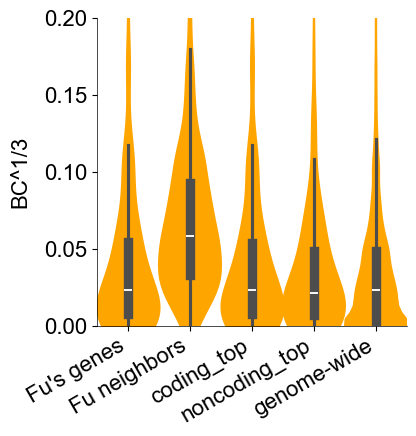

[<Figure size 400x400 with 1 Axes>, <Axes: ylabel='BC^1/3'>]

In [685]:
# betweenness centrality
for x,y in combinations(tag2genes.keys(), 2):
    group1 = df_output[df_output["group"] == x]["betweenness_centrality"]
    group2 = df_output[df_output["group"] == y]["betweenness_centrality"]
    p_value = mannwhitneyu(group1, group2, alternative="two-sided").pvalue
    print(x, " v.s. ", y, p_value)
all_function_py3.violin_plot(df_output, "group", "BC^1/3", color_dict = {x: "orange" for x in tag2genes.keys()}, ylim=(0,0.2), trunc=True, output = None, title = None, figsize=(4,4))

/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


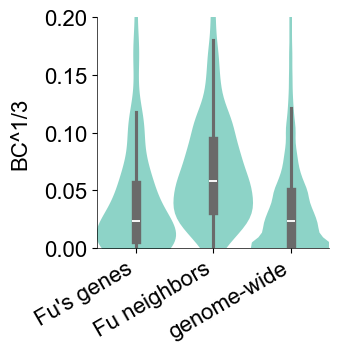

[<Figure size 300x300 with 1 Axes>, <Axes: ylabel='BC^1/3'>]

In [690]:
all_function_py3.violin_plot(df_output[df_output["group"].isin({"Fu's genes", "Fu neighbors", "genome-wide"})], "group", "BC^1/3", color_dict = {x: "#8dd3c7" for x in tag2genes.keys()}, ylim=(0,0.2), trunc=True, output = None, title = None, figsize=(3,3))

Fu's genes  v.s.  Fu neighbors 2.893184031649153e-20
Fu's genes  v.s.  coding_top 0.9306979365352401
Fu's genes  v.s.  noncoding_top 0.28741239944562125
Fu's genes  v.s.  genome-wide 0.13309819354960617
Fu neighbors  v.s.  coding_top 2.928327359030264e-21
Fu neighbors  v.s.  noncoding_top 4.12851901251631e-23
Fu neighbors  v.s.  genome-wide 1.4363327005544777e-230
coding_top  v.s.  noncoding_top 0.24245453569773812
coding_top  v.s.  genome-wide 0.09250721642254948
noncoding_top  v.s.  genome-wide 0.9500157539129155


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


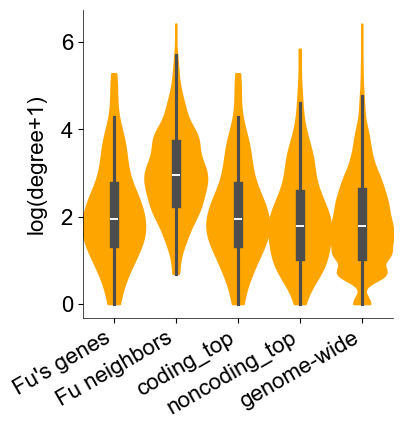

[<Figure size 400x400 with 1 Axes>, <Axes: ylabel='log(degree+1)'>]

In [694]:
# degree
for x,y in combinations(tag2genes.keys(), 2):
    group1 = df_output[df_output["group"] == x]["degree"]
    group2 = df_output[df_output["group"] == y]["degree"]
    p_value = mannwhitneyu(group1, group2, alternative="two-sided").pvalue
    print(x, " v.s. ", y, p_value)
all_function_py3.violin_plot(df_output, "group", "log(degree+1)", color_dict = {x: "orange" for x in tag2genes.keys()}, trunc=True, output = None, title = None, figsize=(4,4))

/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


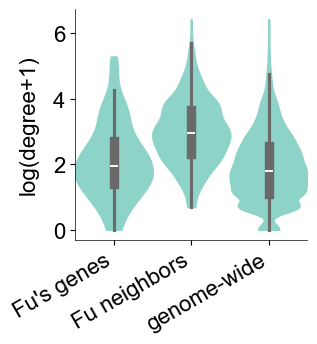

[<Figure size 300x300 with 1 Axes>, <Axes: ylabel='log(degree+1)'>]

In [693]:
all_function_py3.violin_plot(df_output[df_output["group"].isin({"Fu's genes", "Fu neighbors", "genome-wide"})], "group", "log(degree+1)", color_dict = {x: "#8dd3c7" for x in tag2genes.keys()}, trunc=True, output = None, title = None, figsize=(3,3))

Fu's genes  v.s.  Fu neighbors 9.821123645771888e-23
Fu's genes  v.s.  coding_top 0.9045996214898787
Fu's genes  v.s.  noncoding_top 0.7079285253556187
Fu's genes  v.s.  genome-wide 0.43194942593633523
Fu neighbors  v.s.  coding_top 1.0699420769215021e-23
Fu neighbors  v.s.  noncoding_top 5.225469633361922e-24
Fu neighbors  v.s.  genome-wide 7.206351691223135e-238
coding_top  v.s.  noncoding_top 0.6056334635887668
coding_top  v.s.  genome-wide 0.31876188913019354
noncoding_top  v.s.  genome-wide 0.7959755855215739


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


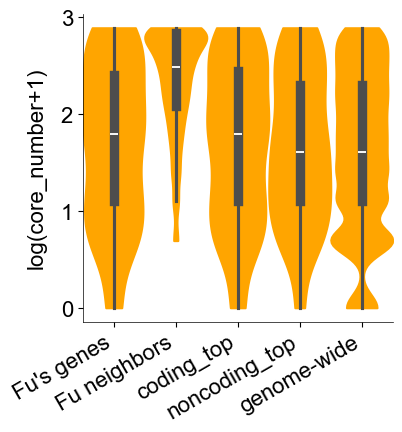

[<Figure size 400x400 with 1 Axes>, <Axes: ylabel='log(core_number+1)'>]

In [695]:
# k-core number
for x,y in combinations(tag2genes.keys(), 2):
    group1 = df_output[df_output["group"] == x]["core_number"]
    group2 = df_output[df_output["group"] == y]["core_number"]
    p_value = mannwhitneyu(group1, group2, alternative="two-sided").pvalue
    print(x, " v.s. ", y, p_value)
all_function_py3.violin_plot(df_output, "group", "log(core_number+1)", color_dict = {x: "orange" for x in tag2genes.keys()}, trunc=True, output = None, title = None, figsize=(4,4))

Fu's genes  v.s.  Fu neighbors 1.4553712596064234e-05
Fu's genes  v.s.  coding_top 0.8595281546467842
Fu's genes  v.s.  noncoding_top 0.6391989402229497
Fu's genes  v.s.  genome-wide 0.6527827368981721
Fu neighbors  v.s.  coding_top 3.741589743431424e-05
Fu neighbors  v.s.  noncoding_top 8.50302459512089e-06
Fu neighbors  v.s.  genome-wide 7.815522647684247e-49
coding_top  v.s.  noncoding_top 0.5132766205905095
coding_top  v.s.  genome-wide 0.47196544277284824
noncoding_top  v.s.  genome-wide 0.8485437892415947


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


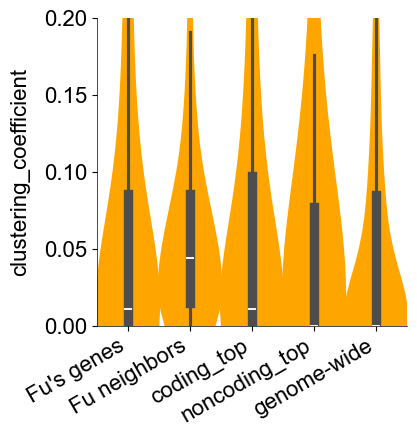

[<Figure size 400x400 with 1 Axes>, <Axes: ylabel='clustering_coefficient'>]

In [696]:
# clustering coefficient
for x,y in combinations(tag2genes.keys(), 2):
    group1 = df_output[df_output["group"] == x]["clustering_coefficient"]
    group2 = df_output[df_output["group"] == y]["clustering_coefficient"]
    p_value = mannwhitneyu(group1, group2, alternative="two-sided").pvalue
    print(x, " v.s. ", y, p_value)
all_function_py3.violin_plot(df_output, "group", "clustering_coefficient", color_dict = {x: "orange" for x in tag2genes.keys()}, trunc=True, output = None, ylim=(0,0.2), title = None, figsize=(4,4))

### local neighborhood of Fu's genes

In [821]:
# load TADA output
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
df = pd.read_csv(dr + f"FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503.txt", sep = "\t")
df

,gene,gene_id,mean_log_bf_SupTable5,std_log_bf_SupTable5,bf_SupTable5,mean_log_bf_SupTable6,std_log_bf_SupTable6,bf_SupTable6,bf.dn.em,bf.in.em,log_bf_UCSF,log_bf,bf
0,DPM1,ENSG00000000419,-0.006039,0.039695,0.993979,-0.012604,0.039796,0.987475,1.0,1.099954,0.095268,0.076625,1.079637
1,SCYL3,ENSG00000000457,-0.081336,0.155268,0.921884,-0.004858,0.121946,0.995154,1.0,1.000000,0.000000,-0.086194,0.917416
2,C1orf112,ENSG00000000460,0.229190,0.197861,1.257580,0.511479,0.249096,1.667756,1.0,1.000000,0.000000,0.740668,2.097337
3,FGR,ENSG00000000938,0.476164,0.350523,1.609888,0.616400,0.513439,1.852248,1.0,1.145065,0.135462,1.228026,3.414482
4,CFH,ENSG00000000971,0.000000,0.000000,1.000000,0.561474,0.848677,1.753255,1.0,1.000000,0.000000,0.561474,1.753255
...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,CTB-96E2.2,ENSG00000273171,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.005396,0.005382,0.005382,1.005396
18124,SNURF,ENSG00000273173,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.039427,0.038670,0.038670,1.039427
18125,CTC-432M15.3,ENSG00000273217,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.0,1.000000,0.000000,0.000000,1.000000
18126,HOXC4,ENSG00000273266,0.030376,0.046465,1.030842,0.018296,0.040622,1.018464,1.0,1.000000,0.000000,0.048672,1.049875


In [823]:
matched_random_nodes = degree_matched_sample(G, list(fu_neighbor_prots), tolerance=0, seed=None)
matched_random_genes = set(df_idmap[df_idmap["UniProt"].isin(matched_random_nodes)]["ID"])
print(len(matched_random_nodes), len(matched_random_genes), list(matched_random_genes)[:5])

1456 1221 ['APH1A', 'MAP4K4', 'SCRIB', 'SERPINH1', 'GDA']


Fu's genes v.s. Fu neighbors 1.745391165432467e-07
Fu's genes v.s. degree-matched random 1.1060786064364034e-08
Fu's genes v.s. genome-wide 2.1388674248720702e-14
Fu neighbors v.s. degree-matched random 0.3068139797777536
Fu neighbors v.s. genome-wide 6.801913001291381e-08
degree-matched random v.s. genome-wide 0.00017569094419958312


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


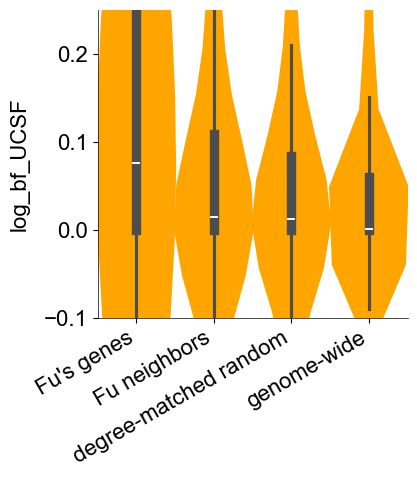

[<Figure size 400x400 with 1 Axes>, <Axes: ylabel='log_bf_UCSF'>]

In [824]:
df0 = df[df["gene"].isin(fu_genes)][["gene", "log_bf_UCSF"]]
df0["group"] = "Fu's genes"
df1 = df[df["gene"].isin(fu_neighbor_genes)][["gene", "log_bf_UCSF"]]
df1["group"] = "Fu neighbors"
df2 = df[df["gene"].isin(matched_random_genes)][["gene", "log_bf_UCSF"]]
df2["group"] = "degree-matched random"
df3 = df[["gene", "log_bf_UCSF"]].copy()
df3["group"] = "genome-wide"
df_combined = pd.concat([df0, df1, df2, df3])
for x,y in combinations(df_combined["group"].unique(), 2):
    group1 = df_combined[df_combined["group"] == x]["log_bf_UCSF"]
    group2 = df_combined[df_combined["group"] == y]["log_bf_UCSF"]
    p_value = mannwhitneyu(group1, group2, alternative="two-sided").pvalue
    print(f"{x} v.s. {y}", p_value)
all_function_py3.violin_plot(df_combined, "group", "log_bf_UCSF", color_dict = {x: "orange" for x in df_combined["group"].unique()}, trunc=True, ylim=(-0.1,0.25), output = None, title = None, figsize=(4,4))

/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


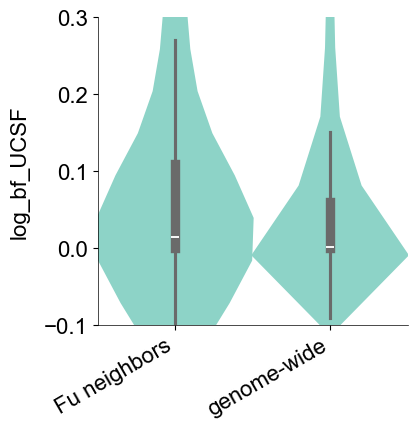

[<Figure size 400x400 with 1 Axes>, <Axes: ylabel='log_bf_UCSF'>]

In [832]:
all_function_py3.violin_plot(df_combined[df_combined["group"].isin({"Fu neighbors", "genome-wide"})], "group", "log_bf_UCSF", color_dict = {x: "#8dd3c7" for x in df_combined["group"].unique()}, trunc=False, ylim=(-0.1, 0.3), output = None, title = None, figsize=(4,4))

### bin genes by their degree / betweenness centrality / BF

In [771]:
df_tada_results[df_tada_results["FDR_TADA_ASD"]<0.05]["l10BF_ASD_Coding"].min()

np.float64(1.9530543594176837)

In [814]:
df = pd.DataFrame.from_dict(dict(G.degree()), orient='index', columns=['degree'])
df["log(degree+1)"] = df["degree"].apply(lambda x: np.log(x+1))
df = pd.merge(df, df_idmap[["UniProt", "ID"]].drop_duplicates(), left_index=True, right_on="UniProt")
df = pd.merge(df, df_tada_results[["gene_gencodeV33", "l10BF_ASD_Coding", "l10BF_ASD_EM", "FDR_TADA_ASD"]], left_on="ID", right_on="gene_gencodeV33")
df["BC^1/3"] = df["UniProt"].apply(lambda x: bc[x]**(1/3))
for x in ["degree", "BC^1/3", "l10BF_ASD_Coding", "l10BF_ASD_EM"]:
    df["bin_" + x] = pd.qcut(df[x], q=5, duplicates="drop")
df["bin_FDR_coding"] = pd.cut(df["FDR_TADA_ASD"], bins=[0, 0.05, 0.5, 1],  include_lowest=True)
print(df["bin_FDR_coding"].unique())
print(len(df["ID"].unique()))
df

[(0.5, 1.0], (-0.001, 0.05], (0.05, 0.5]]
Categories (3, interval[float64, right]): [(-0.001, 0.05] < (0.05, 0.5] < (0.5, 1.0]]
7932


,degree,log(degree+1),UniProt,ID,gene_gencodeV33,l10BF_ASD_Coding,l10BF_ASD_EM,FDR_TADA_ASD,BC^1/3,bin_degree,bin_BC^1/3,bin_l10BF_ASD_Coding,bin_l10BF_ASD_EM,bin_FDR_coding
0,105,4.663439,Q01844,EWSR1,EWSR1,0.163824,-0.021198,0.789959,0.208843,"(15.0, 612.0]","(0.055, 0.429]","(0.094, 0.299]","(-0.516, -0.00115]","(0.5, 1.0]"
1,185,5.225747,Q16543,CDC37,CDC37,0.572461,0.045180,0.574086,0.219426,"(15.0, 612.0]","(0.055, 0.429]","(0.299, 47.279]","(0.0124, 0.056]","(0.5, 1.0]"
2,150,5.017280,Q13148,TARDBP,TARDBP,0.640680,0.037128,0.538096,0.170719,"(15.0, 612.0]","(0.055, 0.429]","(0.299, 47.279]","(0.0124, 0.056]","(0.5, 1.0]"
3,49,3.912023,O43829,ZBTB14,ZBTB14,0.689987,0.011044,0.508773,0.098241,"(15.0, 612.0]","(0.055, 0.429]","(0.299, 47.279]","(0.0, 0.0124]","(0.5, 1.0]"
4,146,4.990433,P46379,BAG6,BAG6,0.000000,0.012171,0.889064,0.216998,"(15.0, 612.0]","(0.055, 0.429]","(-0.001, 0.0173]","(0.0, 0.0124]","(0.5, 1.0]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7930,2,1.098612,Q9Y3E5,PTRH2,PTRH2,0.000000,0.008246,0.908050,0.000000,"(-0.001, 2.0]","(-0.001, 0.0157]","(-0.001, 0.0173]","(0.0, 0.0124]","(0.5, 1.0]"
7931,2,1.098612,Q9Y5A9,YTHDF2,YTHDF2,0.422583,-0.029472,0.655973,0.000000,"(-0.001, 2.0]","(-0.001, 0.0157]","(0.299, 47.279]","(-0.516, -0.00115]","(0.5, 1.0]"
7932,2,1.098612,Q9Y5W7,SNX14,SNX14,0.029526,0.003678,0.861879,0.000000,"(-0.001, 2.0]","(-0.001, 0.0157]","(0.0173, 0.094]","(0.0, 0.0124]","(0.5, 1.0]"
7933,2,1.098612,Q9Y6X9,MORC2,MORC2,0.970729,0.049176,0.363896,0.000000,"(-0.001, 2.0]","(-0.001, 0.0157]","(0.299, 47.279]","(0.0124, 0.056]","(0.05, 0.5]"


(-0.001, 0.05] v.s. (0.05, 0.5] 0.7167810483739079
(0.5, 1.0] v.s. (-0.001, 0.05] 0.06478526314601173
(0.5, 1.0] v.s. (0.05, 0.5] 1.6295439057607365e-05


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


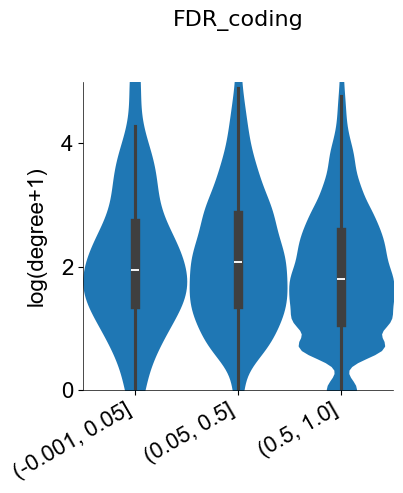

(-0.001, 0.05] v.s. (0.05, 0.5] 0.4653335155426942
(0.5, 1.0] v.s. (-0.001, 0.05] 0.3140169126957628
(0.5, 1.0] v.s. (0.05, 0.5] 0.0005807622615392439


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


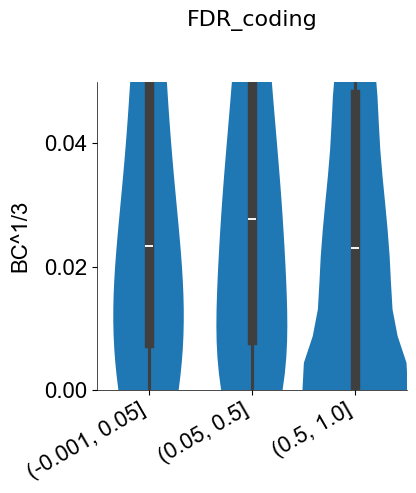

(-0.001, 0.05] v.s. (0.05, 0.5] 0.0006778606431786687
(0.5, 1.0] v.s. (-0.001, 0.05] 5.401970197822321e-10
(0.5, 1.0] v.s. (0.05, 0.5] 1.574603935900547e-06


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


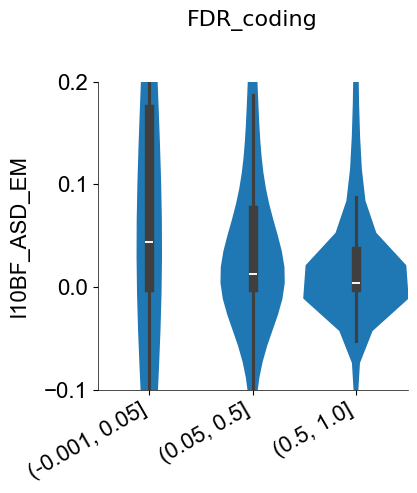

In [820]:
metric2ylim={"log(degree+1)": (0, 5), "BC^1/3": (0, 0.05), "l10BF_ASD_EM": (-0.1, 0.2)}
for bf in ["FDR_coding"]:#["l10BF_ASD_Coding", "l10BF_ASD_EM", "FDR_coding"]:
    for metric in ["log(degree+1)", "BC^1/3", "l10BF_ASD_EM"]:
        for x,y in sorted(combinations(df["bin_" + bf].unique(), 2)):
            group1 = df[df["bin_" + bf] == x][metric]
            group2 = df[df["bin_" + bf] == y][metric]
            p_value = mannwhitneyu(group1, group2, alternative="two-sided").pvalue
            print(f"{x} v.s. {y}", p_value)
        all_function_py3.violin_plot(df, "bin_" + bf, metric, color_dict = None, ylim=metric2ylim[metric], trunc=True, output = None,  title =bf, figsize=(4,4))


In [720]:
import math
print(math.e**3-1)
print(math.e**2.2-1)

19.085536923187664
8.025013499434122


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


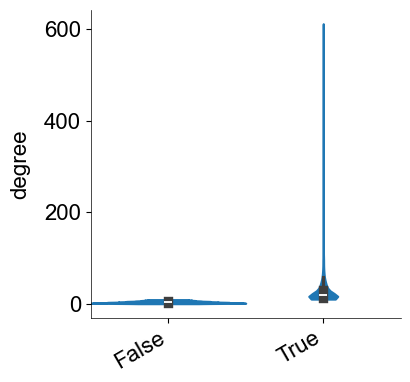

[<Figure size 400x400 with 1 Axes>, <Axes: ylabel='degree'>]

/tmp/ipykernel_240967/2901582267.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for x, df_one in df_degree.groupby("degree_bin"):
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


(-0.001, 2.0] 2408 2256 0 2
(2.0, 4.0] 1426 1356 3 4
(4.0, 7.0] 1318 1237 5 7
(7.0, 15.0] 1631 1549 8 15
(15.0, 612.0] 1618 1536 16 612
(-0.001, 2.0]  v.s.  (2.0, 4.0] 0.3789476717441552
(-0.001, 2.0]  v.s.  (4.0, 7.0] 0.12488252232599414
(-0.001, 2.0]  v.s.  (7.0, 15.0] 0.18015214846241157
(-0.001, 2.0]  v.s.  (15.0, 612.0] 0.013649506879722093
(2.0, 4.0]  v.s.  (4.0, 7.0] 0.5371422371147772
(2.0, 4.0]  v.s.  (7.0, 15.0] 0.7088451324697003
(2.0, 4.0]  v.s.  (15.0, 612.0] 0.1629411497689871
(4.0, 7.0]  v.s.  (7.0, 15.0] 0.7974247097273548
(4.0, 7.0]  v.s.  (15.0, 612.0] 0.4443423427831572
(7.0, 15.0]  v.s.  (15.0, 612.0] 0.26063379041504997


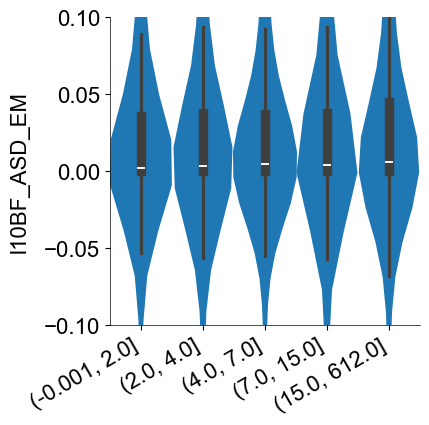

(-0.001, 2.0] 2408 2256 0 2
(2.0, 4.0] 1426 1356 3 4
(4.0, 7.0] 1318 1237 5 7
(7.0, 15.0] 1631 1549 8 15
(15.0, 612.0] 1618 1536 16 612
(-0.001, 2.0]  v.s.  (2.0, 4.0] 0.14946516098956006
(-0.001, 2.0]  v.s.  (4.0, 7.0] 0.0018284658772397327
(-0.001, 2.0]  v.s.  (7.0, 15.0] 0.01769813260987843
(-0.001, 2.0]  v.s.  (15.0, 612.0] 1.5349664239893352e-10
(2.0, 4.0]  v.s.  (4.0, 7.0] 0.13236347355821196
(2.0, 4.0]  v.s.  (7.0, 15.0] 0.4540595334036164
(2.0, 4.0]  v.s.  (15.0, 612.0] 1.5154490874422206e-05
(4.0, 7.0]  v.s.  (7.0, 15.0] 0.3977762993199715
(4.0, 7.0]  v.s.  (15.0, 612.0] 0.006474804276738816
(7.0, 15.0]  v.s.  (15.0, 612.0] 0.00016689159185090245


/tmp/ipykernel_240967/2901582267.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for x, df_one in df_degree.groupby("degree_bin"):
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


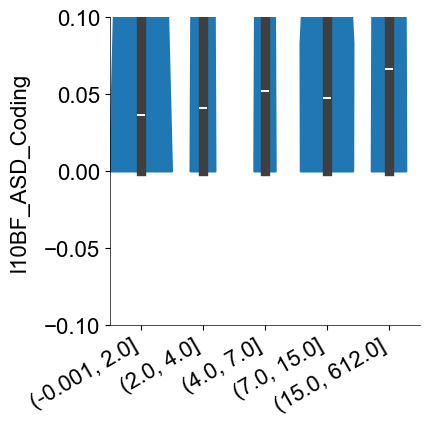

In [729]:
for col in ["l10BF_ASD_EM", "l10BF_ASD_Coding"]:
    df_plot = []
    # neighborhood noncoding BF
    for x, df_one in df_degree.groupby("degree_bin"):
        genes = set(df_idmap[df_idmap["UniProt"].isin(df_one.index)]["ID"])
        df_tmp = df_tada_results[df_tada_results["gene_gencodeV33"].isin(genes)][["gene_gencodeV33", col]]
        print(x, df_one.shape[0], df_tmp.shape[0], df_one["degree"].min(), df_one["degree"].max())
        df_tmp["tag"] = x
        df_plot.append(df_tmp)
    df_plot = pd.concat(df_plot)
    for x,y in combinations(df_plot["tag"].unique(), 2):
        group1 = df_plot[df_plot["tag"] == x][col]
        group2 = df_plot[df_plot["tag"] == y][col]
        p_value = mannwhitneyu(group1, group2, alternative="two-sided").pvalue
        print(x, " v.s. ", y, p_value)
    all_function_py3.violin_plot(df_plot, "tag", col, color_dict = None, trunc=True, output = None, ylim=(-0.1,0.1), title = None, figsize=(4,4))


In [ ]:
df_bc = pd.DataFrame.from_dict(bc, orient="index", columns=["betweenness_centrality"])
df_bc["bc_bin"] = pd.qcut(df_bc["betweenness_centrality"], q=5, duplicates="drop")
df_bc

,betweenness_centrality,bc_bin
Q01844,0.009109,"(0.000164, 0.0787]"
Q16543,0.010565,"(0.000164, 0.0787]"
Q13148,0.004976,"(0.000164, 0.0787]"
O43829,0.000948,"(0.000164, 0.0787]"
P46379,0.010218,"(0.000164, 0.0787]"
...,...,...
Q9Y3E5,0.000000,"(-0.001, 3.79e-06]"
Q9Y5A9,0.000000,"(-0.001, 3.79e-06]"
Q9Y5W7,0.000000,"(-0.001, 3.79e-06]"
Q9Y6X9,0.000000,"(-0.001, 3.79e-06]"


(-0.001, 3.79e-06] 3361 3163 0.0 3.7920952386012815e-06
(3.79e-06, 3.18e-05] 1680 1583 3.796387637668076e-06 3.1845216218665386e-05
(3.18e-05, 0.000164] 1680 1591 3.187874209235078e-05 0.00016434292668009284
(0.000164, 0.0787] 1680 1598 0.0001647919793336288 0.07870350484657598
(-0.001, 3.79e-06]  v.s.  (3.79e-06, 3.18e-05] 0.7944021477482391
(-0.001, 3.79e-06]  v.s.  (3.18e-05, 0.000164] 0.40349634778977905
(-0.001, 3.79e-06]  v.s.  (0.000164, 0.0787] 0.002794175547572985
(3.79e-06, 3.18e-05]  v.s.  (3.18e-05, 0.000164] 0.6072274185779667
(3.79e-06, 3.18e-05]  v.s.  (0.000164, 0.0787] 0.01968495757277971
(3.18e-05, 0.000164]  v.s.  (0.000164, 0.0787] 0.06188993556651085


/tmp/ipykernel_240967/1245549123.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for x, df_one in df_bc.groupby("bc_bin"):
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


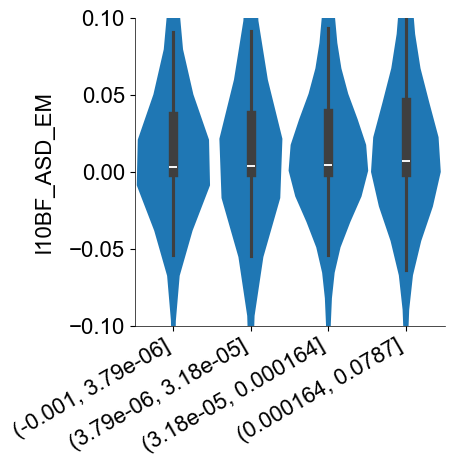

[<Figure size 400x400 with 1 Axes>, <Axes: ylabel='l10BF_ASD_EM'>]

In [ ]:
df_plot = []
# neighborhood noncoding BF
for x, df_one in df_bc.groupby("bc_bin"):
    genes = set(df_idmap[df_idmap["UniProt"].isin(df_one.index)]["ID"])
    df_tmp = df_tada_results[df_tada_results["gene_gencodeV33"].isin(genes)][["gene_gencodeV33", "l10BF_ASD_EM"]]
    print(x, df_one.shape[0], df_tmp.shape[0], df_one["betweenness_centrality"].min(), df_one["betweenness_centrality"].max())
    df_tmp["tag"] = x
    df_plot.append(df_tmp)
df_plot = pd.concat(df_plot)
for x,y in combinations(df_plot["tag"].unique(), 2):
    group1 = df_plot[df_plot["tag"] == x]["l10BF_ASD_EM"]
    group2 = df_plot[df_plot["tag"] == y]["l10BF_ASD_EM"]
    p_value = mannwhitneyu(group1, group2, alternative="two-sided").pvalue
    print(x, " v.s. ", y, p_value)
all_function_py3.violin_plot(df_plot, "tag", "l10BF_ASD_EM", color_dict = None, trunc=True, output = None, ylim=(-0.1,0.1), title = None, figsize=(4,4))


### number of connected components

In [845]:
closest_neighbor_length = []
no_connection_prots = []
for x in fu_prots.intersection(set(G.nodes())):
    length_list = []
    for y in fu_prots.intersection(set(G.nodes())):
        if x != y:
            try:
                length_list.append(nx.shortest_path_length(G, source=x, target=y))
            except:
                pass
    if len(length_list) > 0:
        closest_neighbor_length.append(min(length_list))
    else:
        print(x, "Not connected with other Fu prots in PPI")
        no_connection_prots.append(x)
print(len(no_connection_prots), np.mean(closest_neighbor_length), np.median(closest_neighbor_length))

Q99674 Not connected with other Fu prots in PPI
O95622 Not connected with other Fu prots in PPI
Q9NZB2 Not connected with other Fu prots in PPI
Q9Y4C0 Not connected with other Fu prots in PPI
Q9UPW6 Not connected with other Fu prots in PPI
Q8WXX7 Not connected with other Fu prots in PPI
O00548 Not connected with other Fu prots in PPI
P30531 Not connected with other Fu prots in PPI
O75618 Not connected with other Fu prots in PPI
9 1.8175182481751824 2.0


In [914]:
len(fu_prots.intersection(set(G.nodes())))

146

118
9168 4402
24
43.4 1.148912529307606
p-value: 0.009900990099009901


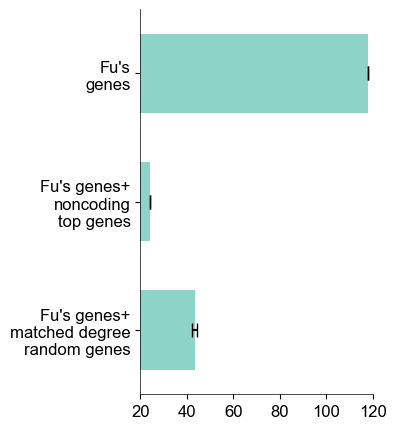

In [156]:
permu_round = 100
for cutoff in [0]:#[0, 0.1, 0.2, 0.3]:
    xtick_list = []
    y_list = []
    yerr_list = []

    # Fu's genes only
    G_sub = G.subgraph(fu_prots.intersection(set(G.nodes())))
    print(len(list(nx.connected_components(G_sub))))
    xtick_list.append("Fu's\ngenes")
    y_list.append(len(list(nx.connected_components(G_sub))))
    yerr_list.append(0)

    # select top noncoding genes by l10BF_ASD_EM
    noncoding_top_genes = set(df_tada_results[df_tada_results["l10BF_ASD_EM"]>cutoff]["gene_gencodeV33"])
    noncoding_top_prots = set(df_idmap[df_idmap["ID"].isin(noncoding_top_genes)]["UniProt"]).intersection(set(G.nodes()))
    print(len(noncoding_top_genes), len(noncoding_top_prots))

    # Fu's genes + noncoding top genes
    G_sub = G.subgraph(fu_prots.intersection(set(G.nodes())).union(noncoding_top_prots))
    retained = []
    for x in nx.connected_components(G_sub):
        if x.intersection(fu_prots) != set():
            retained.append(x)
    print(len(retained))
    test_component_num = len(retained)
    xtick_list.append("Fu's genes+\nnoncoding\ntop genes")
    y_list.append(len(retained))
    yerr_list.append(0)

    # Fu's genes + random genes
    matched_degree_component_num_list = []
    # random_component_num_list = []
    pval = 0
    for i in range(permu_round):
        random_prots = degree_matched_sample(G, noncoding_top_prots, tolerance=0, seed=None)
        G_sub = G.subgraph(fu_prots.intersection(set(G.nodes())).union(random_prots))
        retained = []
        for x in nx.connected_components(G_sub):
            if x.intersection(fu_prots) != set():
                retained.append(x)
        matched_degree_component_num_list.append(len(retained))
        if len(retained) <= test_component_num:
            pval += 1

        # random_prots = random.sample(list(G.nodes()), k=len(noncoding_top_prots))
        # G_sub = G.subgraph(fu_prots.intersection(set(G.nodes())).union(random_prots))
        # retained = []
        # for x in nx.connected_components(G_sub):
        #     if x.intersection(fu_prots) != set():
        #         retained.append(x)
        # random_component_num_list.append(len(retained))
    print(np.mean(matched_degree_component_num_list), np.std(matched_degree_component_num_list))
    xtick_list.append("Fu's genes+\nmatched degree\nrandom genes")
    y_list.append(np.mean(matched_degree_component_num_list))
    yerr_list.append(np.std(matched_degree_component_num_list))
    pval = (pval + 1) / (permu_round + 1)
    print("p-value:", pval)
    

    # print(np.mean(random_component_num_list), np.std(random_component_num_list))
    # xtick_list.append("Fu's genes+\nrandom genes")
    # y_list.append(np.mean(random_component_num_list))
    # yerr_list.append(np.std(random_component_num_list))

    all_function_py3.horizontal_bar_graph(xtick_list, y_list, x_original_2 = None, output = None, xerr_original = yerr_list, pval_list = None, figsize = (3,5), color = ["#8dd3c7"] * len(xtick_list), label = None, fontsize = 12, title = None, \
	cutoff = None, xlim = (20,120), ylim = None, invert = False, tick_bins = None, labelpad = 10, ax = None, show = True, capsize = 5, barWidth = 0.618, logbase = None)
    # bar_graph([(x,i) for i,x in enumerate(xtick_list)], y_list, color = ["#8dd3c7"] * len(xtick_list), output=None, y_err=yerr_list, title=f"l10BF_ASD_EM>{cutoff}", ylim=(20,120), xlim=None, ylabel="Number of connected components\nseeded by Fu's genes",xlabel=None, \
    #     barWidth=0.618, pval_list=None, pval_cutoff=np.inf, pval_color = "black", pval_sci = False, pval_star = False, figsize=(3,3), fontsize = 15, sci_tick = False, \
    #     log = False, xtick_rotation = 0, xtick_align_ha = "center", xtick_align_va = "top", bold = False, \
    #     xaxis_pos = None, tick_bins = None, bottom = None, capsize = 5)

In [ ]:
all_function_py3.bar_graph([(x,i) for i,x in enumerate(xtick_list)], y_list, color = ["orange"] * len(xtick_list), output=None, y_err=yerr_list, title=f"l10BF_ASD_EM>{cutoff}", ylim=(20,120), xlim=None, ylabel="Number of connected components\nseeded by Fu's genes",xlabel=None, \
        barWidth=0.618, pval_list=None, pval_cutoff=np.inf, pval_color = "black", pval_sci = False, pval_star = False, figsize=(3,3), fontsize = 15, sci_tick = False, \
        log = False, xtick_rotation = 0, xtick_align_ha = "center", xtick_align_va = "top", bold = False, \
        xaxis_pos = None, tick_bins = None, bottom = None, capsize = 5)

In [847]:
df_tada_results[df_tada_results["l10BF_ASD_EM"]>0]

,gene,gene_gencodeV33,gene_id,FDR_TADA_ASD,p_TADA_ASD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_ASD_EM,BF_ASD_PTV,BF_ASD_misB,BF_ASD_misA,BF_ASD_DEL,BF_ASD_DUP,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM,l10BF_ASD_Coding
1,NIPBL,NIPBL,ENSG00000164190,0.000010,2.290304e-08,0.000000e+00,1.586224,0.144206,0.0,3.659043,0.033117,1.000000,38.567683,1.393818,1.0,4560.822556,1.079239,264600.238103,0.000009,2.292538e-08,5.389473e+00
2,SMC3,SMC3,ENSG00000108055,0.158490,3.195632e-03,0.000000e+00,1.440559,0.000000,0.0,0.000000,0.004601,1.000000,27.577746,1.000000,1.0,1.000000,1.010650,27.871451,0.166251,4.166736e-03,1.440559e+00
4,RLF,RLF,ENSG00000117000,0.621284,6.376324e-02,4.636165e-01,0.000000,0.023187,0.0,0.000000,0.084245,2.908148,1.000000,1.054841,1.0,1.000000,1.214073,3.724332,0.577934,6.143628e-02,4.868035e-01
5,PCF11,PCF11,ENSG00000165494,0.842562,3.301800e-01,0.000000e+00,0.040708,0.023630,0.0,0.000000,0.543674,1.000000,1.098268,1.055918,1.0,1.000000,3.496826,4.055201,0.557901,5.494146e-02,6.433838e-02
6,FNDC3B,FNDC3B,ENSG00000075420,0.888480,6.175360e-01,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.293138,1.000000,1.000000,1.000000,1.0,1.000000,1.963984,1.963984,0.721989,1.471442e-01,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18100,OXER1,OXER1,ENSG00000162881,0.911012,9.991372e-01,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.015421,1.000000,1.000000,1.000000,1.0,1.000000,1.036147,1.036147,0.871031,5.828222e-01,0.000000e+00
18102,SMAD6,SMAD6,ENSG00000137834,0.591447,5.378934e-02,1.928655e-16,0.372487,0.169615,0.0,0.000000,0.086232,1.000000,2.357694,1.477798,1.0,1.000000,1.219641,4.249467,0.546856,5.168088e-02,5.421024e-01
18103,SLC10A1,SLC10A1,ENSG00000100652,0.880766,5.439653e-01,2.892982e-16,0.000000,0.000000,0.0,0.000000,0.003247,1.000000,1.000000,1.000000,1.0,1.000000,1.007506,1.007506,0.881813,6.846931e-01,2.892982e-16
18104,KRTAP5-10,KRTAP5-10,ENSG00000204572,0.911014,9.991947e-01,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.027405,1.000000,1.000000,1.000000,1.0,1.000000,1.065136,1.065136,0.862845,5.215936e-01,0.000000e+00


KeyboardInterrupt: 

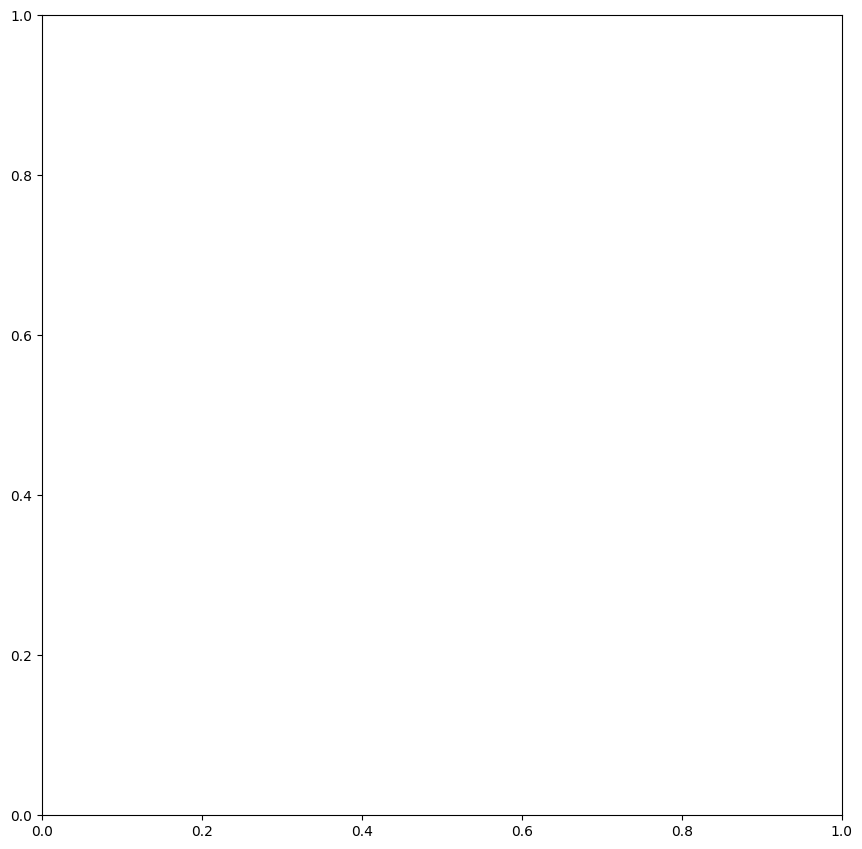

In [836]:
import networkx as nx
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

nx.draw(
    G,
    with_labels=False,
    node_size=20,
    edge_color="lightgray"
)

plt.show()

In [833]:
import random
import numpy as np
import pandas as pd
import networkx as nx
from collections import defaultdict
from itertools import combinations

def average_pairwise_shortest_path(G, nodes, disconnected="ignore"):
    """
    Compute average shortest path length among all node pairs in `nodes`.

    disconnected:
        "ignore" -> skip disconnected pairs
        "inf"    -> assign np.inf to disconnected pairs
    """
    nodes = [n for n in nodes if n in G]
    distances = []

    for u, v in combinations(nodes, 2):
        try:
            d = nx.shortest_path_length(G, u, v)
            distances.append(d)
        except nx.NetworkXNoPath:
            if disconnected == "inf":
                distances.append(np.inf)

    if len(distances) == 0:
        return np.nan

    return np.mean(distances)


def random_node_sample(G, target_nodes, seed=None):
    """
    Randomly sample the same number of nodes from the genome-wide background.
    """
    rng = random.Random(seed)

    n = len([x for x in target_nodes if x in G])
    background = list(G.nodes())

    return rng.sample(background, n)


def degree_matched_sample(G, target_nodes, tolerance=0, seed=None):
    """
    Sample background nodes matched by degree.
    Avoids sampling the original target nodes.
    """
    rng = random.Random(seed)

    degree2nodes = defaultdict(list)
    for node, deg in G.degree():
        degree2nodes[deg].append(node)

    target_nodes = [n for n in target_nodes if n in G]
    target_set = set(target_nodes)

    sampled = []
    used = set(target_nodes)

    for node in target_nodes:
        deg = G.degree(node)

        candidate_degrees = range(
            max(0, deg - tolerance),
            deg + tolerance + 1
        )

        candidates = []
        for d in candidate_degrees:
            candidates.extend(degree2nodes.get(d, []))

        candidates = [x for x in candidates if x not in used]

        if len(candidates) == 0:
            sampled.append(None)
        else:
            chosen = rng.choice(candidates)
            sampled.append(chosen)
            used.add(chosen)

    sampled = [x for x in sampled if x is not None]

    return sampled


def compare_shortest_path_to_background(
    G,
    target_nodes,
    n_iter=1000,
    background="degree_matched",
    tolerance=0,
    seed=1,
    disconnected="ignore"
):
    """
    Compare target-node average shortest path to random background.

    background:
        "random"         -> random node sets
        "degree_matched" -> degree-matched node sets
    """
    rng = random.Random(seed)

    target_nodes = [n for n in target_nodes if n in G]

    observed = average_pairwise_shortest_path(
        G,
        target_nodes,
        disconnected=disconnected
    )

    random_values = []

    for i in range(n_iter):
        iter_seed = rng.randint(0, 10**9)

        if background == "random":
            sampled_nodes = random_node_sample(
                G,
                target_nodes,
                seed=iter_seed
            )

        elif background == "degree_matched":
            sampled_nodes = degree_matched_sample(
                G,
                target_nodes,
                tolerance=tolerance,
                seed=iter_seed
            )

        else:
            raise ValueError("background must be 'random' or 'degree_matched'")

        value = average_pairwise_shortest_path(
            G,
            sampled_nodes,
            disconnected=disconnected
        )

        random_values.append(value)

    random_values = np.array(random_values, dtype=float)

    # remove NaN / inf if any
    valid_random = random_values[np.isfinite(random_values)]

    empirical_p = (np.sum(valid_random <= observed) + 1) / (len(valid_random) + 1)

    result = {
        "n_target_nodes": len(target_nodes),
        "observed_avg_shortest_path": observed,
        "background_mean": np.mean(valid_random),
        "background_sd": np.std(valid_random),
        "z_score": (observed - np.mean(valid_random)) / np.std(valid_random),
        "empirical_p_shorter_than_background": empirical_p,
        "background_values": random_values
    }

    return result

In [835]:
average_pairwise_shortest_path(G, fu_prots, disconnected="ignore")

np.float64(3.456223745301791)

In [834]:
target_nodes = list(fu_prots)

result = compare_shortest_path_to_background(
    G,
    target_nodes,
    n_iter=1000,
    background="degree_matched",
    tolerance=1,
    seed=123
)

result

KeyboardInterrupt: 

### genes with FDR>0.05 in NetFlow3D-identified significantly interconnected modules

In [467]:
module_nonsig_genes = module_genes - tada_genes
print(len(module_nonsig_genes))

64


In [468]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
df = pd.read_csv(dr + "FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503.txt", sep = "\t")
df["log_bf_coding"] = df.apply(lambda x: x["mean_log_bf_SupTable5"] + x["mean_log_bf_SupTable6"], axis = 1)
df_selected = df[df["gene"].isin(module_nonsig_genes)]
df_selected[["gene", "log_bf_coding", "log_bf_UCSF"]]

,gene,log_bf_coding,log_bf_UCSF
195,CELSR3,1.764028,-0.014980
482,VCL,1.889808,0.150206
588,HDAC9,0.058333,1.191787
738,ZC3H11A,0.720962,0.000000
914,MPPED2,0.289710,1.461834
...,...,...,...
15803,SIPA1L1,0.388540,0.785415
15837,SPTAN1,2.656489,0.244016
16358,EHMT2,1.583200,0.030436
16794,LBH,0.000246,0.124721


In [469]:
df.head()

,gene,gene_id,mean_log_bf_SupTable5,std_log_bf_SupTable5,bf_SupTable5,mean_log_bf_SupTable6,std_log_bf_SupTable6,bf_SupTable6,bf.dn.em,bf.in.em,log_bf_UCSF,log_bf,bf,log_bf_coding
0,DPM1,ENSG00000000419,-0.006039,0.039695,0.993979,-0.012604,0.039796,0.987475,1.0,1.099954,0.095268,0.076625,1.079637,-0.018644
1,SCYL3,ENSG00000000457,-0.081336,0.155268,0.921884,-0.004858,0.121946,0.995154,1.0,1.000000,0.000000,-0.086194,0.917416,-0.086194
2,C1orf112,ENSG00000000460,0.229190,0.197861,1.257580,0.511479,0.249096,1.667756,1.0,1.000000,0.000000,0.740668,2.097337,0.740668
3,FGR,ENSG00000000938,0.476164,0.350523,1.609888,0.616400,0.513439,1.852248,1.0,1.145065,0.135462,1.228026,3.414482,1.092564
4,CFH,ENSG00000000971,0.000000,0.000000,1.000000,0.561474,0.848677,1.753255,1.0,1.000000,0.000000,0.561474,1.753255,0.561474


Slope: -0.257, Intercept: 0.661, R: -0.379, p-value: 2.18e-03


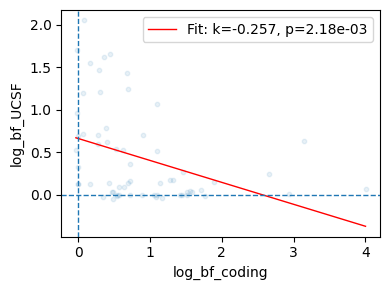

In [474]:
bf_scatter_plot(df_selected, "log_bf_coding", "log_bf_UCSF", figsize=(4,3), xlim=None, title=None)

,gene,log_bf,type
0,DPM1,-0.018644,coding
1,SCYL3,-0.086194,coding
2,C1orf112,0.740668,coding
3,FGR,1.092564,coding
4,CFH,0.561474,coding


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


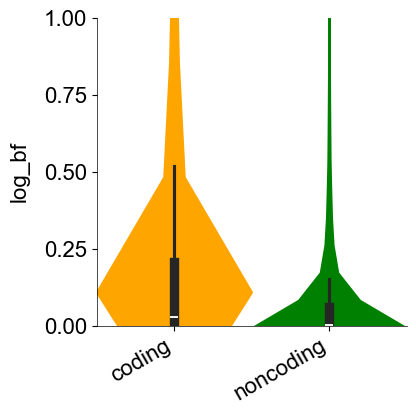

[<Figure size 400x400 with 1 Axes>, <Axes: ylabel='log_bf'>]

In [471]:
df_coding = df[["gene", "log_bf_coding"]].rename(columns={"log_bf_coding": "log_bf"})
df_coding["type"] = "coding"
df_noncoding = df[["gene", "log_bf_UCSF"]].rename(columns={"log_bf_UCSF": "log_bf"})
df_noncoding["type"] = "noncoding"
df_combined = pd.concat([df_coding, df_noncoding])
display(df_combined.head())
all_function_py3.violin_plot(df_combined, "type", "log_bf", color_dict={"coding": "orange", "noncoding": "green"}, trunc=False, ylim=(0,1), output=None, title=None, figsize=(4,4))

/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


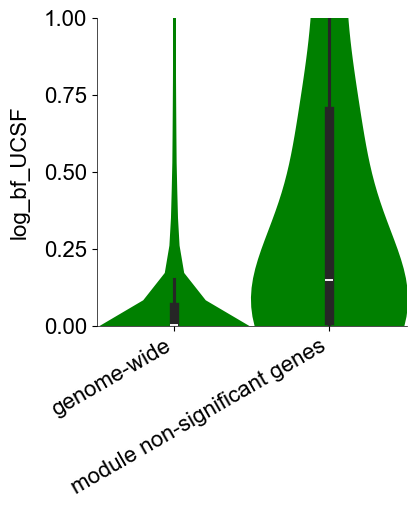

[<Figure size 400x400 with 1 Axes>, <Axes: ylabel='log_bf_UCSF'>]

In [472]:
df_genome = df.copy()
df_genome["type"] = "genome-wide"
df_selected = df[df["gene"].isin(module_nonsig_genes)].copy()
df_selected["type"] = "module non-significant genes"
df_combined = pd.concat([df_genome, df_selected])
all_function_py3.violin_plot(df_combined, "type", "log_bf_UCSF", color_dict={"genome-wide": "green", "module non-significant genes": "green"}, trunc=False, ylim=(0,1), output=None, title=None, figsize=(4,4))

/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


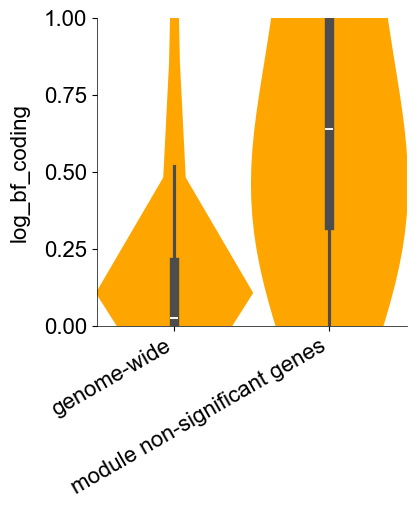

[<Figure size 400x400 with 1 Axes>, <Axes: ylabel='log_bf_coding'>]

In [473]:
df_genome = df.copy()
df_genome["type"] = "genome-wide"
df_selected = df[df["gene"].isin(module_nonsig_genes)].copy()
df_selected["type"] = "module non-significant genes"
df_combined = pd.concat([df_genome, df_selected])
all_function_py3.violin_plot(df_combined, "type", "log_bf_coding", color_dict={"genome-wide": "orange", "module non-significant genes": "orange"}, trunc=False, ylim=(0,1), output=None, title=None, figsize=(4,4))

In [378]:
10 ** 0.1907978893847512

1.5516647329981483

## box plot (in_floor=FALSE, 260503, 100kb)

In [164]:
disrupted_ppi_tag = "Interface_DN"
tada_tag = f"TADA_coding_FuRawSup11_noncoding_UCSF_Combined_Simple_roulette_rd_control_formatted_260503_infloorFALSE_ScaleByLOEUF"
file_tag = f"InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503_{disrupted_ppi_tag}_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5"

# jaccard_analysis(tada_output_path, netflow3d_output_path, analysis_path, figure_path, tada_tag, file_tag, df_idmap_slim, df_idmap, title=f"{disrupted_ppi_tag}", size_cutoff=5, permutation_round = 100, fdr_col="FDR_TADA_ASD_AddEM")

/Genomics/argo/users/yz8667/src/all_function_py3.py:3904: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = put_x, y = put_y, data = df, palette = boxcolor, linewidth = 1.5, saturation = 1, width = barWidth, ax = ax, \
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


8 800 800


/Genomics/argo/users/yz8667/src/all_function_py3.py:3941: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x.get_text() for x in ax.get_xticklabels()], fontproperties = prop)
/Genomics/argo/users/yz8667/src/all_function_py3.py:3942: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([x.get_text() for x in ax.get_yticklabels()], rotation = tick_rotation, ha = tick_align, fontproperties = prop)


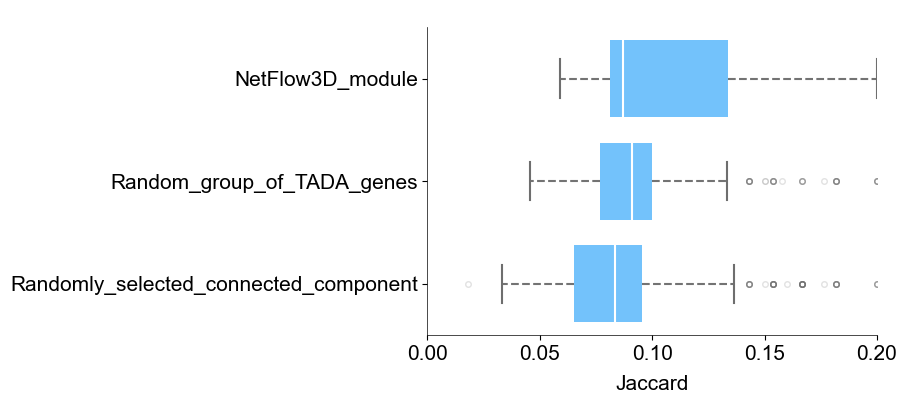

/tmp/ipykernel_3705737/1411777295.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels, fontproperties = prop)


,Set1,Set2,Stat,Pvalue
2,Random_group_of_TADA_genes,Randomly_selected_connected_component,360865.0,0.000004
1,NetFlow3D_module,Randomly_selected_connected_component,3952.0,0.125360
0,NetFlow3D_module,Random_group_of_TADA_genes,3642.0,0.249082


,Set1,Set2,Stat,Pvalue
2,Random_group_of_TADA_genes,Randomly_selected_connected_component,360865.0,0.000004
1,NetFlow3D_module,Randomly_selected_connected_component,3952.0,0.125360
0,NetFlow3D_module,Random_group_of_TADA_genes,3642.0,0.249082


In [165]:
jaccard_analysis(tada_output_path, netflow3d_output_path, analysis_path, figure_path, tada_tag, file_tag, df_idmap_slim, df_idmap, title=f"{disrupted_ppi_tag}", size_cutoff=5, permutation_round = 100, fdr_col="FDR_TADA_ASD_AddEM")

In [167]:
disrupted_ppi_tag = "Interface_DN"
tada_tag = f"TADA_coding_FuRawSup11_noncoding_UCSF_Combined_Simple_roulette_rd_control_formatted_260503_infloorFALSE_ScaleByLOEUF"
file_tag = f"InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_infloorFALSE_TADA_output_260503_{disrupted_ppi_tag}_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew1_rp0.5"

jaccard_analysis(tada_output_path, netflow3d_output_path, analysis_path, figure_path, tada_tag, file_tag, df_idmap_slim, df_idmap, title=f"{disrupted_ppi_tag}", size_cutoff=5, permutation_round = 100, fdr_col="FDR_TADA_ASD_AddEM")

Number of proteins in NetFlow3D subnetworks: 80
Number of subnetworks: 8
Number of subnetwork proteins: 80
Number of TADA canonical proteins: 80
First 5 TADA canonical proteins: ['Q7Z3K3', 'P53680', 'Q6VY07', 'Q9UPW6', 'P21359']


NameError: name 'ID_conversion' is not defined

## box plot (260503, 100kb)

Number of proteins in NetFlow3D subnetworks: 91
Number of subnetworks: 10
Number of subnetwork proteins: 91
Number of TADA canonical proteins: 91
First 5 TADA canonical proteins: ['Q02548', 'Q9H2P0', 'Q14119', 'P12755', 'P42336']
round 1
round 2
round 3
round 4
round 5
round 6
round 7
round 8
round 9
round 10
round 11
round 12
round 13
round 14
round 15
round 16
round 17
round 18
round 19
round 20
round 21
round 22
round 23
round 24
round 25
round 26
round 27
round 28
round 29
round 30
round 31
round 32
round 33
round 34
round 35
round 36
round 37
round 38
round 39
round 40
round 41
round 42
round 43
round 44
round 45
round 46
round 47
round 48
round 49
round 50
round 51
round 52
round 53
round 54
round 55
round 56
round 57
round 58
round 59
round 60
round 61
round 62
round 63
round 64
round 65
round 66
round 67
round 68
round 69
round 70
round 71
round 72
round 73
round 74
round 75
round 76
round 77
round 78
round 79
round 80
round 81
round 82
round 83
round 84
round 85
round 86
round

/Genomics/argo/users/yz8667/src/all_function_py3.py:3904: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = put_x, y = put_y, data = df, palette = boxcolor, linewidth = 1.5, saturation = 1, width = barWidth, ax = ax, \
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


10 1000 1000


/Genomics/argo/users/yz8667/src/all_function_py3.py:3941: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x.get_text() for x in ax.get_xticklabels()], fontproperties = prop)
/Genomics/argo/users/yz8667/src/all_function_py3.py:3942: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([x.get_text() for x in ax.get_yticklabels()], rotation = tick_rotation, ha = tick_align, fontproperties = prop)


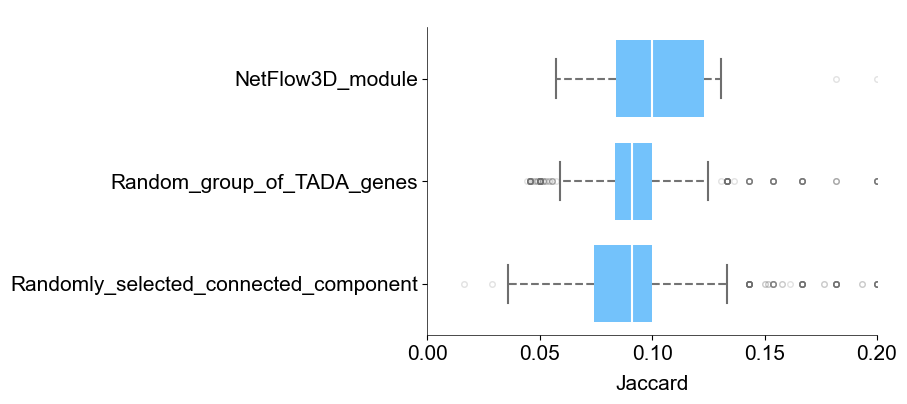

/tmp/ipykernel_1777374/1411777295.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels, fontproperties = prop)


,Set1,Set2,Stat,Pvalue
2,Random_group_of_TADA_genes,Randomly_selected_connected_component,524279.5,0.028537
1,NetFlow3D_module,Randomly_selected_connected_component,6223.0,0.089493
0,NetFlow3D_module,Random_group_of_TADA_genes,6136.5,0.104346


,Set1,Set2,Stat,Pvalue
2,Random_group_of_TADA_genes,Randomly_selected_connected_component,524279.5,0.028537
1,NetFlow3D_module,Randomly_selected_connected_component,6223.0,0.089493
0,NetFlow3D_module,Random_group_of_TADA_genes,6136.5,0.104346


In [313]:
disrupted_ppi_tag = "Interface_DN"
tada_tag = f"TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaledByLOEUF_260503"
file_tag = f"InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_260503_{disrupted_ppi_tag}_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5"

jaccard_analysis(tada_output_path, netflow3d_output_path, analysis_path, figure_path, tada_tag, file_tag, df_idmap_slim, df_idmap, title=f"{disrupted_ppi_tag}", size_cutoff=5, permutation_round = 100, fdr_col="FDR_TADA_ASD_AddEM")

## box plot (old, 50kb+100kb)

Number of proteins in NetFlow3D subnetworks: 92
Number of subnetworks: 10
Number of subnetwork proteins: 92
Number of TADA canonical proteins: 92
First 5 TADA canonical proteins: ['Q02548', 'Q9H2P0', 'Q14119', 'P12755', 'P42336']
round 1
round 2
round 3
round 4
round 5
round 6
round 7
round 8
round 9
round 10
round 11
round 12
round 13
round 14
round 15
round 16
round 17
round 18
round 19
round 20
round 21
round 22
round 23
round 24
round 25
round 26
round 27
round 28
round 29
round 30
round 31
round 32
round 33
round 34
round 35
round 36
round 37
round 38
round 39
round 40
round 41
round 42
round 43
round 44
round 45
round 46
round 47
round 48
round 49
round 50
round 51
round 52
round 53
round 54
round 55
round 56
round 57
round 58
round 59
round 60
round 61
round 62
round 63
round 64
round 65
round 66
round 67
round 68
round 69
round 70
round 71
round 72
round 73
round 74
round 75
round 76
round 77
round 78
round 79
round 80
round 81
round 82
round 83
round 84
round 85
round 86
round

/Genomics/argo/users/yz8667/src/all_function_py3.py:3904: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = put_x, y = put_y, data = df, palette = boxcolor, linewidth = 1.5, saturation = 1, width = barWidth, ax = ax, \
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


10 1000 1000


/Genomics/argo/users/yz8667/src/all_function_py3.py:3941: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x.get_text() for x in ax.get_xticklabels()], fontproperties = prop)
/Genomics/argo/users/yz8667/src/all_function_py3.py:3942: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([x.get_text() for x in ax.get_yticklabels()], rotation = tick_rotation, ha = tick_align, fontproperties = prop)


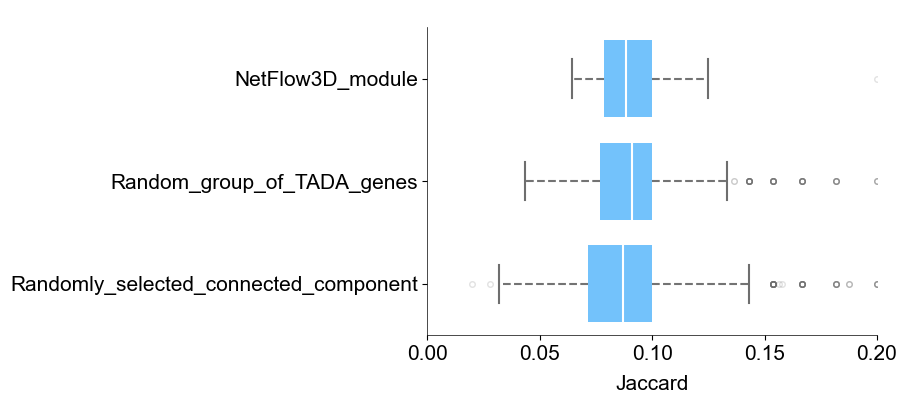

/tmp/ipykernel_1777374/1411777295.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels, fontproperties = prop)


,Set1,Set2,Stat,Pvalue
2,Random_group_of_TADA_genes,Randomly_selected_connected_component,546173.5,0.000157
1,NetFlow3D_module,Randomly_selected_connected_component,5667.0,0.232592
0,NetFlow3D_module,Random_group_of_TADA_genes,5168.5,0.426657


,Set1,Set2,Stat,Pvalue
2,Random_group_of_TADA_genes,Randomly_selected_connected_component,546173.5,0.000157
1,NetFlow3D_module,Randomly_selected_connected_component,5667.0,0.232592
0,NetFlow3D_module,Random_group_of_TADA_genes,5168.5,0.426657


In [316]:
disrupted_ppi_tag = "Interface_DN"
tada_tag = f"TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaleByLOEUF"
file_tag = f"InhAll_DNVAll_FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_{disrupted_ppi_tag}_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5"

jaccard_analysis(tada_output_path, netflow3d_output_path, analysis_path, figure_path, tada_tag, file_tag, df_idmap_slim, df_idmap, title=f"{disrupted_ppi_tag}", size_cutoff=5, permutation_round = 100, fdr_col="FDR_TADA_ASD_AddEM")

## box plot (FuScaled instead of Fu Downsampled)

Number of proteins in NetFlow3D subnetworks: 105
Number of subnetworks: 10
Number of subnetwork proteins: 105
Number of TADA canonical proteins: 105


/Genomics/argo/users/yz8667/src/all_function_py3.py:3904: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = put_x, y = put_y, data = df, palette = boxcolor, linewidth = 1.5, saturation = 1, width = barWidth, ax = ax, \
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


10 1000 1000


/Genomics/argo/users/yz8667/src/all_function_py3.py:3941: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x.get_text() for x in ax.get_xticklabels()], fontproperties = prop)
/Genomics/argo/users/yz8667/src/all_function_py3.py:3942: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([x.get_text() for x in ax.get_yticklabels()], rotation = tick_rotation, ha = tick_align, fontproperties = prop)


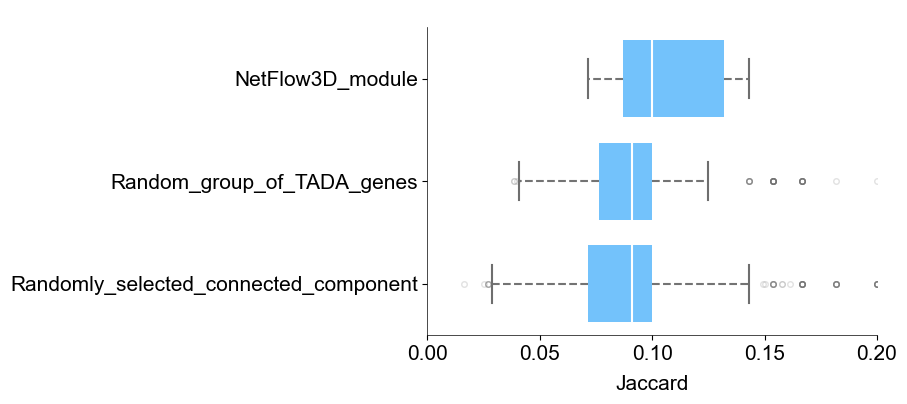

/tmp/ipykernel_164670/1411777295.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels, fontproperties = prop)


,Set1,Set2,Stat,Pvalue
2,Random_group_of_TADA_genes,Randomly_selected_connected_component,504094.5,0.374074
1,NetFlow3D_module,Randomly_selected_connected_component,6508.5,0.048802
0,NetFlow3D_module,Random_group_of_TADA_genes,6592.0,0.038614


,Set1,Set2,Stat,Pvalue
2,Random_group_of_TADA_genes,Randomly_selected_connected_component,504094.5,0.374074
1,NetFlow3D_module,Randomly_selected_connected_component,6508.5,0.048802
0,NetFlow3D_module,Random_group_of_TADA_genes,6592.0,0.038614


In [ ]:
method_tag = "ScaleByLOEUF"
coding_cohort_tag = "coding_FuScaled_ASC+SSC"
sample_tag = "Combined_Simple"
disrupted_ppi_tag = "Interface_DN"

tada_tag = f"TADA_{coding_cohort_tag}_rounded_{sample_tag}_Roulette_MR_{method_tag}"
file_tag = f"InhAll_DNVAll_{tada_tag}_{disrupted_ppi_tag}_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5"

jaccard_analysis(tada_output_path, netflow3d_output_path, analysis_path, figure_path, tada_tag, file_tag, df_idmap_slim, df_idmap, title=f"{sample_tag},{disrupted_ppi_tag}", size_cutoff=5, permutation_round = 100)

## violin and bar plot

### (FuScaled coding + UCSF noncoding)

/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/analysis/..//data/TADA/output/InhAll_DNVAll/TADA_coding_FuScaled_ASC+SSC_rounded_CodingOnly_Roulette_MR_ScaleByLOEUF.txt
coding: total genes = 56, last genes = 0, unique genes = 56
/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/analysis/..//data/TADA/output/InhAll_DNVAll/TADA_coding_FuScaled_ASC+SSC_rounded_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt
coding+noncoding: total genes = 72, last genes = 56, unique genes = 18
/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/analysis/..//data/NetFlow3D/output/InhAll_DNVAll_TADA_coding_FuScaled_ASC+SSC_rounded_Combined_Simple_Roulette_MR_ScaleByLOEUF_Interface_DN_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew1_rp0.5_subnetworks.txt
Number of subnetworks: 9
coding+noncoding+network: total genes = 99, last genes = 72, unique genes = 90
/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/an

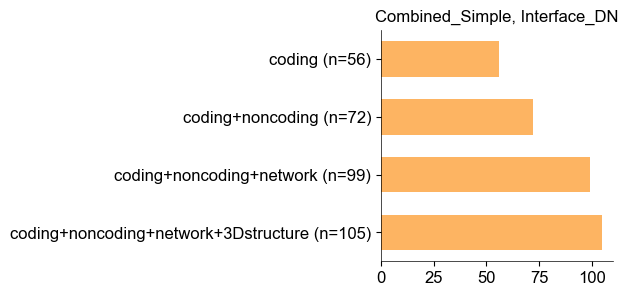

before haploinsufficiency annotation: 18971
after haploinsufficiency annotation: 11588


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


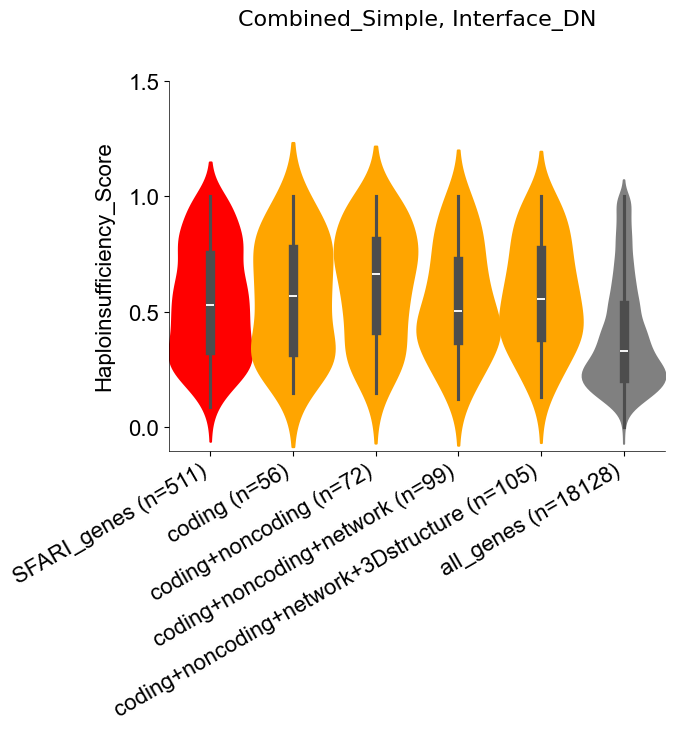

,group_x,group_y,pval
0,SFARI_genes (n=511),coding (n=56),6.503081e-01
1,SFARI_genes (n=511),coding+noncoding (n=72),3.499509e-02
2,SFARI_genes (n=511),coding+noncoding+network (n=99),9.821409e-01
3,SFARI_genes (n=511),coding+noncoding+network+3Dstructure (n=105),3.455454e-01
4,SFARI_genes (n=511),all_genes (n=18128),1.192437e-32
5,coding (n=56),coding+noncoding (n=72),2.773338e-01
6,coding (n=56),coding+noncoding+network (n=99),6.964678e-01
7,coding (n=56),coding+noncoding+network+3Dstructure (n=105),8.141256e-01
8,coding (n=56),all_genes (n=18128),6.259644e-06
9,coding+noncoding (n=72),coding+noncoding+network (n=99),7.462401e-02


before haploinsufficiency annotation (unique): 18818
after haploinsufficiency annotation (unique): 11473


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


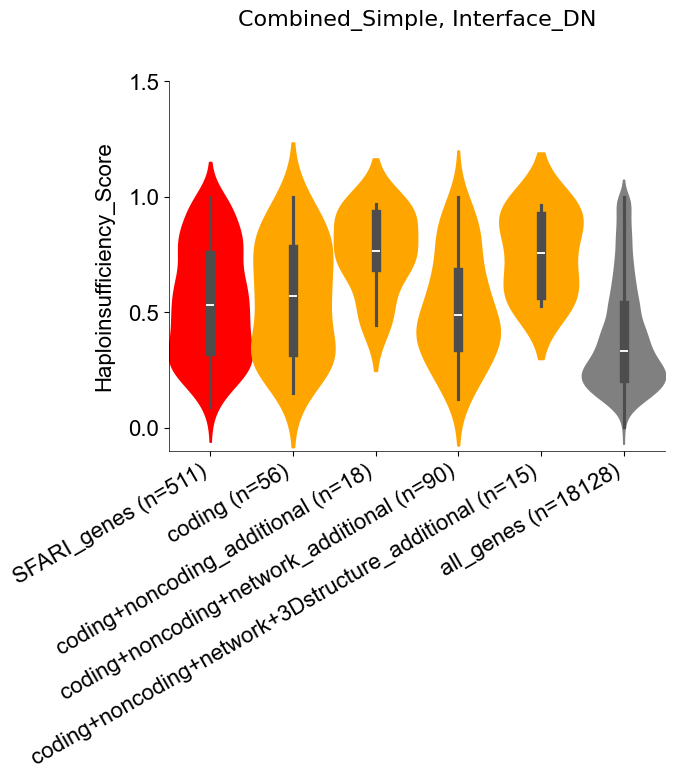

,group_x,group_y,pval
0,SFARI_genes (n=511),coding (n=56),6.503081e-01
1,SFARI_genes (n=511),coding+noncoding_additional (n=18),5.167932e-04
2,SFARI_genes (n=511),coding+noncoding+network_additional (n=90),5.199574e-01
3,SFARI_genes (n=511),coding+noncoding+network+3Dstructure_additiona...,1.071013e-02
4,SFARI_genes (n=511),all_genes (n=18128),1.192437e-32
5,coding (n=56),coding+noncoding_additional (n=18),7.242778e-03
6,coding (n=56),coding+noncoding+network_additional (n=90),4.347756e-01
7,coding (n=56),coding+noncoding+network+3Dstructure_additiona...,3.977301e-02
8,coding (n=56),all_genes (n=18128),6.259644e-06
9,coding+noncoding_additional (n=18),coding+noncoding+network_additional (n=90),2.584776e-04


In [35]:
coding_cohort_tag = "coding_FuScaled_ASC+SSC"
method_tag = "ScaleByLOEUF"
sample_tag = "Combined_Simple"
disrupted_ppi_tag = "Interface_DN"
tag2file = {"coding": tada_output_path + f"TADA_{coding_cohort_tag}_rounded_CodingOnly_Roulette_MR_{method_tag}.txt",
            "coding+noncoding": tada_output_path + f"TADA_{coding_cohort_tag}_rounded_{sample_tag}_Roulette_MR_{method_tag}.txt",
            "coding+noncoding+network": netflow3d_output_path + f"InhAll_DNVAll_TADA_{coding_cohort_tag}_rounded_{sample_tag}_Roulette_MR_{method_tag}_{disrupted_ppi_tag}_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew1_rp0.5_subnetworks.txt",
            "coding+noncoding+network+3Dstructure": netflow3d_output_path + f"InhAll_DNVAll_TADA_{coding_cohort_tag}_rounded_{sample_tag}_Roulette_MR_{method_tag}_{disrupted_ppi_tag}_HomoSapiens_binary_HINThq_fetal_frontal_cortex_expressed_genes_TPM0.1_ew5_rp0.5_subnetworks.txt"}
df_output, df_unique = netflow3d_analysis(tag2file, df_idmap, df_haplo, asd_genes, all_genes, title = f"{sample_tag}, {disrupted_ppi_tag}")